# 0. 필요 패키지 로드

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
!sudo apt-get install -y fonts-nanum
!sudo fc-cache -fv
!rm ~/.cache/matplotlib -rf

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
fonts-nanum is already the newest version (20200506-1).
0 upgraded, 0 newly installed, 0 to remove and 19 not upgraded.
/usr/share/fonts: caching, new cache contents: 0 fonts, 1 dirs
/usr/share/fonts/truetype: caching, new cache contents: 0 fonts, 3 dirs
/usr/share/fonts/truetype/humor-sans: caching, new cache contents: 1 fonts, 0 dirs
/usr/share/fonts/truetype/liberation: caching, new cache contents: 16 fonts, 0 dirs
/usr/share/fonts/truetype/nanum: caching, new cache contents: 12 fonts, 0 dirs
/usr/local/share/fonts: caching, new cache contents: 0 fonts, 0 dirs
/root/.local/share/fonts: skipping, no such directory
/root/.fonts: skipping, no such directory
/usr/share/fonts/truetype: skipping, looped directory detected
/usr/share/fonts/truetype/humor-sans: skipping, looped directory detected
/usr/share/fonts/truetype/liberation: skipping, looped directory detected
/usr/share/fonts/truetype/

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pandas.io.excel import read_excel

## 전체 파일 읽기
from glob import glob

# dbf 파일 읽기
!pip install dbfread
from dbfread import DBF

## 거리계산
!pip install haversine
from haversine import haversine

## 위경도 변환
from pyproj import Proj, transform
import pyproj

# 구글맵 설치
!pip install googlemaps

# 주소 변환에 필요한 패키지
import googlemaps
from tqdm import tqdm

## json 파일 불러오기
import os
import requests
import json

## 지도 그리기
!pip install folium
import folium

## plt 한글폰트 지정
plt.rcParams['font.family'] = 'NanumGothic'

from scipy import stats

In [4]:
%matplotlib inline
import re
import openpyxl

!pip install tabulate
from tabulate import tabulate
import math
from sklearn.cluster import KMeans
from sklearn import preprocessing
import warnings
warnings.filterwarnings('ignore')
import geopandas as gpd

## 모델 적합용 데이터 전처리 관련 라이브러리
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE
from sklearn.impute import KNNImputer
from statsmodels.stats.outliers_influence import variance_inflation_factor#다중공선성

## 모델 생성 및 성능평가 라이브러리
from xgboost import XGBClassifier
import xgboost as xgb
from xgboost import plot_importance ## Feature Importance를 불러오기 위함
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from lightgbm import LGBMClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score
from sklearn.metrics import f1_score, roc_auc_score
from sklearn.metrics import classification_report
from sklearn.metrics import mean_squared_error
import warnings
warnings.filterwarnings('ignore')

## DNN 관련 라이브러리
from tensorflow.keras.layers import Dense,SimpleRNN,LSTM,Dropout
from tensorflow.keras import models
from tensorflow.keras import layers,optimizers
import os
from tensorflow.keras.callbacks import ModelCheckpoint,EarlyStopping
from tensorflow.keras.models import load_model
import keras
from sklearn import svm
from sklearn import metrics

# 1. 원본 제공 데이터

In [ ]:
df = pd.read_csv('/content/drive/MyDrive/2023 빅콘테스트/데이터/필지단위 소상공인 매출등급 정보.csv')

# 2. 추가 수집 데이터

## 1. 배후지 인구당 상가면적

In [ ]:
# 분기별 데이터를 이용해 나머지 월을 채워주는 코드
file_names = glob("/content/drive/MyDrive/2023 빅콘테스트/데이터/배후지 인구당 상가면적(분기별)/*.csv") #폴더 내의 모든 csv파일 목록을 불러온다
total = pd.DataFrame() #빈 데이터프레임 하나를 생성한다

for file_name in file_names:
    temp = pd.read_csv(file_name, sep='|')
    res = pd.read_csv(file_name, sep='|')
    for i in range(2):   # 1분기라면 3월 데이터만 있으니까 3월 값을 그대로 갖는 1월 2월 데이터를 추가하는 과정
      if '20221' in file_name:           # 22년 1분기 데이터
        res.loc[:, 'data_strd_ym'] = 202201+i # 3월을 1월, 2월로 변경
        temp = pd.concat([temp, res])
      elif '20222' in file_name:          # 22년 2분기 데이터
        res.loc[:, 'data_strd_ym'] = 202204+i
        temp = pd.concat([temp, res])
      elif '20223' in file_name:
        res.loc[:, 'data_strd_ym'] = 202207+i
        temp = pd.concat([temp, res])
      elif '20224' in file_name:
        res.loc[:, 'data_strd_ym'] = 202210+i
        temp = pd.concat([temp, res])
      elif '20231' in file_name:
        res.loc[:, 'data_strd_ym'] = 202301+i
        temp = pd.concat([temp, res])
    total = pd.concat([total, temp])

In [ ]:
total

,data_strd_ym,pnu,legaldong_cd,induty_cd,pul_party_sopsrt_dims
0,202203,1111010100100010000,11110101,C05,0.48
1,202203,1111010100100030100,11110101,A03,0.47
2,202203,1111010100100420003,11110101,C03,0.35
3,202203,1111010100100480000,11110101,A01,1.40
4,202203,1111010100100500031,11110101,C05,4.79
...,...,...,...,...,...
1095245,202302,5013032026104680001,50130320,A03,8.37
1095246,202302,5013032026105370003,50130320,A01,16.54
1095247,202302,5013032026108360001,50130320,A01,34.71
1095248,202302,5013032026113660001,50130320,A01,2.58


In [ ]:
total.sort_values('data_strd_ym', inplace=True)
total.columns = ['DATA_CRTR_YM', 'LT_UNQ_NO', 'STDG_EMD_CD', 'INDUSTRY_CD', 'pul_party_sopsrt_dims'] # 원본 데이터 df와 merge하기 위해 컬럼명 변경

In [ ]:
df1 = pd.merge(df, total, how='left')
df1.head() # 원본 데이터 + 배후지 인구당 상가면적인 데이터 df1 생성

,DATA_CRTR_YM,LT_UNQ_NO,STDG_EMD_CD,INDUSTRY_CD,SLS_GRD,pul_party_sopsrt_dims
0,202201,1111010100100030100,11110101,A03,4,0.47
1,202201,1111010100100480000,11110101,A01,2,1.40
2,202201,1111010100100590001,11110101,A11,3,0.34
3,202201,1111010100100590005,11110101,A03,2,0.15
4,202201,1111010100100690000,11110101,A01,2,1.75


## 2. 부동산거래량대비유동인구

In [ ]:
# 분기별 데이터를 이용해 나머지 월을 채워주는 코드
file_names = glob("/content/drive/MyDrive/빅콘테스트/데이터/부동산거래량 (금액)대비 유동인구/*.csv") #폴더 내의 모든 csv파일 목록을 불러온다
total = pd.DataFrame() #빈 데이터프레임 하나를 생성한다

for file_name in file_names:
    temp = pd.read_csv(file_name, sep='|')
    res = pd.read_csv(file_name, sep='|')
    for i in range(2):
      if '20221' in file_name:   # 22년 1분기 데이터
        res.loc[:, 'data_strd_ym'] = 202201+i  # 3월을 1월과 2월 데이터로 만들어준다.
        temp = pd.concat([temp, res])
      elif '20222' in file_name:
        res.loc[:, 'data_strd_ym'] = 202204+i
        temp = pd.concat([temp, res])
      elif '20223' in file_name:
        res.loc[:, 'data_strd_ym'] = 202207+i
        temp = pd.concat([temp, res])
      elif '20224' in file_name:
        res.loc[:, 'data_strd_ym'] = 202210+i
        temp = pd.concat([temp, res])
      elif '20231' in file_name:
        res.loc[:, 'data_strd_ym'] = 202301+i
        temp = pd.concat([temp, res])
    total = pd.concat([total, temp])

In [ ]:
total.sort_values('data_strd_ym', inplace=True)
total.columns = ['DATA_CRTR_YM', 'LT_UNQ_NO', 'STDG_EMD_CD', 'INDUSTRY_CD', 'fpop_scor_property'] # df1과 merge하기 위해 컬럼명 변경

In [ ]:
df2 = pd.merge(df1, total, how='left', on=['DATA_CRTR_YM', 'LT_UNQ_NO', 'STDG_EMD_CD', 'INDUSTRY_CD'])
df2 # df1 + 부동산거래량대비유동인구인 데이터 df2 생성

,DATA_CRTR_YM,LT_UNQ_NO,STDG_EMD_CD,INDUSTRY_CD,SLS_GRD,pul_party_sopsrt_dims,fpop_scor_property
0,202201,1111010100100030100,11110101,A03,4,0.47000,19.76000
1,202201,1111010100100480000,11110101,A01,2,1.40000,39.13000
2,202201,1111010100100590001,11110101,A11,3,0.34000,27.26000
3,202201,1111010100100590005,11110101,A03,2,0.15000,21.03000
4,202201,1111010100100690000,11110101,A01,2,1.75000,23.93000
...,...,...,...,...,...,...,...
1156035,202212,1174011000106950000,11740110,A03,4,0.04000,60.07000
1156036,202212,1174011000106950000,11740110,A04,3,0.04000,50.85000
1156037,202212,1174011000106990000,11740110,A01,4,0.03000,26.61000
1156038,202212,1174011000107070000,11740110,A03,4,0.05000,41.32000


## 3. 상권변화지표

In [ ]:
# 상권변화지표 데이터 불러오기
cdci = pd.read_csv("/content/drive/MyDrive/빅콘테스트/데이터/서울시 상권분석서비스(행정동별 상권변화지표).csv", encoding = 'cp949')

In [ ]:
# 22년 데이터만 불러옴
cdci = cdci[cdci['기준_년_코드']==2022]
cdci=cdci[['기준_분기_코드', '행정동_코드', '행정동_코드_명', '상권_변화_지표', '운영_영업_개월_평균', '폐업_영업_개월_평균']]

* 분기별로 나눠서 저장

In [ ]:
quarter1 = cdci[cdci['기준_분기_코드']==1]
quarter1 = quarter1.replace({'기준_분기_코드' : {1:202203}}) # 1이라는 분기만 써진 데이터를 merge를 위해 202203이라고 날짜로 바꿔줌
quarter1

,기준_분기_코드,행정동_코드,행정동_코드_명,상권_변화_지표,운영_영업_개월_평균,폐업_영업_개월_평균
1697,202203,11740700,둔촌2동,HL,121,52
1698,202203,11740690,둔촌1동,HH,175,72
1699,202203,11740685,길동,LL,112,49
1700,202203,11740660,성내3동,HL,121,49
1701,202203,11740650,성내2동,LL,118,48
...,...,...,...,...,...,...
2116,202203,11110560,평창동,HH,125,62
2117,202203,11110550,부암동,LH,105,61
2118,202203,11110540,삼청동,LH,104,57
2119,202203,11110530,사직동,HH,133,62


In [ ]:
quarter2 = cdci[cdci['기준_분기_코드']==2]
quarter2 = quarter2.replace({'기준_분기_코드' : {2:202206}}) # 2라는 분기만 써진 데이터를 merge를 위해 202206이라고 날짜로 바꿔줌
quarter2

,기준_분기_코드,행정동_코드,행정동_코드_명,상권_변화_지표,운영_영업_개월_평균,폐업_영업_개월_평균
1273,202206,11740700,둔촌2동,HL,123,52
1274,202206,11740690,둔촌1동,HH,180,72
1275,202206,11740685,길동,LL,114,49
1276,202206,11740660,성내3동,HL,122,49
1277,202206,11740650,성내2동,LL,118,49
...,...,...,...,...,...,...
1692,202206,11110560,평창동,HH,128,62
1693,202206,11110550,부암동,LH,103,62
1694,202206,11110540,삼청동,LH,105,58
1695,202206,11110530,사직동,HH,134,62


In [ ]:
quarter3 = cdci[cdci['기준_분기_코드']==3]
quarter3 = quarter3.replace({'기준_분기_코드' : {3:202209}}) # 3이라는 분기만 써진 데이터를 merge를 위해 202209이라고 날짜로 바꿔줌
quarter3

,기준_분기_코드,행정동_코드,행정동_코드_명,상권_변화_지표,운영_영업_개월_평균,폐업_영업_개월_평균
849,202209,11740700,둔촌2동,HL,124,52
850,202209,11740690,둔촌1동,HH,179,72
851,202209,11740685,길동,LL,116,50
852,202209,11740660,성내3동,HL,123,49
853,202209,11740650,성내2동,LL,119,49
...,...,...,...,...,...,...
1268,202209,11110560,평창동,HH,129,62
1269,202209,11110550,부암동,LH,103,62
1270,202209,11110540,삼청동,LH,105,58
1271,202209,11110530,사직동,HH,135,62


In [ ]:
quarter4 = cdci[cdci['기준_분기_코드']==4]
quarter4 = quarter4.replace({'기준_분기_코드' : {4:202212}}) # 4라는 분기만 써진 데이터를 merge를 위해 202212이라고 날짜로 바꿔줌
quarter4

,기준_분기_코드,행정동_코드,행정동_코드_명,상권_변화_지표,운영_영업_개월_평균,폐업_영업_개월_평균
425,202212,11740700,둔촌2동,HL,127,52
426,202212,11740690,둔촌1동,HH,184,72
427,202212,11740685,길동,LL,118,50
428,202212,11740660,성내3동,HL,125,49
429,202212,11740650,성내2동,LL,120,49
...,...,...,...,...,...,...
844,202212,11110560,평창동,HH,131,63
845,202212,11110550,부암동,LH,103,62
846,202212,11110540,삼청동,LH,106,58
847,202212,11110530,사직동,HH,136,63


In [ ]:
# 분기별로 따로 저장해준다
quarter1.to_csv('평가지표_202201.csv', index=False)
quarter2.to_csv('평가지표_202202.csv', index=False)
quarter3.to_csv('평가지표_202203.csv', index=False)
quarter4.to_csv('평가지표_202204.csv', index=False)

* 분기별 데이터 채워주기

In [ ]:
# 분기별 데이터를 이용해 나머지 월을 채워주는 코드
file_names = glob("/content/drive/MyDrive/빅콘테스트/데이터/행정동별 상권변화지표/*.csv") #폴더 내의 모든 csv파일 목록을 불러온다
total = pd.DataFrame() #빈 데이터프레임 하나를 생성한다

for file_name in file_names:
    temp = pd.read_csv(file_name)
    res = pd.read_csv(file_name)
    for i in range(2):   # 1분기라면 3월 데이터만 있으니까 3월 값을 그대로 갖는 1월 2월 데이터를 추가하는 과정
      if '2201' in file_name:           # 22년 1분기 데이터
        res.loc[:, "기준_분기_코드"] = 202201+i # 3월을 1월, 2월로 변경
        temp = pd.concat([temp, res])
      elif '2202' in file_name:          # 22년 2분기 데이터
        res.loc[:, "기준_분기_코드"] = 202204+i
        temp = pd.concat([temp, res])
      elif '2203' in file_name:
        res.loc[:, "기준_분기_코드"] = 202207+i
        temp = pd.concat([temp, res])
      elif '2204' in file_name:
        res.loc[:, "기준_분기_코드"] = 202210+i
        temp = pd.concat([temp, res])
    total = pd.concat([total, temp])

In [ ]:
total.sort_values('기준_분기_코드', inplace=True)
total.to_csv('상권변화지표_all.csv', index=False) # 월 데이터로 모두 채워주고 저장한다

* 상권변화지표 데이터 불러오기

In [ ]:
cdf = pd.read_csv("/content/drive/MyDrive/빅콘테스트/데이터/상권변화지표_all.csv")
cdf

,기준_분기_코드,행정동_코드,행정동_코드_명,상권_변화_지표,운영_영업_개월_평균,폐업_영업_개월_평균
0,202201,11110515,청운효자동,LH,106,62
1,202201,11560560,당산2동,LL,113,54
2,202201,11560550,당산1동,HL,126,54
3,202201,11560540,여의동,HL,133,55
4,202201,11560535,영등포동,HH,135,60
...,...,...,...,...,...,...
5083,202212,11305606,번3동,HL,123,50
5084,202212,11305600,번2동,LL,120,56
5085,202212,11305590,번1동,LL,115,49
5086,202212,11305555,송천동,HH,129,57


In [ ]:
# df2와의 merge를 위해 미리 컬럼명 변환한다
cdf.rename(columns = {'기준_분기_코드':'DATA_CRTR_YM','행정동_코드':'STDG_EMD_CD'},inplace=True)
cdf

,DATA_CRTR_YM,STDG_EMD_CD,행정동_코드_명,상권_변화_지표,운영_영업_개월_평균,폐업_영업_개월_평균
0,202201,11110515,청운효자동,LH,106,62
1,202201,11560560,당산2동,LL,113,54
2,202201,11560550,당산1동,HL,126,54
3,202201,11560540,여의동,HL,133,55
4,202201,11560535,영등포동,HH,135,60
...,...,...,...,...,...,...
5083,202212,11305606,번3동,HL,123,50
5084,202212,11305600,번2동,LL,120,56
5085,202212,11305590,번1동,LL,115,49
5086,202212,11305555,송천동,HH,129,57


* 행정동 코드 법정동 변환

In [ ]:
# df2는 법정동 코드로 나와있고 상권변화지표는 행정동 코드로 나와 있으므로 변환해준다
# 법정동 코드와 행정동 코드 매칭 파일을 불러옴
code = read_excel("/content/drive/MyDrive/빅콘테스트/데이터/행정동법정동매칭/KIKmix.20230703(말소코드포함).xlsx")
code

,행정동코드,시도명,시군구명,읍면동명,법정동코드,동리명,생성일자,말소일자
0,1100000000,서울특별시,NaN,NaN,1100000000,서울특별시,19880423,NaN
1,1111000000,서울특별시,종로구,NaN,1111000000,종로구,19880423,NaN
2,1111000000,서울특별시,종로구,NaN,1111090100,창신1동,19880423,19880423.0
3,1111000000,서울특별시,종로구,NaN,1111090200,창신2동,19880423,19880423.0
4,1111000000,서울특별시,종로구,NaN,1111090300,창신3동,19880423,19880423.0
...,...,...,...,...,...,...,...,...
53156,5183035000,강원특별자치도,양양군,강현면,5183035038,장산리,20230611,NaN
53157,5183035000,강원특별자치도,양양군,강현면,5183035039,전진리,20230611,NaN
53158,5183035000,강원특별자치도,양양군,강현면,5183035040,주청리,20230611,NaN
53159,5183035000,강원특별자치도,양양군,강현면,5183035041,적은리,20230611,NaN


In [ ]:
code['행정동코드'] = code['행정동코드'].astype(str) # 문자열 제거를 위해 int를 str로 바꿔줌
code['법정동코드'] = code['법정동코드'].astype(str)

In [ ]:
hang = code['행정동코드'].str[:-2] # 행정동과 법정동 코드 모두 df2보다 0이 2개 더 붙어있으므로 제거해준다
bub = code['법정동코드'].str[:-2]

hang = pd.DataFrame(hang)
bub = pd.DataFrame(bub)

hang['행정동코드'] = hang['행정동코드'].astype(int) # str로 바꾼걸 다시 int를 되돌려준다
bub['법정동코드'] = bub['법정동코드'].astype(int)

finalcode = hang.join(bub)                # 문자열을 제거하느라 떨어진 열들을 다시 join을 통해 붙여준다.
fcode = finalcode.join(code['읍면동명'])
fcode = fcode.join(code['동리명'])

fcode.rename(columns = {'행정동코드':'STDG_EMD_CD','읍면동명':'행정동_코드_명', '동리명':'법정동_코드_명'},inplace=True) # 열이름을 헷갈리지 않게 변경
fcode

,STDG_EMD_CD,법정동코드,행정동_코드_명,법정동_코드_명
0,11000000,11000000,NaN,서울특별시
1,11110000,11110000,NaN,종로구
2,11110000,11110901,NaN,창신1동
3,11110000,11110902,NaN,창신2동
4,11110000,11110903,NaN,창신3동
...,...,...,...,...
53156,51830350,51830350,강현면,장산리
53157,51830350,51830350,강현면,전진리
53158,51830350,51830350,강현면,주청리
53159,51830350,51830350,강현면,적은리


In [ ]:
ccdf = pd.merge(cdf, fcode, how = 'left', on = 'STDG_EMD_CD') # 상권변화지표와 전처리된 행정동법정동매칭 데이터를 행정동코드를 중심으로 merge
ccdf.tail(50)

,DATA_CRTR_YM,STDG_EMD_CD,행정동_코드_명_x,상권_변화_지표,운영_영업_개월_평균,폐업_영업_개월_평균,법정동코드,행정동_코드_명_y,법정동_코드_명
9262,202212,11290555,삼선동,LH,119,57,11290112,삼선동,삼선동2가
9263,202212,11290555,삼선동,LH,119,57,11290113,삼선동,삼선동3가
9264,202212,11290555,삼선동,LH,119,57,11290114,삼선동,삼선동4가
9265,202212,11290555,삼선동,LH,119,57,11290115,삼선동,삼선동5가
9266,202212,11290525,성북동,LH,120,66,11290101,성북동,성북동
9267,202212,11290525,성북동,LH,120,66,11290102,성북동,성북동1가
9268,202212,11290525,성북동,LH,120,66,11290104,성북동,동소문동1가
9269,202212,11290525,성북동,LH,120,66,11290107,성북동,동소문동4가
9270,202212,11260690,신내2동,LL,120,53,11260106,신내2동,신내동
9271,202212,11260680,신내1동,LL,110,53,11260106,신내1동,신내동


In [ ]:
final_ccdf = ccdf.drop_duplicates(subset=['DATA_CRTR_YM','법정동코드']) # merge하면서 생긴 중복데이터 제거
final_ccdf

,DATA_CRTR_YM,STDG_EMD_CD,행정동_코드_명_x,상권_변화_지표,운영_영업_개월_평균,폐업_영업_개월_평균,법정동코드,행정동_코드_명_y,법정동_코드_명
0,202201,11110515,청운효자동,LH,106,62,11110101,청운효자동,청운동
1,202201,11110515,청운효자동,LH,106,62,11110102,청운효자동,신교동
2,202201,11110515,청운효자동,LH,106,62,11110103,청운효자동,궁정동
3,202201,11110515,청운효자동,LH,106,62,11110104,청운효자동,효자동
4,202201,11110515,청운효자동,LH,106,62,11110105,청운효자동,창성동
...,...,...,...,...,...,...,...,...,...
9293,202212,11320522,도봉2동,LL,119,53,11320108,도봉제2동,도봉동
9295,202212,11320515,창5동,LL,113,52,11320107,창제5동,창동
9300,202212,11305660,인수동,LL,112,53,11305103,인수동,수유동
9302,202212,11305645,우이동,LL,113,55,11305104,우이동,우이동


In [ ]:
fff = final_ccdf[['DATA_CRTR_YM', '상권_변화_지표',	'운영_영업_개월_평균',	'폐업_영업_개월_평균',	'법정동코드']] # 필요한 열만 불러온다
fff.rename(columns = {'법정동코드':'STDG_EMD_CD'},inplace=True) # df2와 merge를 위해 법정동 코드 컬럼명 변경

<ipython-input-54-7ef455a53523>:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fff.rename(columns = {'법정동코드':'STDG_EMD_CD'},inplace=True) # df2와 merge를 위해 법정동 코드 컬럼명 변경


In [ ]:
fff

,DATA_CRTR_YM,상권_변화_지표,운영_영업_개월_평균,폐업_영업_개월_평균,STDG_EMD_CD
0,202201,LH,106,62,11110101
1,202201,LH,106,62,11110102
2,202201,LH,106,62,11110103
3,202201,LH,106,62,11110104
4,202201,LH,106,62,11110105
...,...,...,...,...,...
9293,202212,LL,119,53,11320108
9295,202212,LL,113,52,11320107
9300,202212,LL,112,53,11305103
9302,202212,LL,113,55,11305104


* 기존 데이터에 merge

In [ ]:
df3 = pd.merge(df2, fff[['DATA_CRTR_YM', 'STDG_EMD_CD', '상권_변화_지표']], how='left',on=['DATA_CRTR_YM', 'STDG_EMD_CD'])
df3 # df2 + 상권변화지표인 df3 데이터 생성

,DATA_CRTR_YM,LT_UNQ_NO,STDG_EMD_CD,INDUSTRY_CD,SLS_GRD,pul_party_sopsrt_dims,fpop_scor_property,상권_변화_지표
0,202201,1111010100100030100,11110101,A03,4,0.47000,19.76000,LH
1,202201,1111010100100480000,11110101,A01,2,1.40000,39.13000,LH
2,202201,1111010100100590001,11110101,A11,3,0.34000,27.26000,LH
3,202201,1111010100100590005,11110101,A03,2,0.15000,21.03000,LH
4,202201,1111010100100690000,11110101,A01,2,1.75000,23.93000,LH
...,...,...,...,...,...,...,...,...
1156035,202212,1174011000106950000,11740110,A03,4,0.04000,60.07000,LL
1156036,202212,1174011000106950000,11740110,A04,3,0.04000,50.85000,LL
1156037,202212,1174011000106990000,11740110,A01,4,0.03000,26.61000,LL
1156038,202212,1174011000107070000,11740110,A03,4,0.05000,41.32000,LL


## 4. sns 노출대비 유동인구

In [ ]:
# 모든 월에 해당하는 sns노출대비 유동인구 데이터를 불러온다
sns1 = pd.read_csv('/content/drive/MyDrive/빅콘테스트/데이터/SNS 노출대비 유동인구/ES1007AD00101MM2201_csv.csv',sep="|", encoding='UTF-8')
sns2 = pd.read_csv('/content/drive/MyDrive/빅콘테스트/데이터/SNS 노출대비 유동인구/ES1007AD00101MM2202_csv.csv',sep="|", encoding='UTF-8')
sns3= pd.read_csv('/content/drive/MyDrive/빅콘테스트/데이터/SNS 노출대비 유동인구/ES1007AD00101MM2203_csv.csv',sep="|", encoding='UTF-8')
sns4 = pd.read_csv('/content/drive/MyDrive/빅콘테스트/데이터/SNS 노출대비 유동인구/ES1007AD00101MM2204_csv.csv',sep="|", encoding='UTF-8')
sns5 = pd.read_csv('/content/drive/MyDrive/빅콘테스트/데이터/SNS 노출대비 유동인구/ES1007AD00101MM2205_csv.csv',sep="|", encoding='UTF-8')
sns6 = pd.read_csv('/content/drive/MyDrive/빅콘테스트/데이터/SNS 노출대비 유동인구/ES1007AD00101MM2206_csv.csv',sep="|", encoding='UTF-8')
sns7= pd.read_csv('/content/drive/MyDrive/빅콘테스트/데이터/SNS 노출대비 유동인구/ES1007AD00101MM2207_csv.csv',sep="|", encoding='UTF-8')
sns8 = pd.read_csv('/content/drive/MyDrive/빅콘테스트/데이터/SNS 노출대비 유동인구/ES1007AD00101MM2208_csv.csv',sep="|", encoding='UTF-8')
sns9 = pd.read_csv('/content/drive/MyDrive/빅콘테스트/데이터/SNS 노출대비 유동인구/ES1007AD00101MM2209_csv.csv',sep="|", encoding='UTF-8')
sns10 = pd.read_csv('/content/drive/MyDrive/빅콘테스트/데이터/SNS 노출대비 유동인구/ES1007AD00101MM2210_csv.csv',sep="|", encoding='UTF-8')
sns11= pd.read_csv('/content/drive/MyDrive/빅콘테스트/데이터/SNS 노출대비 유동인구/ES1007AD00101MM2211_csv.csv',sep="|", encoding='UTF-8')
sns12 = pd.read_csv('/content/drive/MyDrive/빅콘테스트/데이터/SNS 노출대비 유동인구/ES1007AD00101MM2212_csv.csv',sep="|", encoding='UTF-8')
sns13 = pd.read_csv('/content/drive/MyDrive/빅콘테스트/데이터/SNS 노출대비 유동인구/ES1007AD00101MM2301_csv.csv',sep="|", encoding='UTF-8')
sns14 = pd.read_csv('/content/drive/MyDrive/빅콘테스트/데이터/SNS 노출대비 유동인구/ES1007AD00101MM2302_csv.csv',sep="|", encoding='UTF-8')

In [ ]:
# 모든 데이터들을 concat을 통해 아래로 붙여준다
fpop = pd.concat([sns1,sns2,sns3,sns4,sns5,sns6,sns7,sns8,sns9,sns10,sns11,sns12,sns13,sns14], axis = 0)
fpop

,data_strd_ym,pnu,legaldong_cd,induty_cd,fpop_scor
0,202201,1111010100100010000,11110101,C05,96.68000
1,202201,1111010100100030100,11110101,A03,89.26000
2,202201,1111010100100040014,11110101,B01,31.41000
3,202201,1111010100100060003,11110101,B22,11.61000
4,202201,1111010100100080004,11110101,C01,80.78000
...,...,...,...,...,...
1275761,202302,5013032026113380001,50130320,A03,4.23000
1275762,202302,5013032026113660001,50130320,A01,6.19000
1275763,202302,5013032026113660001,50130320,C06,9.11000
1275764,202302,5013032026114300001,50130320,C01,6.41000


In [ ]:
fpop.columns = ['DATA_CRTR_YM', 'LT_UNQ_NO', 'STDG_EMD_CD','INDUSTRY_CD','fpop_scor'] # merge를 위해 컬럼명 변경
fpop

,DATA_CRTR_YM,LT_UNQ_NO,STDG_EMD_CD,INDUSTRY_CD,fpop_scor
0,202201,1111010100100010000,11110101,C05,96.68000
1,202201,1111010100100030100,11110101,A03,89.26000
2,202201,1111010100100040014,11110101,B01,31.41000
3,202201,1111010100100060003,11110101,B22,11.61000
4,202201,1111010100100080004,11110101,C01,80.78000
...,...,...,...,...,...
1275761,202302,5013032026113380001,50130320,A03,4.23000
1275762,202302,5013032026113660001,50130320,A01,6.19000
1275763,202302,5013032026113660001,50130320,C06,9.11000
1275764,202302,5013032026114300001,50130320,C01,6.41000


In [ ]:
# df3 + sns 노출대비 유동인구인 df4 데이터 생성
df4=df3.merge(fpop, how='left')
df4

,DATA_CRTR_YM,LT_UNQ_NO,STDG_EMD_CD,INDUSTRY_CD,SLS_GRD,pul_party_sopsrt_dims,fpop_scor_property,상권_변화_지표,fpop_scor
0,202201,1111010100100030100,11110101,A03,4,0.47000,19.76000,LH,89.26000
1,202201,1111010100100480000,11110101,A01,2,1.40000,39.13000,LH,59.29000
2,202201,1111010100100590001,11110101,A11,3,0.34000,27.26000,LH,53.20000
3,202201,1111010100100590005,11110101,A03,2,0.15000,21.03000,LH,91.49000
4,202201,1111010100100690000,11110101,A01,2,1.75000,23.93000,LH,45.40000
...,...,...,...,...,...,...,...,...,...
1156035,202212,1174011000106950000,11740110,A03,4,0.04000,60.07000,LL,65.91000
1156036,202212,1174011000106950000,11740110,A04,3,0.04000,50.85000,LL,66.38000
1156037,202212,1174011000106990000,11740110,A01,4,0.03000,26.61000,LL,59.94000
1156038,202212,1174011000107070000,11740110,A03,4,0.05000,41.32000,LL,51.30000


## 5. 젠트리피케이션위험지수

In [ ]:
# 모든 월에 해당하는 젠트리피케이션위험지수 데이터를 불러온다
gen1 = pd.read_csv('/content/drive/MyDrive/빅콘테스트/데이터/젠트리피케이션 위험지수/ES1007AJ00101MM2201_csv.csv',sep="|", encoding='UTF-8')
gen2 = pd.read_csv('/content/drive/MyDrive/빅콘테스트/데이터/젠트리피케이션 위험지수/ES1007AJ00101MM2202_csv.csv',sep="|", encoding='UTF-8')
gen3 = pd.read_csv('/content/drive/MyDrive/빅콘테스트/데이터/젠트리피케이션 위험지수/ES1007AJ00101MM2203_csv.csv',sep="|", encoding='UTF-8')
gen4 = pd.read_csv('/content/drive/MyDrive/빅콘테스트/데이터/젠트리피케이션 위험지수/ES1007AJ00101MM2204_csv.csv',sep="|", encoding='UTF-8')
gen5 = pd.read_csv('/content/drive/MyDrive/빅콘테스트/데이터/젠트리피케이션 위험지수/ES1007AJ00101MM2205_csv.csv',sep="|", encoding='UTF-8')
gen6 = pd.read_csv('/content/drive/MyDrive/빅콘테스트/데이터/젠트리피케이션 위험지수/ES1007AJ00101MM2206_csv.csv',sep="|", encoding='UTF-8')
gen7 = pd.read_csv('/content/drive/MyDrive/빅콘테스트/데이터/젠트리피케이션 위험지수/ES1007AJ00101MM2207_csv.csv',sep="|", encoding='UTF-8')
gen8 = pd.read_csv('/content/drive/MyDrive/빅콘테스트/데이터/젠트리피케이션 위험지수/ES1007AJ00101MM2208_csv.csv',sep="|", encoding='UTF-8')
gen9 = pd.read_csv('/content/drive/MyDrive/빅콘테스트/데이터/젠트리피케이션 위험지수/ES1007AJ00101MM2209_csv.csv',sep="|", encoding='UTF-8')
gen10 = pd.read_csv('/content/drive/MyDrive/빅콘테스트/데이터/젠트리피케이션 위험지수/ES1007AJ00101MM2210_csv.csv',sep="|", encoding='UTF-8')
gen11 = pd.read_csv('/content/drive/MyDrive/빅콘테스트/데이터/젠트리피케이션 위험지수/ES1007AJ00101MM2211_csv.csv',sep="|", encoding='UTF-8')
gen12 = pd.read_csv('/content/drive/MyDrive/빅콘테스트/데이터/젠트리피케이션 위험지수/ES1007AJ00101MM2212_csv.csv',sep="|", encoding='UTF-8')
gen13 = pd.read_csv('/content/drive/MyDrive/빅콘테스트/데이터/젠트리피케이션 위험지수/ES1007AJ00101MM2301_csv.csv',sep="|", encoding='UTF-8')
gen14 = pd.read_csv('/content/drive/MyDrive/빅콘테스트/데이터/젠트리피케이션 위험지수/ES1007AJ00101MM2302_csv.csv',sep="|", encoding='UTF-8')

In [ ]:
# 모든 데이터들을 concat을 통해 아래로 합쳐준다
gtfc=pd.concat([gen1,gen2,gen3,gen4,gen5,gen6,gen7,gen8,gen9,gen10,gen11,gen12,gen13,gen14], axis = 0)
gtfc

,data_strd_ym,pnu,legaldong_cd,induty_cd,gtfc_scor
0,202201,1111010100100060003,11110101,B22,44.97000
1,202201,1111010100100080004,11110101,C01,48.98000
2,202201,1111010100100480000,11110101,A01,59.42000
3,202201,1111010100100500031,11110101,C05,49.49000
4,202201,1111010100100570056,11110101,C05,49.30000
...,...,...,...,...,...
879946,202302,5013032026104150001,50130320,C07,43.40000
879947,202302,5013032026104230003,50130320,A01,40.92000
879948,202302,5013032026104390007,50130320,A03,43.72000
879949,202302,5013032026104480011,50130320,A05,49.25000


In [ ]:
# merge를 위한 컬럼명 변경
gtfc.columns = ['DATA_CRTR_YM', 'LT_UNQ_NO', 'STDG_EMD_CD','INDUSTRY_CD','gtfc_scor']
gtfc

,DATA_CRTR_YM,LT_UNQ_NO,STDG_EMD_CD,INDUSTRY_CD,gtfc_scor
0,202201,1111010100100060003,11110101,B22,44.97000
1,202201,1111010100100080004,11110101,C01,48.98000
2,202201,1111010100100480000,11110101,A01,59.42000
3,202201,1111010100100500031,11110101,C05,49.49000
4,202201,1111010100100570056,11110101,C05,49.30000
...,...,...,...,...,...
879946,202302,5013032026104150001,50130320,C07,43.40000
879947,202302,5013032026104230003,50130320,A01,40.92000
879948,202302,5013032026104390007,50130320,A03,43.72000
879949,202302,5013032026104480011,50130320,A05,49.25000


In [ ]:
# df4 + 젠트리피케이션위험지수인 df5 생성
df5=df4.merge(gtfc,how='left')
df5

,DATA_CRTR_YM,LT_UNQ_NO,STDG_EMD_CD,INDUSTRY_CD,SLS_GRD,pul_party_sopsrt_dims,fpop_scor_property,상권_변화_지표,fpop_scor,gtfc_scor
0,202201,1111010100100030100,11110101,A03,4,0.47000,19.76000,LH,89.26000,NaN
1,202201,1111010100100480000,11110101,A01,2,1.40000,39.13000,LH,59.29000,59.42000
2,202201,1111010100100590001,11110101,A11,3,0.34000,27.26000,LH,53.20000,48.86000
3,202201,1111010100100590005,11110101,A03,2,0.15000,21.03000,LH,91.49000,46.78000
4,202201,1111010100100690000,11110101,A01,2,1.75000,23.93000,LH,45.40000,50.58000
...,...,...,...,...,...,...,...,...,...,...
1156035,202212,1174011000106950000,11740110,A03,4,0.04000,60.07000,LL,65.91000,NaN
1156036,202212,1174011000106950000,11740110,A04,3,0.04000,50.85000,LL,66.38000,NaN
1156037,202212,1174011000106990000,11740110,A01,4,0.03000,26.61000,LL,59.94000,NaN
1156038,202212,1174011000107070000,11740110,A03,4,0.05000,41.32000,LL,51.30000,NaN


## 6. 필지기초데이터

- dbf 파일 csv로 저장하기

In [ ]:
# 필지기초 여러개의 데이터 중에 dbf를 이용해 테이블을 읽어온다
table = DBF('/content/drive/MyDrive/빅콘테스트/데이터/필지기초데이터/LOT_FDTN_INFO.dbf', load=True, encoding='utf-8')

In [ ]:
table1 = pd.DataFrame(table.records) # table에 저장된 것을 읽어 데이터프레임으로 만들고 table1으로 저장해준다

In [ ]:
table1.to_csv("필지기초데이터.csv") # csv 파일로 다시 저장해 읽기 쉽게 해준다

- csv 파일을 불러 전처리하기

In [ ]:
pd.options.display.float_format = '{:.5f}'.format # 지수표현 방지 코드
base = pd.read_csv('/content/drive/MyDrive/빅콘테스트/데이터/필지기초데이터/필지기초데이터.csv', sep=',')
base

<ipython-input-8-4f2043d8523c>:2: DtypeWarning: Columns (1) have mixed types. Specify dtype option on import or set low_memory=False.
  base = pd.read_csv('/content/drive/MyDrive/빅콘테스트/데이터/필지기초데이터/필지기초데이터.csv', sep=',')


,Unnamed: 0,pnu,lot_no,ctpr_cd,signgu_cd,legdong_cd,lct_cen_x,lct_cen_y,plot_dims
0,0,4127110100105430000,543대,31000,31091,3109151,943538.94216,1924612.83307,312.45154
1,1,4127110100105430003,543-3대,31000,31091,3109151,943533.86883,1924573.53883,268.70190
2,2,4127110100105430004,543-4대,31000,31091,3109151,943524.79045,1924562.57253,268.63025
3,3,4127110100105430008,543-8대,31000,31091,3109151,943483.26189,1924542.07710,259.92810
4,4,4127110100105430010,543-10대,31000,31091,3109151,943501.09652,1924564.07707,268.64575
...,...,...,...,...,...,...,...,...,...
7565586,7565586,3171026221105340000,534대,26000,26310,2631015,1162720.92242,1722562.70510,781.55432
7565587,7565587,3171026229107020005,702-5 대,26000,26310,2631015,1165063.97329,1720691.06287,350.38733
7565588,7565588,3171038025106410000,641 대,26000,26310,2631038,1136810.05079,1727289.59372,475.15283
7565589,7565589,3171038025106410019,641-19 대,26000,26310,2631038,1136798.46382,1727276.01232,378.69165


- x,y 좌표 위경도 변환

In [ ]:
# 좌표만 불러와서 location에 저장
location = pd.read_csv("/content/drive/MyDrive/빅콘테스트/데이터/필지기초데이터/필지기초데이터.csv", usecols=['lct_cen_x','lct_cen_y'])

In [ ]:
# 위경도로 변환하기 전 오류나지 않게 전처리 해준다
location['lct_cen_x'] = pd.to_numeric(location['lct_cen_x'], errors="coerce")
location['lct_cen_y'] = pd.to_numeric(location['lct_cen_y'], errors="coerce")

location = location.dropna()
location.index=range(len(location))
location.tail()

,lct_cen_x,lct_cen_y
7565586,1162720.92242,1722562.70510
7565587,1165063.97329,1720691.06287
7565588,1136810.05079,1727289.59372
7565589,1136798.46382,1727276.01232
7565590,1162731.87068,1722518.59151


In [ ]:
def project_array(coord, p1_type, p2_type):
    """
    좌표계 변환 함수
    - coord: x, y 좌표 정보가 담긴 NumPy Array
    - p1_type: 입력 좌표계 정보 ex) epsg:5179
    - p2_type: 출력 좌표계 정보 ex) epsg:4326
    """
    p1 = pyproj.Proj(init=p1_type)
    p2 = pyproj.Proj(init=p2_type)
    fx, fy = pyproj.transform(p1, p2, coord[:, 0], coord[:, 1])
    return np.dstack([fx, fy])[0]

In [ ]:
# DataFrame -> NumPy Array 변환
coord = np.array(location)
coord

array([[ 943538.94216 , 1924612.833073],
       [ 943533.868829, 1924573.538833],
       [ 943524.790453, 1924562.57253 ],
       ...,
       [1136810.05079 , 1727289.593717],
       [1136798.463817, 1727276.012322],
       [1162731.870678, 1722518.591515]])

In [ ]:
# 좌표계 정보 설정
p1_type = "epsg:5179"
p2_type = "epsg:4326"

# project_array() 함수 실행
result = project_array(coord, p1_type, p2_type)
result

/usr/local/lib/python3.10/dist-packages/pyproj/crs/crs.py:141: FutureWarning: '+init=<authority>:<code>' syntax is deprecated. '<authority>:<code>' is the preferred initialization method. When making the change, be mindful of axis order changes: https://pyproj4.github.io/pyproj/stable/gotchas.html#axis-order-changes-in-proj-6
  in_crs_string = _prepare_from_proj_string(in_crs_string)
/usr/local/lib/python3.10/dist-packages/pyproj/crs/crs.py:141: FutureWarning: '+init=<authority>:<code>' syntax is deprecated. '<authority>:<code>' is the preferred initialization method. When making the change, be mindful of axis order changes: https://pyproj4.github.io/pyproj/stable/gotchas.html#axis-order-changes-in-proj-6
  in_crs_string = _prepare_from_proj_string(in_crs_string)
<ipython-input-20-1fe5209744ef>:10: FutureWarning: This function is deprecated. See: https://pyproj4.github.io/pyproj/stable/gotchas.html#upgrading-to-pyproj-2-from-pyproj-1
  fx, fy = pyproj.transform(p1, p2, coord[:, 0], coo

array([[126.86276879,  37.3187879 ],
       [126.86271452,  37.31843342],
       [126.86261291,  37.31833403],
       ...,
       [129.00903876,  35.53213524],
       [129.0089087 ,  35.53201442],
       [129.29388877,  35.48522217]])

In [ ]:
location['경도'] = result[:, 0]
location['위도'] = result[:, 1]

In [ ]:
location.tail()

,lct_cen_x,lct_cen_y,경도,위도
7565586,1162720.92242,1722562.70510,129.29378,35.48562
7565587,1165063.97329,1720691.06287,129.31921,35.46837
7565588,1136810.05079,1727289.59372,129.00904,35.53214
7565589,1136798.46382,1727276.01232,129.00891,35.53201
7565590,1162731.87068,1722518.59151,129.29389,35.48522


In [ ]:
baseresult = pd.merge(base,location, on=['lct_cen_x', 'lct_cen_y']) # 필지기초데이터 원본과 위경도 변환 데이터를 merge
baseresult = baseresult.drop_duplicates(['Unnamed: 0']) # merge 하면서 생긴 중복데이터는 제거
baseresult

,Unnamed: 0,pnu,lot_no,ctpr_cd,signgu_cd,legdong_cd,lct_cen_x,lct_cen_y,plot_dims,경도,위도
0,0,4127110100105430000,543대,31000,31091,3109151,943538.94216,1924612.83307,312.45154,126.86277,37.31879
1,1,4127110100105430003,543-3대,31000,31091,3109151,943533.86883,1924573.53883,268.70190,126.86271,37.31843
2,2,4127110100105430004,543-4대,31000,31091,3109151,943524.79045,1924562.57253,268.63025,126.86261,37.31833
3,3,4127110100105430008,543-8대,31000,31091,3109151,943483.26189,1924542.07710,259.92810,126.86215,37.31815
4,4,4127110100105430010,543-10대,31000,31091,3109151,943501.09652,1924564.07707,268.64575,126.86235,37.31835
...,...,...,...,...,...,...,...,...,...,...,...
7565612,7565586,3171026221105340000,534대,26000,26310,2631015,1162720.92242,1722562.70510,781.55432,129.29378,35.48562
7565613,7565587,3171026229107020005,702-5 대,26000,26310,2631015,1165063.97329,1720691.06287,350.38733,129.31921,35.46837
7565614,7565588,3171038025106410000,641 대,26000,26310,2631038,1136810.05079,1727289.59372,475.15283,129.00904,35.53214
7565615,7565589,3171038025106410019,641-19 대,26000,26310,2631038,1136798.46382,1727276.01232,378.69165,129.00891,35.53201


In [ ]:
bb = baseresult.reset_index(drop=True)
bb

,Unnamed: 0,pnu,lot_no,ctpr_cd,signgu_cd,legdong_cd,lct_cen_x,lct_cen_y,plot_dims,경도,위도
0,0,4127110100105430000,543대,31000,31091,3109151,943538.94216,1924612.83307,312.45154,126.86277,37.31879
1,1,4127110100105430003,543-3대,31000,31091,3109151,943533.86883,1924573.53883,268.70190,126.86271,37.31843
2,2,4127110100105430004,543-4대,31000,31091,3109151,943524.79045,1924562.57253,268.63025,126.86261,37.31833
3,3,4127110100105430008,543-8대,31000,31091,3109151,943483.26189,1924542.07710,259.92810,126.86215,37.31815
4,4,4127110100105430010,543-10대,31000,31091,3109151,943501.09652,1924564.07707,268.64575,126.86235,37.31835
...,...,...,...,...,...,...,...,...,...,...,...
7565586,7565586,3171026221105340000,534대,26000,26310,2631015,1162720.92242,1722562.70510,781.55432,129.29378,35.48562
7565587,7565587,3171026229107020005,702-5 대,26000,26310,2631015,1165063.97329,1720691.06287,350.38733,129.31921,35.46837
7565588,7565588,3171038025106410000,641 대,26000,26310,2631038,1136810.05079,1727289.59372,475.15283,129.00904,35.53214
7565589,7565589,3171038025106410019,641-19 대,26000,26310,2631038,1136798.46382,1727276.01232,378.69165,129.00891,35.53201


In [ ]:
bb.rename(columns={'pnu':'LT_UNQ_NO'}, inplace=True) # df5와 merge하기 위해 컬럼명 변경

In [ ]:
bb

,Unnamed: 0,LT_UNQ_NO,lot_no,ctpr_cd,signgu_cd,legdong_cd,lct_cen_x,lct_cen_y,plot_dims,경도,위도
0,0,4127110100105430000,543대,31000,31091,3109151,943538.94216,1924612.83307,312.45154,126.86277,37.31879
1,1,4127110100105430003,543-3대,31000,31091,3109151,943533.86883,1924573.53883,268.70190,126.86271,37.31843
2,2,4127110100105430004,543-4대,31000,31091,3109151,943524.79045,1924562.57253,268.63025,126.86261,37.31833
3,3,4127110100105430008,543-8대,31000,31091,3109151,943483.26189,1924542.07710,259.92810,126.86215,37.31815
4,4,4127110100105430010,543-10대,31000,31091,3109151,943501.09652,1924564.07707,268.64575,126.86235,37.31835
...,...,...,...,...,...,...,...,...,...,...,...
7565586,7565586,3171026221105340000,534대,26000,26310,2631015,1162720.92242,1722562.70510,781.55432,129.29378,35.48562
7565587,7565587,3171026229107020005,702-5 대,26000,26310,2631015,1165063.97329,1720691.06287,350.38733,129.31921,35.46837
7565588,7565588,3171038025106410000,641 대,26000,26310,2631038,1136810.05079,1727289.59372,475.15283,129.00904,35.53214
7565589,7565589,3171038025106410019,641-19 대,26000,26310,2631038,1136798.46382,1727276.01232,378.69165,129.00891,35.53201


In [ ]:
bb.to_csv("필지기초데이터위경도.csv", index = False) # 위경도로 변환한 필지기초데이터를 따로 저장

In [ ]:
# df5 + 필지기초데이터인 df6 데이터 생성
df6 = df5.merge(bb[['LT_UNQ_NO', 'plot_dims', '경도', '위도']], how='left', on='LT_UNQ_NO')
df6

,DATA_CRTR_YM,LT_UNQ_NO,STDG_EMD_CD,INDUSTRY_CD,SLS_GRD,pul_party_sopsrt_dims,fpop_scor_property,상권_변화_지표,fpop_scor,gtfc_scor,plot_dims,경도,위도
0,202201,1111010100100030100,11110101,A03,4,0.47000,19.76000,LH,89.26000,NaN,934.01184,126.96692,37.59203
1,202201,1111010100100480000,11110101,A01,2,1.40000,39.13000,LH,59.29000,59.42000,386.33923,126.96942,37.58704
2,202201,1111010100100590001,11110101,A11,3,0.34000,27.26000,LH,53.20000,48.86000,6.13660,126.96989,37.58642
3,202201,1111010100100590005,11110101,A03,2,0.15000,21.03000,LH,91.49000,46.78000,100.97571,126.96936,37.58622
4,202201,1111010100100690000,11110101,A01,2,1.75000,23.93000,LH,45.40000,50.58000,311.23560,126.97012,37.58643
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1156035,202212,1174011000106950000,11740110,A03,4,0.04000,60.07000,LL,65.91000,NaN,40938.94385,127.18076,37.55997
1156036,202212,1174011000106950000,11740110,A04,3,0.04000,50.85000,LL,66.38000,NaN,40938.94385,127.18076,37.55997
1156037,202212,1174011000106990000,11740110,A01,4,0.03000,26.61000,LL,59.94000,NaN,52146.74878,127.17883,37.55985
1156038,202212,1174011000107070000,11740110,A03,4,0.05000,41.32000,LL,51.30000,NaN,31270.14319,127.17166,37.56118


* 법정동 코드에서 구, 동 추출

In [ ]:
dong = pd.read_excel('/content/drive/MyDrive/빅콘테스트/데이터/2023빅콘테스트_빅데이터플랫폼활용분야_지정주제(부동산)_데이터셋/2023빅콘테스트_빅데이터플랫폼_지정주제(부동산)_데이터정의서.xlsx', sheet_name='서울시 법정동코드')
dong

,법정동코드,법정동명
0,11110101,서울특별시 종로구 청운동
1,11110102,서울특별시 종로구 신교동
2,11110103,서울특별시 종로구 궁정동
3,11110104,서울특별시 종로구 효자동
4,11110105,서울특별시 종로구 창성동
...,...,...
462,11740106,서울특별시 강동구 둔촌동
463,11740107,서울특별시 강동구 암사동
464,11740108,서울특별시 강동구 성내동
465,11740109,서울특별시 강동구 천호동


In [ ]:
dong.rename(columns = {'법정동코드':'STDG_EMD_CD'}, inplace=True)

In [ ]:
all_data_dong = pd.merge(df6, dong, how='left', on='STDG_EMD_CD')

In [ ]:
# 구와 동 분리
all_data_dong['구'] = all_data_dong['법정동명'].str.split(' ').str[1]
all_data_dong['동'] = all_data_dong['법정동명'].str.split(' ').str[2]

In [ ]:
all_data_dong.drop('법정동명', axis=1, inplace=True)

In [ ]:
df6 = all_data_dong
df6

,DATA_CRTR_YM,LT_UNQ_NO,STDG_EMD_CD,INDUSTRY_CD,SLS_GRD,pul_party_sopsrt_dims,fpop_scor_property,상권_변화_지표,fpop_scor,gtfc_scor,plot_dims,경도,위도,구,동
0,202201,1111010100100030100,11110101,A03,4,0.47000,19.76000,LH,89.26000,NaN,934.01184,126.96692,37.59203,종로구,청운동
1,202201,1111010100100480000,11110101,A01,2,1.40000,39.13000,LH,59.29000,59.42000,386.33923,126.96942,37.58704,종로구,청운동
2,202201,1111010100100590001,11110101,A11,3,0.34000,27.26000,LH,53.20000,48.86000,6.13660,126.96989,37.58642,종로구,청운동
3,202201,1111010100100590005,11110101,A03,2,0.15000,21.03000,LH,91.49000,46.78000,100.97571,126.96936,37.58622,종로구,청운동
4,202201,1111010100100690000,11110101,A01,2,1.75000,23.93000,LH,45.40000,50.58000,311.23560,126.97012,37.58643,종로구,청운동
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1156035,202212,1174011000106950000,11740110,A03,4,0.04000,60.07000,LL,65.91000,NaN,40938.94385,127.18076,37.55997,강동구,강일동
1156036,202212,1174011000106950000,11740110,A04,3,0.04000,50.85000,LL,66.38000,NaN,40938.94385,127.18076,37.55997,강동구,강일동
1156037,202212,1174011000106990000,11740110,A01,4,0.03000,26.61000,LL,59.94000,NaN,52146.74878,127.17883,37.55985,강동구,강일동
1156038,202212,1174011000107070000,11740110,A03,4,0.05000,41.32000,LL,51.30000,NaN,31270.14319,127.17166,37.56118,강동구,강일동


- 위경도 null값 채우기

In [ ]:
# null값만 불러오기
a = df6[df6.위도.isna()]
b = a[['LT_UNQ_NO', '구', '동', '위도', '경도']]
b

,LT_UNQ_NO,구,동,위도,경도
23,1111010200100660000,종로구,신교동,NaN,NaN
25,1111010300100130031,종로구,궁정동,NaN,NaN
137,1111010700100810001,종로구,적선동,NaN,NaN
280,1111011000102450006,종로구,누하동,NaN,NaN
311,1111011100200030001,종로구,옥인동,NaN,NaN
...,...,...,...,...,...
1155986,1174011000100760002,강동구,강일동,NaN,NaN
1155987,1174011000100760007,강동구,강일동,NaN,NaN
1155988,1174011000100760007,강동구,강일동,NaN,NaN
1155989,1174011000100760011,강동구,강일동,NaN,NaN


In [ ]:
# 문자열 분리를 위한 타입 변경
b['LT_UNQ_NO'] = b['LT_UNQ_NO'].astype(str)

<ipython-input-76-7396f0456a2e>:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  b['LT_UNQ_NO'] = b['LT_UNQ_NO'].astype(str)


In [ ]:
# 필지고유번호 중간 4자리가 본번호
bon = b['LT_UNQ_NO'].str.slice(11, 15)
bon

23         0066
25         0013
137        0081
280        0245
311        0003
           ... 
1155986    0076
1155987    0076
1155988    0076
1155989    0076
1155990    0076
Name: LT_UNQ_NO, Length: 23224, dtype: object

In [ ]:
# 필지고유번호 마지막 4자리가 부번호
bu = b['LT_UNQ_NO'].str.slice(15, 19)
bu

23         0000
25         0031
137        0001
280        0006
311        0001
           ... 
1155986    0002
1155987    0007
1155988    0007
1155989    0011
1155990    0011
Name: LT_UNQ_NO, Length: 23224, dtype: object

In [ ]:
bon_e = bon.str.lstrip("0") # 문자열 앞쪽 0들을 제거한다
bu_e = bu.str.lstrip("0")

In [ ]:
# 본번호 데이터프레임화 한다
bon_e = pd.DataFrame(bon_e)
bon_e = bon_e.rename(columns={'LT_UNQ_NO':'bon'})
bon_e

,bon
23,66
25,13
137,81
280,245
311,3
...,...
1155986,76
1155987,76
1155988,76
1155989,76


In [ ]:
# 부번호를 데이터프레임화 한다
bu_e = pd.DataFrame(bu_e)
bu_e = bu_e.rename(columns={'LT_UNQ_NO':'bu'})
bu_e

,bu
23,
25,31
137,1
280,6
311,1
...,...
1155986,2
1155987,7
1155988,7
1155989,11


In [ ]:
# 본번호와 부번호를 join해준다
all = bon_e.join(bu_e,how='inner')
all

,bon,bu
23,66,
25,13,31
137,81,1
280,245,6
311,3,1
...,...,...
1155986,76,2
1155987,76,7
1155988,76,7
1155989,76,11


In [ ]:
# 전처리한 본번호와 부번호를 합쳐준다
all['address'] = all[['bon', 'bu']].apply(lambda x: '-'.join(x), axis=1)
all

,bon,bu,address
23,66,,66-
25,13,31,13-31
137,81,1,81-1
280,245,6,245-6
311,3,1,3-1
...,...,...,...
1155986,76,2,76-2
1155987,76,7,76-7
1155988,76,7,76-7
1155989,76,11,76-11


In [ ]:
# 마지막에 붙은 -는 제거해준다
all = all['address'].str.rstrip("-")
all = pd.DataFrame(all)
all

,address
23,66
25,13-31
137,81-1
280,245-6
311,3-1
...,...
1155986,76-2
1155987,76-7
1155988,76-7
1155989,76-11


In [ ]:
# 구와 동을 join해준다
c = b[['구', '동']]

all_join = c.join(all,how='inner')
all_join

,구,동,address
23,종로구,신교동,66
25,종로구,궁정동,13-31
137,종로구,적선동,81-1
280,종로구,누하동,245-6
311,종로구,옥인동,3-1
...,...,...,...
1155986,강동구,강일동,76-2
1155987,강동구,강일동,76-7
1155988,강동구,강일동,76-7
1155989,강동구,강일동,76-11


In [ ]:
# 세 개의 열을 모두 합쳐준다
all_join['all_address'] = all_join[['구', '동', 'address']].apply(lambda x: ' '.join(x), axis=1)
all_join

,구,동,address,all_address
23,종로구,신교동,66,종로구 신교동 66
25,종로구,궁정동,13-31,종로구 궁정동 13-31
137,종로구,적선동,81-1,종로구 적선동 81-1
280,종로구,누하동,245-6,종로구 누하동 245-6
311,종로구,옥인동,3-1,종로구 옥인동 3-1
...,...,...,...,...
1155986,강동구,강일동,76-2,강동구 강일동 76-2
1155987,강동구,강일동,76-7,강동구 강일동 76-7
1155988,강동구,강일동,76-7,강동구 강일동 76-7
1155989,강동구,강일동,76-11,강동구 강일동 76-11


In [ ]:
all_join['all_add'] = '서울특별시 ' + all_join['all_address'].astype(str)
all_join

,구,동,address,all_address,all_add
23,종로구,신교동,66,종로구 신교동 66,서울특별시 종로구 신교동 66
25,종로구,궁정동,13-31,종로구 궁정동 13-31,서울특별시 종로구 궁정동 13-31
137,종로구,적선동,81-1,종로구 적선동 81-1,서울특별시 종로구 적선동 81-1
280,종로구,누하동,245-6,종로구 누하동 245-6,서울특별시 종로구 누하동 245-6
311,종로구,옥인동,3-1,종로구 옥인동 3-1,서울특별시 종로구 옥인동 3-1
...,...,...,...,...,...
1155986,강동구,강일동,76-2,강동구 강일동 76-2,서울특별시 강동구 강일동 76-2
1155987,강동구,강일동,76-7,강동구 강일동 76-7,서울특별시 강동구 강일동 76-7
1155988,강동구,강일동,76-7,강동구 강일동 76-7,서울특별시 강동구 강일동 76-7
1155989,강동구,강일동,76-11,강동구 강일동 76-11,서울특별시 강동구 강일동 76-11


In [ ]:
# API키 입력
mykey = "여기에 API키를 입력해준다"
maps = googlemaps.Client(key=mykey)  # my key값 입력

# 위도,경도 변환하는 함수 생성
def trans_geo(addr):
    try:
        geo_location = maps.geocode(addr)[0].get('geometry')
        lat = geo_location['location']['lat']
        lng =  geo_location['location']['lng']
        return [lat,lng]
    except:
        return [0,0]

# 빈 리스트 생성
latitudes = []
longitudes = []

# 실행
for addr in tqdm(all_join.all_add):
    lat, lng = trans_geo(addr)
    latitudes.append(lat)
    longitudes.append(lng)

# 리스트를 데이터프레임에 추가
all_join['latitude'] = latitudes
all_join['longitude'] = longitudes

100%|██████████| 23224/23224 [08:23<00:00, 46.09it/s]


In [ ]:
all_join

,구,동,address,all_address,all_add,latitude,longitude
23,종로구,신교동,66,종로구 신교동 66,서울특별시 종로구 신교동 66,37.58409,126.96982
25,종로구,궁정동,13-31,종로구 궁정동 13-31,서울특별시 종로구 궁정동 13-31,37.58362,126.97058
137,종로구,적선동,81-1,종로구 적선동 81-1,서울특별시 종로구 적선동 81-1,37.57576,126.97321
280,종로구,누하동,245-6,종로구 누하동 245-6,서울특별시 종로구 누하동 245-6,37.57841,126.96947
311,종로구,옥인동,3-1,종로구 옥인동 3-1,서울특별시 종로구 옥인동 3-1,37.58280,126.97001
...,...,...,...,...,...,...,...
1155986,강동구,강일동,76-2,강동구 강일동 76-2,서울특별시 강동구 강일동 76-2,37.57187,127.17402
1155987,강동구,강일동,76-7,강동구 강일동 76-7,서울특별시 강동구 강일동 76-7,37.57208,127.17467
1155988,강동구,강일동,76-7,강동구 강일동 76-7,서울특별시 강동구 강일동 76-7,37.57208,127.17467
1155989,강동구,강일동,76-11,강동구 강일동 76-11,서울특별시 강동구 강일동 76-11,37.57192,127.17350


In [ ]:
# 빠짐없이 채워졌나 확인
all_join.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 23224 entries, 23 to 1155990
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   구            23224 non-null  object 
 1   동            23224 non-null  object 
 2   address      23224 non-null  object 
 3   all_address  23224 non-null  object 
 4   all_add      23224 non-null  object 
 5   latitude     23224 non-null  float64
 6   longitude    23224 non-null  float64
dtypes: float64(2), object(5)
memory usage: 1.9+ MB


In [ ]:
latlong = all_join[['latitude','longitude']]
latlong

,latitude,longitude
23,37.58409,126.96982
25,37.58362,126.97058
137,37.57576,126.97321
280,37.57841,126.96947
311,37.58280,126.97001
...,...,...
1155986,37.57187,127.17402
1155987,37.57208,127.17467
1155988,37.57208,127.17467
1155989,37.57192,127.17350


In [ ]:
# df6의 빈 위도 경도를 채워준다
df6['경도'].fillna(latlong['longitude'], inplace=True)
df6['위도'].fillna(latlong['latitude'], inplace=True)
df6

,DATA_CRTR_YM,LT_UNQ_NO,STDG_EMD_CD,INDUSTRY_CD,SLS_GRD,pul_party_sopsrt_dims,fpop_scor_property,상권_변화_지표,fpop_scor,gtfc_scor,plot_dims,경도,위도,구,동
0,202201,1111010100100030100,11110101,A03,4,0.47000,19.76000,LH,89.26000,NaN,934.01184,126.96692,37.59203,종로구,청운동
1,202201,1111010100100480000,11110101,A01,2,1.40000,39.13000,LH,59.29000,59.42000,386.33923,126.96942,37.58704,종로구,청운동
2,202201,1111010100100590001,11110101,A11,3,0.34000,27.26000,LH,53.20000,48.86000,6.13660,126.96989,37.58642,종로구,청운동
3,202201,1111010100100590005,11110101,A03,2,0.15000,21.03000,LH,91.49000,46.78000,100.97571,126.96936,37.58622,종로구,청운동
4,202201,1111010100100690000,11110101,A01,2,1.75000,23.93000,LH,45.40000,50.58000,311.23560,126.97012,37.58643,종로구,청운동
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1156035,202212,1174011000106950000,11740110,A03,4,0.04000,60.07000,LL,65.91000,NaN,40938.94385,127.18076,37.55997,강동구,강일동
1156036,202212,1174011000106950000,11740110,A04,3,0.04000,50.85000,LL,66.38000,NaN,40938.94385,127.18076,37.55997,강동구,강일동
1156037,202212,1174011000106990000,11740110,A01,4,0.03000,26.61000,LL,59.94000,NaN,52146.74878,127.17883,37.55985,강동구,강일동
1156038,202212,1174011000107070000,11740110,A03,4,0.05000,41.32000,LL,51.30000,NaN,31270.14319,127.17166,37.56118,강동구,강일동


In [ ]:
# null값 확인
df6.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 1156040 entries, 0 to 1156039
Data columns (total 15 columns):
 #   Column                 Non-Null Count    Dtype  
---  ------                 --------------    -----  
 0   DATA_CRTR_YM           1156040 non-null  int64  
 1   LT_UNQ_NO              1156040 non-null  object 
 2   STDG_EMD_CD            1156040 non-null  int64  
 3   INDUSTRY_CD            1156040 non-null  object 
 4   SLS_GRD                1156040 non-null  int64  
 5   pul_party_sopsrt_dims  1053505 non-null  float64
 6   fpop_scor_property     901940 non-null   float64
 7   상권_변화_지표               1156040 non-null  object 
 8   fpop_scor              1132948 non-null  float64
 9   gtfc_scor              902996 non-null   float64
 10  plot_dims              1132816 non-null  float64
 11  경도                     1156040 non-null  float64
 12  위도                     1156040 non-null  float64
 13  구                      1156040 non-null  object 
 14  동                 

## 7. 행정동 생활인구

In [ ]:
file_names = glob("/content/drive/MyDrive/빅콘테스트/데이터/행정동 단위 서울 생활인구(내국인)/*.csv") #폴더 내의 모든 csv파일 목록을 불러온다
total = pd.DataFrame()

for file_name in file_names:
    temp = pd.read_csv(file_name)
    temp = temp.reset_index()
    column_names0 = []

    for n in range(32):
        column_name = temp.columns[1:33][n]
        column_names0.append(column_name)

    # '여자70세이상생활인구수1' 열 이름 추가
    column_names0.append('여자70세이상생활인구수1')

    # 열 이름 변경
    temp.columns = column_names0

    temp=temp.iloc[:,:-1]
    temp['기준일ID']=temp['기준일ID'].astype(str).str[:6]

    # total에 데이터프레임 추가
    total = pd.concat([total, temp])


In [ ]:
total

,기준일ID,시간대구분,행정동코드,총생활인구수,남자0세부터9세생활인구수,남자10세부터14세생활인구수,남자15세부터19세생활인구수,남자20세부터24세생활인구수,남자25세부터29세생활인구수,남자30세부터34세생활인구수,...,여자25세부터29세생활인구수,여자30세부터34세생활인구수,여자35세부터39세생활인구수,여자40세부터44세생활인구수,여자45세부터49세생활인구수,여자50세부터54세생활인구수,여자55세부터59세생활인구수,여자60세부터64세생활인구수,여자65세부터69세생활인구수,여자70세이상생활인구수
0,202301,0,11620655,20101.70190,238.58530,135.17890,505.84320,1067.59160,1851.68850,1306.16450,...,1427.60220,969.12480,699.45460,622.14750,625.79010,566.57200,599.13060,463.82730,502.39740,1147.43980
1,202301,0,11740515,53691.84350,2795.65870,1715.78070,1631.97450,1062.17990,1111.87420,1292.03500,...,1358.75660,1706.78320,2708.60220,2535.58790,2325.05710,1827.00840,1775.51450,1788.34820,1587.50700,3451.44680
2,202301,0,11650621,25383.11670,976.75460,642.57620,928.47120,611.11000,764.50140,750.00060,...,742.94880,843.24140,964.63890,1208.09180,1340.20700,1143.90920,987.39440,822.47280,630.81910,1746.05340
3,202301,0,11650580,20984.64210,997.86540,736.47010,933.55710,464.35940,487.50750,414.90800,...,504.11390,490.13920,741.95760,920.39850,1358.52600,871.98550,691.36230,483.91550,409.08690,1198.45900
4,202301,0,11305630,31798.82290,511.04590,261.01840,1528.91690,2028.05670,2095.46530,1286.52130,...,1564.45050,944.28930,1059.82730,868.36650,1040.68200,1086.98190,1072.60150,945.00240,680.19800,2003.10090
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
305275,202206,23,11110530,14793.20900,353.92450,157.29980,233.52480,338.21850,523.47000,613.82420,...,618.32830,658.32410,787.65290,639.13440,815.39070,525.75810,598.91640,471.10950,338.33120,1012.26230
305276,202206,23,11380632,14556.92360,497.24460,338.04760,454.67320,373.40690,479.44810,438.24960,...,553.41830,534.71540,560.37830,508.70010,610.15730,539.57480,654.90260,671.85050,472.46500,1095.33810
305277,202206,23,11320690,23022.92230,718.54280,413.70680,525.99500,586.51200,843.22920,668.98770,...,793.80930,688.77830,746.57940,816.69780,823.87530,1087.51580,1056.27950,932.51620,805.97880,2025.43820
305278,202206,23,11260565,29926.61450,793.43120,401.85730,609.81490,908.15560,1242.17130,1203.52920,...,1451.89760,1289.55370,1331.39740,963.06830,1163.22690,1461.78150,1347.61310,1152.59710,843.57880,2166.67240


In [ ]:
#총 생활인구수만 뽑기
total0=total.iloc[:,0:4]
total0=total0.drop('시간대구분',axis=1)
total0

,기준일ID,행정동코드,총생활인구수
0,202301,11620655,20101.70190
1,202301,11740515,53691.84350
2,202301,11650621,25383.11670
3,202301,11650580,20984.64210
4,202301,11305630,31798.82290
...,...,...,...
305275,202206,11110530,14793.20900
305276,202206,11380632,14556.92360
305277,202206,11320690,23022.92230
305278,202206,11260565,29926.61450


In [ ]:
#train 데이터로 2022년도 데이터만 가져온다.
total0_train=total0[total0['기준일ID']<'202301']
total0_train

,기준일ID,행정동코드,총생활인구수
0,202211,11710647,47126.41870
1,202211,11620725,27313.98650
2,202211,11650531,33192.74590
3,202211,11410520,17790.20100
4,202211,11545640,12548.33530
...,...,...,...
305275,202206,11110530,14793.20900
305276,202206,11380632,14556.92360
305277,202206,11320690,23022.92230
305278,202206,11260565,29926.61450


In [ ]:
# 행정동법정동매칭(말소코드포함)데이터와 합치기 편하게 '행정동코드' 이름 바꾸기
total0_train.rename(columns={'기준일ID':'DATA_CRTR_YM','행정동코드':'STDG_EMD_CD'},inplace=True)
total0_train

<ipython-input-101-0e1cac3c5578>:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  total0_train.rename(columns={'기준일ID':'DATA_CRTR_YM','행정동코드':'STDG_EMD_CD'},inplace=True)


,DATA_CRTR_YM,STDG_EMD_CD,총생활인구수
0,202211,11710647,47126.41870
1,202211,11620725,27313.98650
2,202211,11650531,33192.74590
3,202211,11410520,17790.20100
4,202211,11545640,12548.33530
...,...,...,...
305275,202206,11110530,14793.20900
305276,202206,11380632,14556.92360
305277,202206,11320690,23022.92230
305278,202206,11260565,29926.61450


In [ ]:
#행정동 단위 서울 생활인구 데이터에 행정동법정동매칭(말소코드포함)데이터 합치기
ccdf = pd.merge(total0_train, fcode, how = 'left', on = 'STDG_EMD_CD')
ccdf

,DATA_CRTR_YM,STDG_EMD_CD,총생활인구수,법정동코드,행정동_코드_명,법정동_코드_명
0,202211,11710647,47126.41870,11710108,위례동,문정동
1,202211,11710647,47126.41870,11710109,위례동,장지동
2,202211,11710647,47126.41870,11710113,위례동,거여동
3,202211,11620725,27313.98650,11620102,조원동,신림동
4,202211,11650531,33192.74590,11650108,서초4동,서초동
...,...,...,...,...,...,...
6797755,202206,11110530,14793.20900,11110121,사직동,신문로2가
6797756,202206,11380632,14556.92360,11380109,신사제2동,신사동
6797757,202206,11320690,23022.92230,11320106,방학제1동,방학동
6797758,202206,11260565,29926.61450,11260101,면목본동,면목동


In [ ]:
#중복되는 데이터 제거하기
final_ccdf = ccdf.drop_duplicates(subset=['DATA_CRTR_YM','법정동코드'])
final_ccdf

,DATA_CRTR_YM,STDG_EMD_CD,총생활인구수,법정동코드,행정동_코드_명,법정동_코드_명
0,202211,11710647,47126.41870,11710108,위례동,문정동
1,202211,11710647,47126.41870,11710109,위례동,장지동
2,202211,11710647,47126.41870,11710113,위례동,거여동
3,202211,11620725,27313.98650,11620102,조원동,신림동
4,202211,11650531,33192.74590,11650108,서초4동,서초동
...,...,...,...,...,...,...
6239804,202206,11290705,40448.76780,11290135,종암동,종암동
6239806,202206,11140580,9444.27170,11140143,장충동,장충동1가
6239809,202206,11200590,17461.74980,11200109,금호1가동,금호동1가
6239811,202206,11710570,38685.44220,11710112,오금동,오금동


In [ ]:
#기존의 편리를 위해 바꾼 열이름 다시 원래대로 돌려주기
fff = final_ccdf.drop('STDG_EMD_CD',axis=1)
fff.rename(columns = {'법정동코드':'STDG_EMD_CD'},inplace=True)
fff

,DATA_CRTR_YM,총생활인구수,STDG_EMD_CD,행정동_코드_명,법정동_코드_명
0,202211,47126.41870,11710108,위례동,문정동
1,202211,47126.41870,11710109,위례동,장지동
2,202211,47126.41870,11710113,위례동,거여동
3,202211,27313.98650,11620102,조원동,신림동
4,202211,33192.74590,11650108,서초4동,서초동
...,...,...,...,...,...
6239804,202206,40448.76780,11290135,종암동,종암동
6239806,202206,9444.27170,11140143,장충동,장충동1가
6239809,202206,17461.74980,11200109,금호1가동,금호동1가
6239811,202206,38685.44220,11710112,오금동,오금동


In [ ]:
fff['DATA_CRTR_YM'] = fff['DATA_CRTR_YM'].astype(int)

In [ ]:
fff

,DATA_CRTR_YM,총생활인구수,STDG_EMD_CD,행정동_코드_명,법정동_코드_명
0,202211,47126.41870,11710108,위례동,문정동
1,202211,47126.41870,11710109,위례동,장지동
2,202211,47126.41870,11710113,위례동,거여동
3,202211,27313.98650,11620102,조원동,신림동
4,202211,33192.74590,11650108,서초4동,서초동
...,...,...,...,...,...
6239804,202206,40448.76780,11290135,종암동,종암동
6239806,202206,9444.27170,11140143,장충동,장충동1가
6239809,202206,17461.74980,11200109,금호1가동,금호동1가
6239811,202206,38685.44220,11710112,오금동,오금동


In [ ]:
# df6 + 행정동 생활인구인 df7데이터 생성
df7 = df6.merge(fff[['DATA_CRTR_YM', 'STDG_EMD_CD', '총생활인구수']], how='left',on=['DATA_CRTR_YM', 'STDG_EMD_CD'])
df7

,DATA_CRTR_YM,LT_UNQ_NO,STDG_EMD_CD,INDUSTRY_CD,SLS_GRD,pul_party_sopsrt_dims,fpop_scor_property,상권_변화_지표,fpop_scor,gtfc_scor,plot_dims,경도,위도,구,동,총생활인구수
0,202201,1111010100100030100,11110101,A03,4,0.47000,19.76000,LH,89.26000,NaN,934.01184,126.96692,37.59203,종로구,청운동,15346.74770
1,202201,1111010100100480000,11110101,A01,2,1.40000,39.13000,LH,59.29000,59.42000,386.33923,126.96942,37.58704,종로구,청운동,15346.74770
2,202201,1111010100100590001,11110101,A11,3,0.34000,27.26000,LH,53.20000,48.86000,6.13660,126.96989,37.58642,종로구,청운동,15346.74770
3,202201,1111010100100590005,11110101,A03,2,0.15000,21.03000,LH,91.49000,46.78000,100.97571,126.96936,37.58622,종로구,청운동,15346.74770
4,202201,1111010100100690000,11110101,A01,2,1.75000,23.93000,LH,45.40000,50.58000,311.23560,126.97012,37.58643,종로구,청운동,15346.74770
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1156035,202212,1174011000106950000,11740110,A03,4,0.04000,60.07000,LL,65.91000,NaN,40938.94385,127.18076,37.55997,강동구,강일동,55528.99320
1156036,202212,1174011000106950000,11740110,A04,3,0.04000,50.85000,LL,66.38000,NaN,40938.94385,127.18076,37.55997,강동구,강일동,55528.99320
1156037,202212,1174011000106990000,11740110,A01,4,0.03000,26.61000,LL,59.94000,NaN,52146.74878,127.17883,37.55985,강동구,강일동,55528.99320
1156038,202212,1174011000107070000,11740110,A03,4,0.05000,41.32000,LL,51.30000,NaN,31270.14319,127.17166,37.56118,강동구,강일동,55528.99320


## 8. 서울시 역사마스터 정보

In [ ]:
# 위경도로 포함된 지하철 데이터 불러오기
subway = pd.read_csv("/content/drive/MyDrive/빅콘테스트/데이터/지하철역/서울시 역사마스터 정보.csv", encoding = 'cp949')
subway

,역사_ID,역사명,호선,위도,경도
0,9996,미사,5호선,37.560927,127.193877
1,9995,강일,5호선,37.557490,127.175930
2,4929,김포공항,김포골드라인,37.562360,126.801868
3,4928,고촌,김포골드라인,37.601243,126.770345
4,4927,풍무,김포골드라인,37.612488,126.732387
...,...,...,...,...,...
763,154,종로5가,1호선,37.570926,127.001849
764,153,종로3가,1호선,37.570406,126.991847
765,152,종각,1호선,37.570161,126.982923
766,151,시청,1호선,37.565715,126.977088


* 반경에 있는 지하철역

In [ ]:
# 반경 800m에 지하철역이 있으면 1이 추가됨
a = 0
lst=[]
for i, row1 in df.iterrows():
  for j, row2 in subway.iterrows():
    distance = haversine((row1['위도'], row1['경도']), (row2['위도'], row2['경도']), unit='m')
    if distance <= 800:
      a += 1
  lst.append(a)
  a=0

In [ ]:
# df7에 지하철역이라는 컬럼명을 생성하여 값을 넣어준다
df7['지하철역'] = lst

In [ ]:
# 변수 위치 바꾸기
df7 = df7[['DATA_CRTR_YM',	'LT_UNQ_NO',	'STDG_EMD_CD',	'INDUSTRY_CD',	'SLS_GRD',	'pul_party_sopsrt_dims',	'fpop_scor_property',	'상권_변화_지표',	'fpop_scor',	'gtfc_scor',	'plot_dims',	'경도',	'위도',	'총생활인구수', '지하철역', '구',	'동']]
# 구와 동을 없앤 변수 저장
df8 = df7[['DATA_CRTR_YM',	'LT_UNQ_NO',	'STDG_EMD_CD',	'INDUSTRY_CD',	'SLS_GRD',	'pul_party_sopsrt_dims',	'fpop_scor_property',	'상권_변화_지표',	'fpop_scor',	'gtfc_scor',	'plot_dims',	'경도',	'위도',	'총생활인구수', '지하철역']]

In [ ]:
df7.to_csv('/content/drive/MyDrive/2023 빅콘테스트/데이터/all_data(null)+구동.csv', index=False) # 최종 데이터 저장
df8. to_csv('/content/drive/MyDrive/2023 빅콘테스트/데이터/all_data(null).csv', index=False) # 구와 동이 없는 버전

# 3. 데이터 탐색

In [ ]:
all_data = pd.read_csv('/content/drive/MyDrive/빅콘테스트/데이터/all_data(null)+구동.csv')
all_data

,DATA_CRTR_YM,LT_UNQ_NO,STDG_EMD_CD,INDUSTRY_CD,SLS_GRD,pul_party_sopsrt_dims,fpop_scor_property,상권_변화_지표,fpop_scor,gtfc_scor,plot_dims,경도,위도,총생활인구수,지하철역,구,동
0,202201,1111010100100030100,11110101,A03,4,0.47,19.76,LH,89.26,NaN,934.011841,126.966923,37.592027,15346.7477,0,종로구,청운동
1,202201,1111010100100480000,11110101,A01,2,1.40,39.13,LH,59.29,59.42,386.339233,126.969415,37.587042,15346.7477,0,종로구,청운동
2,202201,1111010100100590001,11110101,A11,3,0.34,27.26,LH,53.20,48.86,6.136597,126.969893,37.586417,15346.7477,0,종로구,청운동
3,202201,1111010100100590005,11110101,A03,2,0.15,21.03,LH,91.49,46.78,100.975708,126.969359,37.586218,15346.7477,0,종로구,청운동
4,202201,1111010100100690000,11110101,A01,2,1.75,23.93,LH,45.40,50.58,311.235596,126.970119,37.586430,15346.7477,0,종로구,청운동
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1156035,202212,1174011000106950000,11740110,A03,4,0.04,60.07,LL,65.91,NaN,40938.943848,127.180761,37.559969,55528.9932,2,강동구,강일동
1156036,202212,1174011000106950000,11740110,A04,3,0.04,50.85,LL,66.38,NaN,40938.943848,127.180761,37.559969,55528.9932,2,강동구,강일동
1156037,202212,1174011000106990000,11740110,A01,4,0.03,26.61,LL,59.94,NaN,52146.748779,127.178826,37.559850,55528.9932,2,강동구,강일동
1156038,202212,1174011000107070000,11740110,A03,4,0.05,41.32,LL,51.30,NaN,31270.143188,127.171665,37.561180,55528.9932,3,강동구,강일동


#### 상관관계

In [ ]:
cor = all_data[['fpop_scor',	'gtfc_scor', 'plot_dims',	'pul_party_sopsrt_dims', 'fpop_scor_property', '경도',	'위도', '총생활인구수', '지하철역']]

In [ ]:
pd.options.display.float_format = '{:.5f}'.format
corr = cor.corr(method = 'pearson')
corr

,fpop_scor,gtfc_scor,plot_dims,pul_party_sopsrt_dims,fpop_scor_property,경도,위도,총생활인구수,지하철역
fpop_scor,1.00000,-0.01368,-0.02041,0.00035,0.45855,-0.03663,0.17183,-0.13788,0.03730
gtfc_scor,-0.01368,1.00000,0.00003,0.00029,-0.01839,-0.00145,-0.00208,0.01033,0.04049
plot_dims,-0.02041,0.00003,1.00000,0.00752,-0.04983,0.02652,-0.00809,0.00935,-0.02694
pul_party_sopsrt_dims,0.00035,0.00029,0.00752,1.00000,0.00043,0.01429,0.01137,0.00619,-0.01258
fpop_scor_property,0.45855,-0.01839,-0.04983,0.00043,1.00000,-0.03842,0.12925,0.00551,-0.01103
경도,-0.03663,-0.00145,0.02652,0.01429,-0.03842,1.00000,0.17776,-0.00095,-0.02573
위도,0.17183,-0.00208,-0.00809,0.01137,0.12925,0.17776,1.00000,-0.11067,-0.00235
총생활인구수,-0.13788,0.01033,0.00935,0.00619,0.00551,-0.00095,-0.11067,1.00000,-0.04472
지하철역,0.03730,0.04049,-0.02694,-0.01258,-0.01103,-0.02573,-0.00235,-0.04472,1.00000


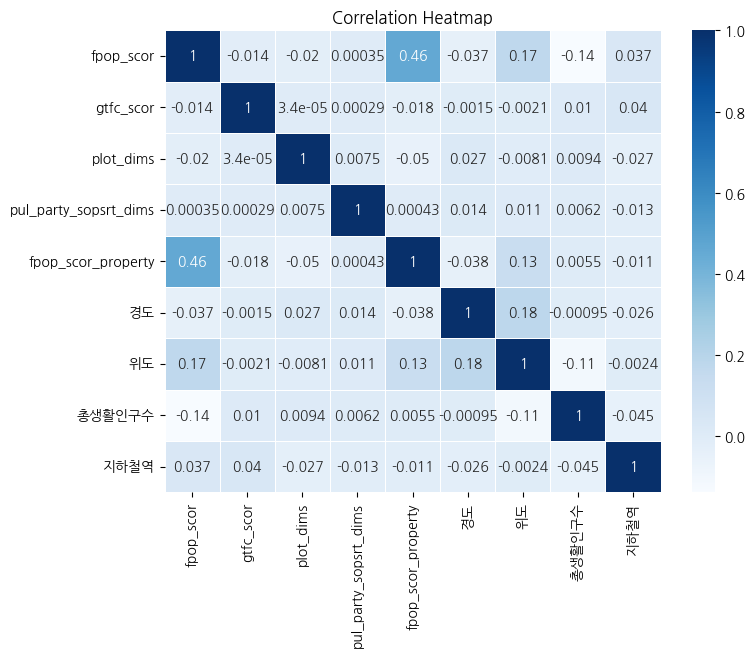

In [ ]:
# 히트맵으로 그리기
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap='Blues', linewidths=.5)
plt.title('Correlation Heatmap')
plt.show()

#### 각 변수 분포보기

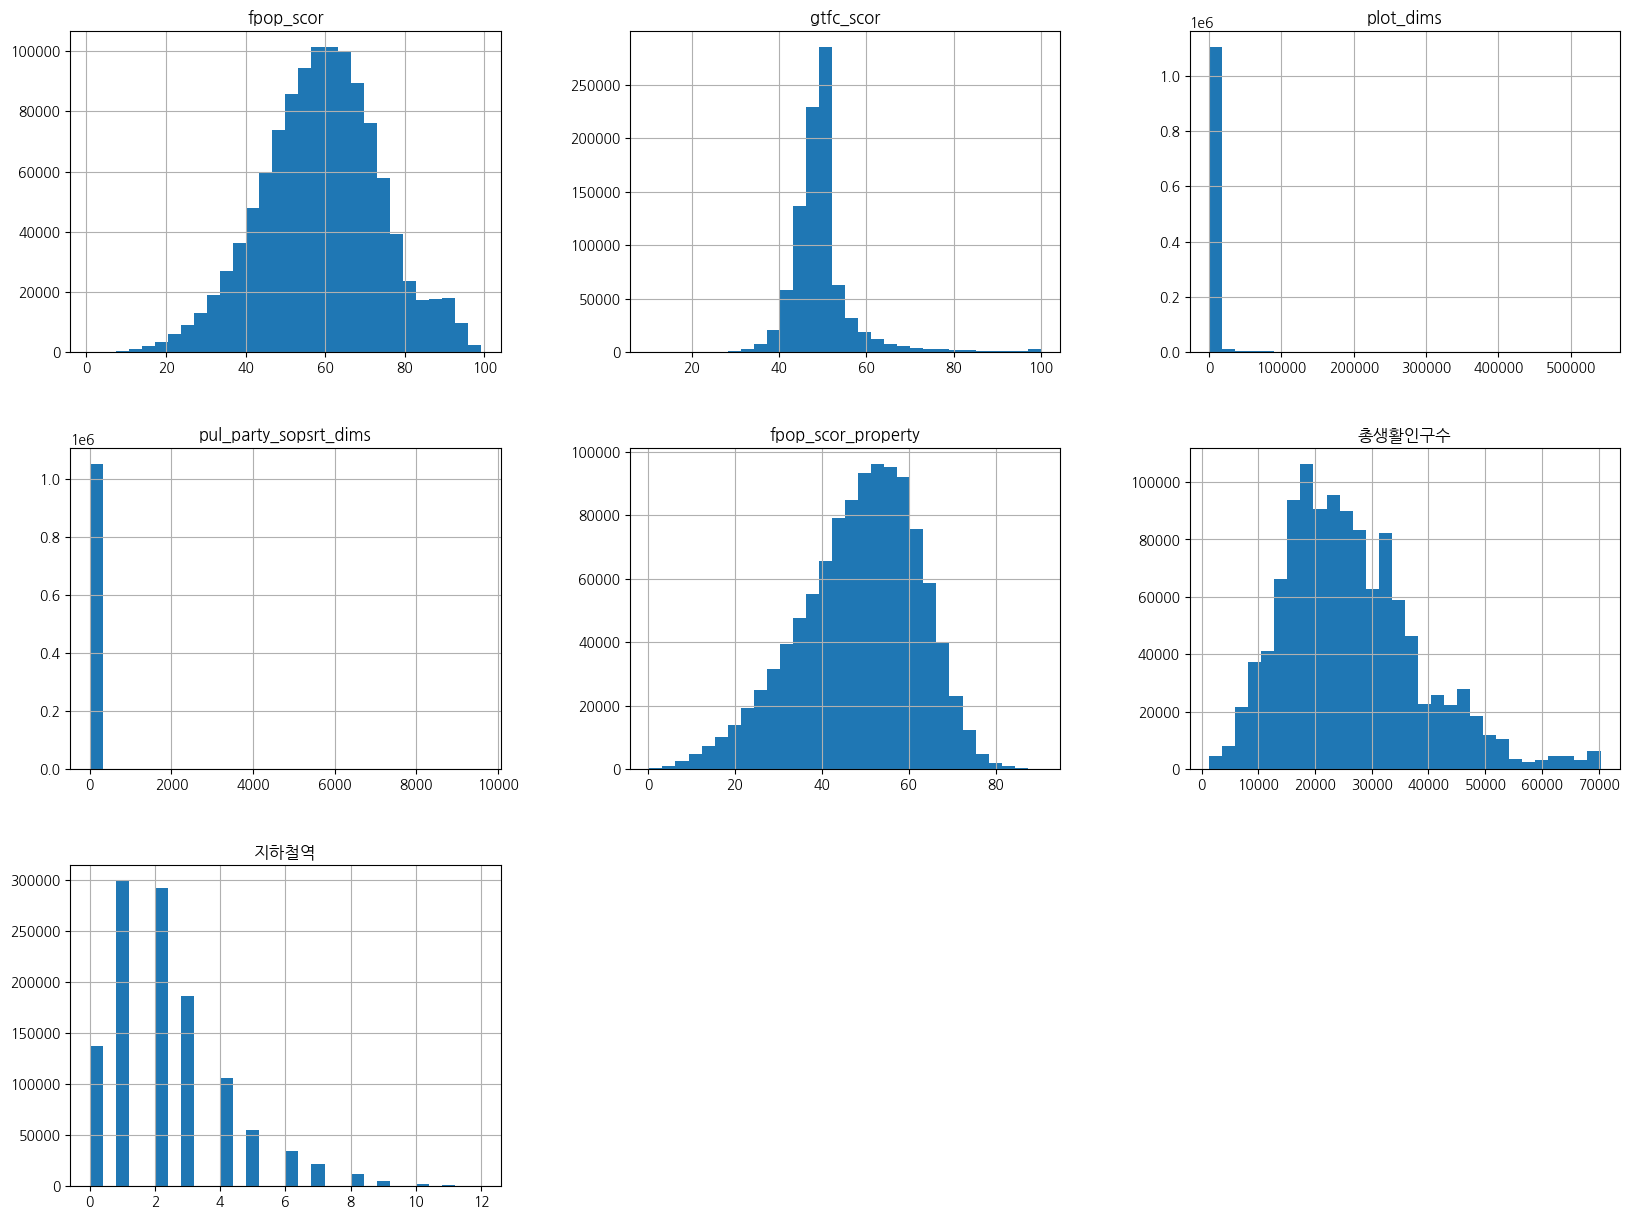

In [ ]:
# 각 피처의 분포 확인
all_data[['fpop_scor', 'gtfc_scor', 'plot_dims', 'pul_party_sopsrt_dims',	'fpop_scor_property', '총생활인구수', '지하철역']].hist(bins=30, figsize=(20,15))
plt.show()

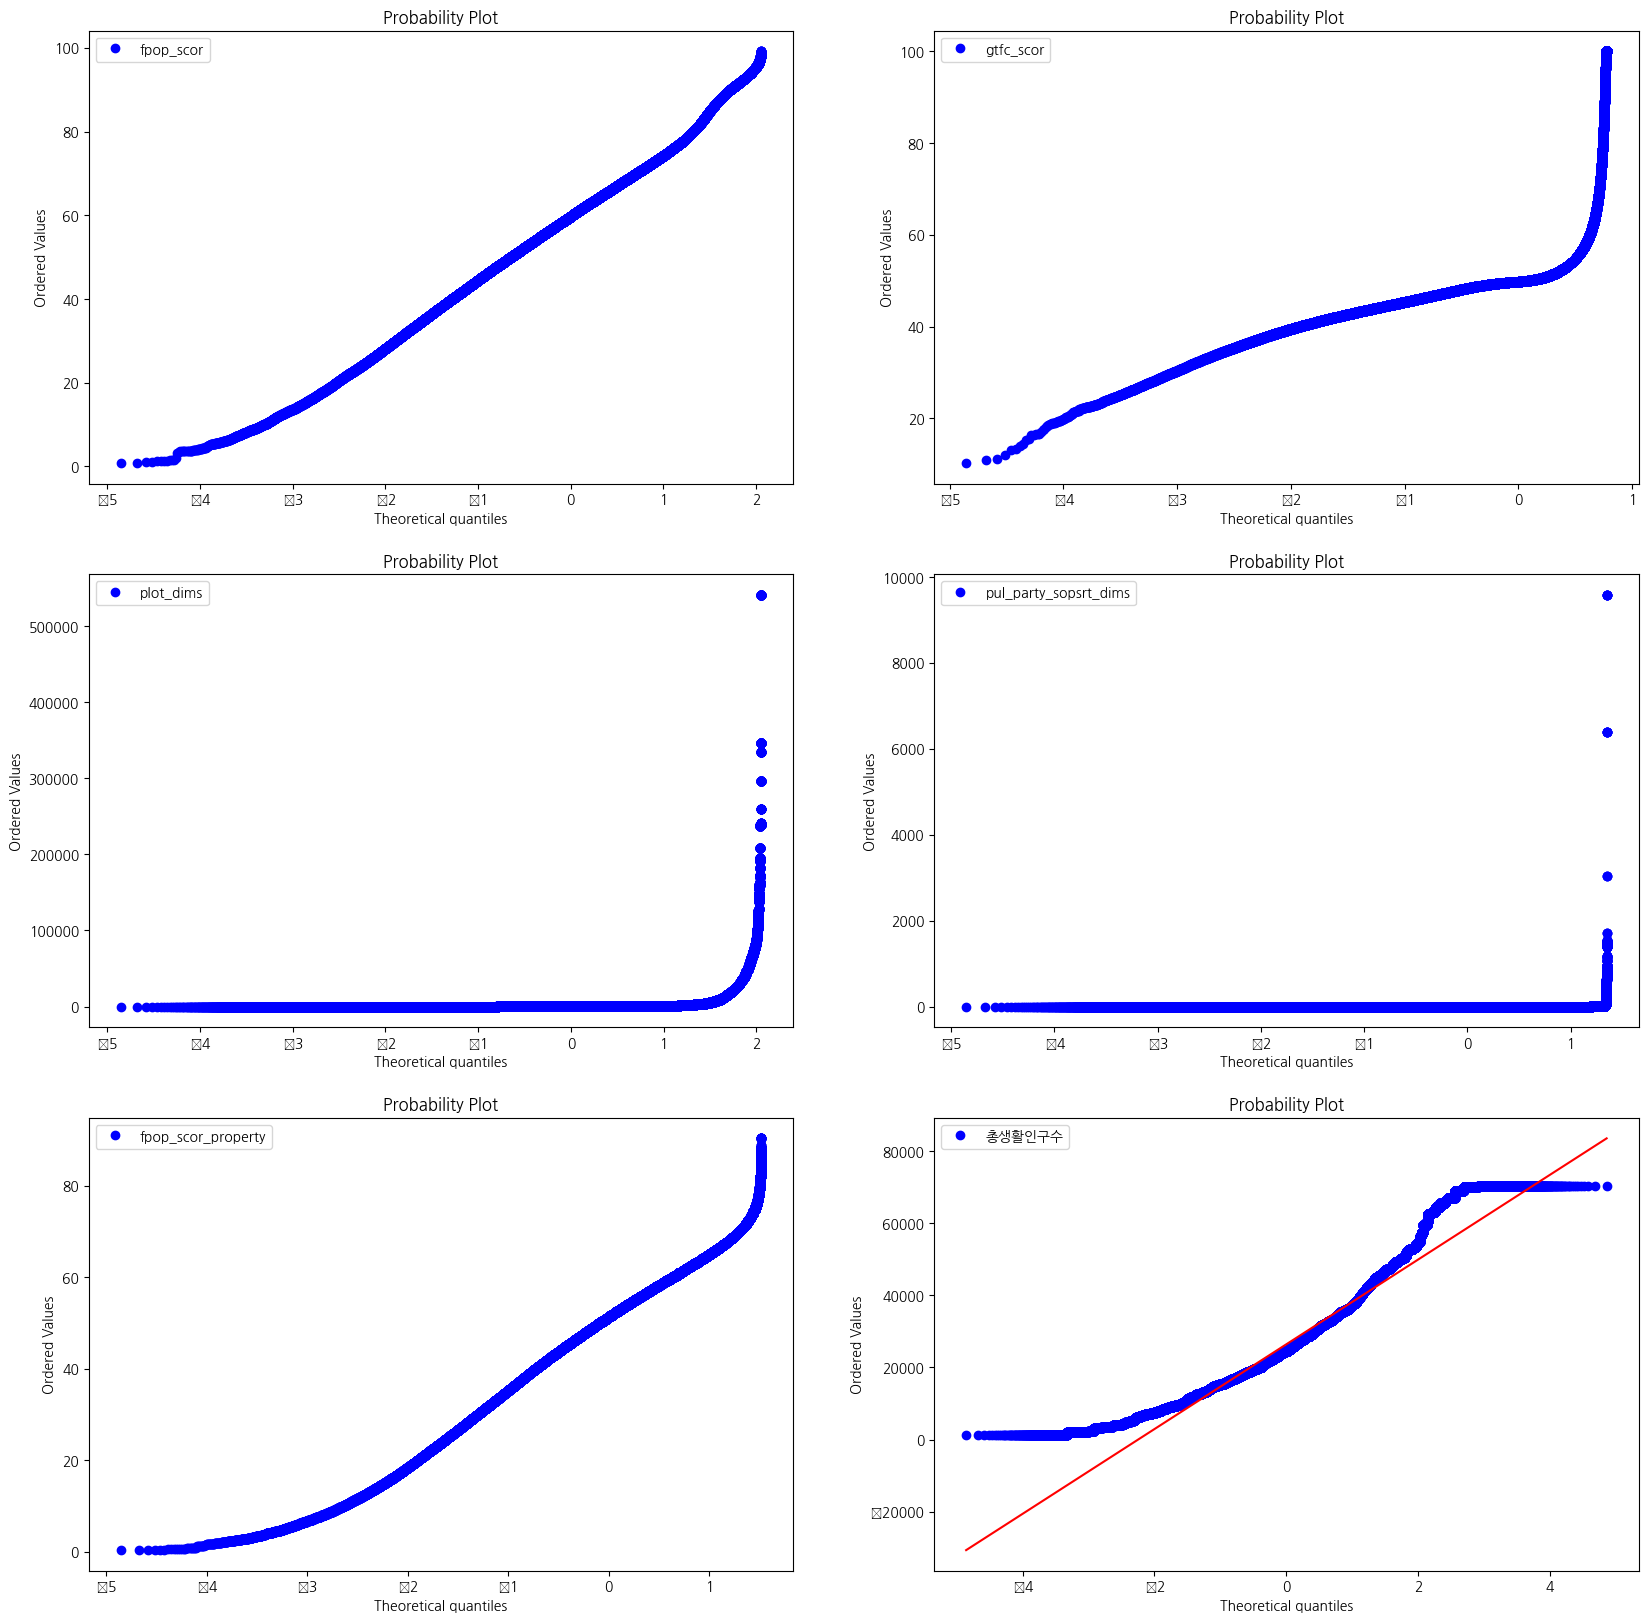

In [ ]:
# 각 변수의 Q-Q plot
fig = plt.figure(figsize = (20,20))

ax1 = fig.add_subplot(3,2,1)
res = stats.probplot(all_data['fpop_scor'], plot=plt)
ax1.legend(['fpop_scor'])

ax2 = fig.add_subplot(3,2,2)
res = stats.probplot(all_data['gtfc_scor'], plot=plt)
ax2.legend(['gtfc_scor'])

ax3 = fig.add_subplot(3,2,3)
res = stats.probplot(all_data['plot_dims'], plot=plt)
ax3.legend(['plot_dims'])

ax4 = fig.add_subplot(3,2,4)
res = stats.probplot(all_data['pul_party_sopsrt_dims'], plot=plt)
ax4.legend(['pul_party_sopsrt_dims'])

ax5 = fig.add_subplot(3,2,5)
res = stats.probplot(all_data['fpop_scor_property'], plot=plt)
ax5.legend(['fpop_scor_property'])

ax6 = fig.add_subplot(3,2,6)
res = stats.probplot(all_data['총생활인구수'], plot=plt)
ax6.legend(['총생활인구수'])

#### 데이터 자세히 보기

In [ ]:
pd.options.display.float_format = '{:.5f}'.format
all_data[['pul_party_sopsrt_dims', 'fpop_scor_property', 'fpop_scor',	'gtfc_scor',	'plot_dims', '총생활인구수',	'지하철역']].describe()

,pul_party_sopsrt_dims,fpop_scor_property,fpop_scor,gtfc_scor,plot_dims,총생활인구수,지하철역
count,1053505.00000,1081570.00000,1132948.00000,902996.00000,1132816.00000,1156040.00000,1156040.00000
mean,1.06935,48.60369,59.00837,49.61830,1915.51622,26408.81485,2.33161
std,33.04920,13.62464,14.85331,7.47409,11477.17233,12011.89925,1.84294
min,0.01000,0.34000,0.81000,10.28000,0.79956,1321.52320,0.00000
25%,0.06000,39.95000,49.33000,46.14000,148.41589,17902.49240,1.00000
50%,0.14000,50.11000,59.38000,49.12000,231.47461,24534.20210,2.00000
75%,0.34000,58.59000,68.84000,50.66000,439.40698,32985.33040,3.00000
max,9582.79000,90.34000,99.17000,100.00000,541028.72632,70345.42120,12.00000


## 지역별

### 지역별 등급 분포 확인

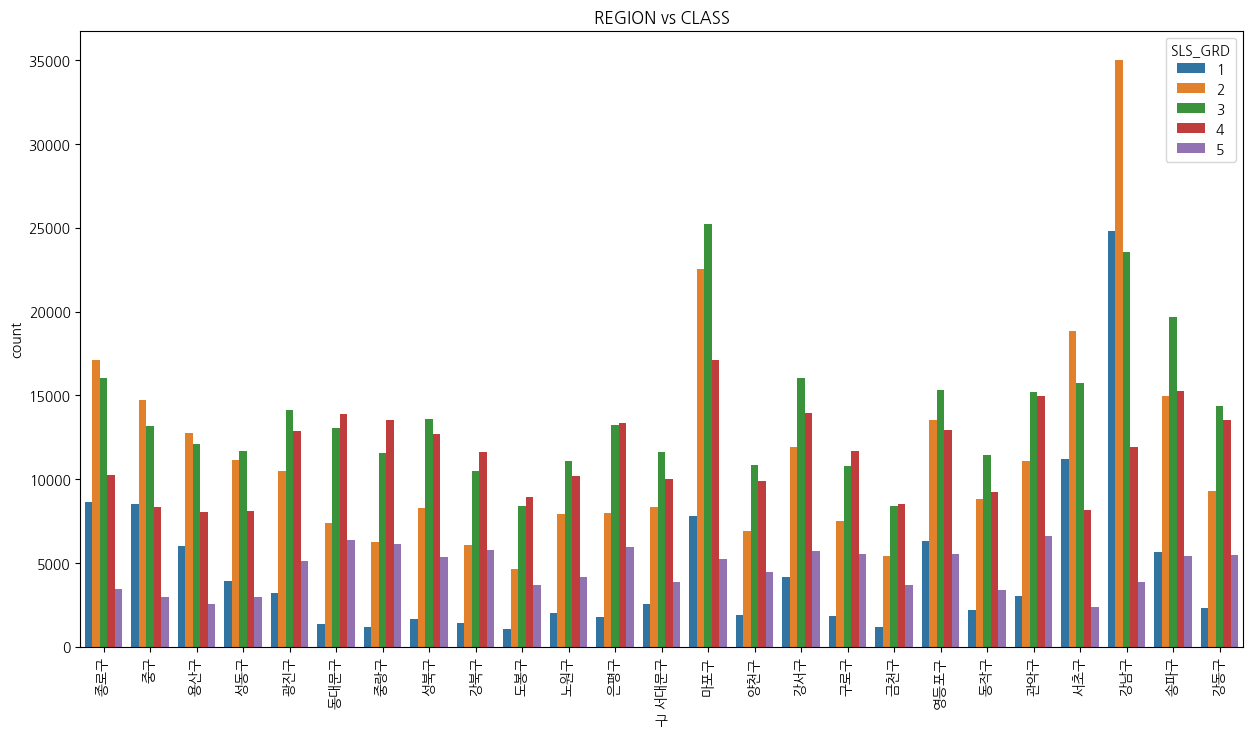

In [ ]:
plt.figure(figsize=(15,8))
ax = sns.countplot(x='구', hue = 'SLS_GRD', data = all_data)
ax.set_xticklabels(ax.get_xticklabels(),rotation = 90)
plt.title('REGION vs CLASS')
plt.show()

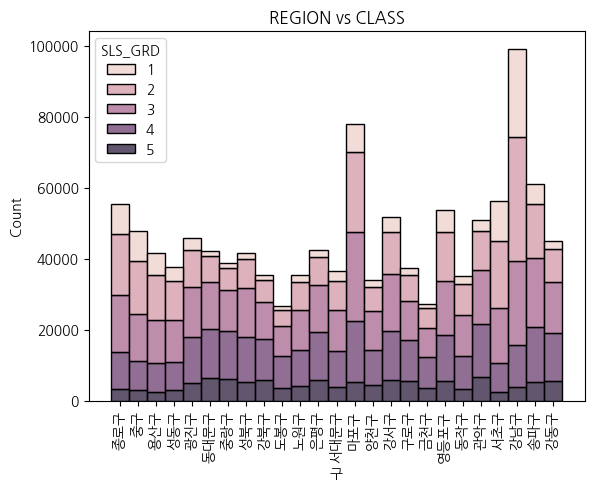

In [ ]:
ax = sns.histplot(x='구', hue = 'SLS_GRD', data = all_data, multiple='stack')
ax.set_xticklabels(ax.get_xticklabels(),rotation = 90)
plt.title('REGION vs CLASS')
plt.show()

#### 구별 평균 매출등급

In [ ]:
gm = all_data.groupby('구').mean()
gm = gm[['SLS_GRD', 'pul_party_sopsrt_dims', 'fpop_scor_property', 'fpop_scor',	'gtfc_scor',	'plot_dims', '총생활인구수',	'지하철역']]
gm = gm.reset_index()
gm

<ipython-input-4-09c1818818c0>:1: FutureWarning: The default value of numeric_only in DataFrameGroupBy.mean is deprecated. In a future version, numeric_only will default to False. Either specify numeric_only or select only columns which should be valid for the function.
  gm = all_data.groupby('구').mean()


,구,SLS_GRD,pul_party_sopsrt_dims,fpop_scor_property,fpop_scor,gtfc_scor,plot_dims,총생활인구수,지하철역
0,강남구,2.344406,1.679618,40.170108,47.478942,49.962905,1937.572151,35975.494337,2.552890
1,강동구,3.234651,0.701086,50.777074,61.979458,49.180721,2449.884306,31382.400916,1.737840
2,강북구,3.403400,1.225255,52.602280,57.331157,49.833802,987.757005,25010.220112,1.778516
3,강서구,3.099177,0.352644,48.259376,58.885832,49.013801,2076.068343,31388.142843,1.544450
4,관악구,3.218897,0.493139,51.793443,55.065004,49.181352,751.893181,22272.052472,1.789165
5,광진구,3.136997,0.820664,49.969206,59.983940,50.095088,1004.527207,25893.542146,1.741827
6,구로구,3.310553,1.322833,52.295898,63.519997,49.004694,2118.659947,25019.056922,1.209123
7,금천구,3.299577,0.291754,51.786047,60.796579,48.455563,1695.669909,23500.803259,0.385775
8,노원구,3.185324,3.703965,55.895065,62.628330,49.153672,4539.862287,27659.530032,1.600469
9,도봉구,3.355439,1.156267,57.547526,60.284829,49.025930,1637.932401,20102.144414,1.016813


#### 구 지도 경계선 파일 불러오기

In [ ]:
# 서울 행정구역 json raw파일(githubcontent)
r = requests.get('https://raw.githubusercontent.com/southkorea/seoul-maps/master/kostat/2013/json/seoul_municipalities_geo_simple.json')
c = r.content
seoul_geo = json.loads(c)

#### 지도 그리기(진하기)

In [ ]:
m = folium.Map(
    location=[37.566535, 126.9779692],
    zoom_start=11.2,
    tiles='cartodbpositron'
)

folium.Choropleth(
    geo_data=seoul_geo, # 경계선 좌표값이 담긴 데이터
    data=gm, # Series or DataFrame 넣으면 된다
    columns=['구', 'SLS_GRD'], # DataFrame의 어떤 columns을 넣을지
    key_on='properties.name',
    fill_color='YlOrRd',
    fill_opacity=0.5, # 색 투명도
    line_opacity=0.2, # 선 투명도
    legend_name='mean_SLS_GRD' # 범례
).add_to(m)

m

- 도봉구, 강북구, 중랑구, 동대문구가 취약함

- 강남과 서초쪽은 등급이 좋음

#### 동별 평균 매출 등급

등급이 좋은 강남, 서초와 취약한 동대문구, 중랑구를 중심으로

In [ ]:
dm = all_data.groupby(['구', '동']).mean()
dm = dm[['SLS_GRD', 'pul_party_sopsrt_dims', 'fpop_scor_property', 'fpop_scor',	'gtfc_scor',	'plot_dims', '총생활인구수',	'지하철역']]
dm = dm.reset_index()
dm

<ipython-input-7-95bd1840e387>:1: FutureWarning: The default value of numeric_only in DataFrameGroupBy.mean is deprecated. In a future version, numeric_only will default to False. Either specify numeric_only or select only columns which should be valid for the function.
  dm = all_data.groupby(['구', '동']).mean()


,구,동,SLS_GRD,pul_party_sopsrt_dims,fpop_scor_property,fpop_scor,gtfc_scor,plot_dims,총생활인구수,지하철역
0,강남구,개포동,3.006154,0.524969,34.208380,55.254857,48.227388,5521.330422,19316.031016,0.979692
1,강남구,논현동,2.478292,0.268085,38.900500,45.033357,50.299762,734.577874,33499.283231,3.619664
2,강남구,대치동,2.306283,1.512891,43.796555,51.582344,49.091289,4696.466760,25962.396717,2.223037
3,강남구,도곡동,2.358299,0.361366,36.535470,50.160640,48.912968,2536.509526,28414.416449,1.758688
4,강남구,삼성동,2.204599,0.342539,40.327097,47.904955,50.072720,2259.509909,28799.085295,3.400894
...,...,...,...,...,...,...,...,...,...,...
457,중랑구,면목동,3.566964,0.237709,58.311295,58.989461,48.725791,598.178978,21728.445418,1.584122
458,중랑구,묵동,3.423034,0.968494,55.254599,64.291465,49.113204,1119.551646,21087.788054,2.832115
459,중랑구,상봉동,3.223056,0.250295,54.843464,59.434012,49.736185,963.968594,22145.477941,2.988268
460,중랑구,신내동,3.117270,0.806474,58.743492,64.294444,48.598923,5118.619727,28007.946804,1.129125


#### 강남구

In [ ]:
# 강남구만 뽑아오기
gangnam = dm[dm['구'].str.contains('강남구', na = True)]
gangnam

,구,동,SLS_GRD,pul_party_sopsrt_dims,fpop_scor_property,fpop_scor,gtfc_scor,plot_dims,총생활인구수,지하철역
0,강남구,개포동,3.006154,0.524969,34.208380,55.254857,48.227388,5521.330422,19316.031016,0.979692
1,강남구,논현동,2.478292,0.268085,38.900500,45.033357,50.299762,734.577874,33499.283231,3.619664
2,강남구,대치동,2.306283,1.512891,43.796555,51.582344,49.091289,4696.466760,25962.396717,2.223037
3,강남구,도곡동,2.358299,0.361366,36.535470,50.160640,48.912968,2536.509526,28414.416449,1.758688
4,강남구,삼성동,2.204599,0.342539,40.327097,47.904955,50.072720,2259.509909,28799.085295,3.400894
5,강남구,세곡동,2.965181,4.186034,27.103789,60.682670,48.268680,2367.509021,49294.515741,0.000000
6,강남구,수서동,2.449548,0.866754,39.266033,64.895969,50.371297,7834.267255,21497.325955,1.695030
7,강남구,신사동,2.155907,1.028657,38.834602,44.163860,50.863798,443.671700,28426.069394,1.823479
8,강남구,압구정동,2.650442,303.712138,27.115014,49.532283,49.573407,24298.849612,28400.226166,0.856195
9,강남구,역삼동,2.342124,0.317139,44.948725,46.121781,49.988990,741.252337,56099.674750,3.045304


In [ ]:
file_path = "/content/drive/MyDrive/빅콘테스트/데이터/읍면동/TL_SCCO_SIG_WGS84.json"

with open(file_path, 'r') as file:
  dong_geo = json.load(file)

In [ ]:
!pip install folium
import folium

m = folium.Map(
    location=[37.488267216415, 127.03259017623],
    zoom_start=13,
    tiles='cartodbpositron'
)

folium.Choropleth(
    geo_data=dong_geo, # 경계선 좌표값이 담긴 데이터
    data=gangnam, # Series or DataFrame 넣으면 된다
    columns=['동', 'SLS_GRD'], # DataFrame의 어떤 columns을 넣을지
    key_on='properties.EMD_KOR_NM',
    fill_color='YlOrRd',
    fill_opacity=0.5, # 색 투명도
    line_opacity=0.2, # 선 투명도
    legend_name='SLS_GRD' # 범례
).add_to(m)

m

빨간 곳도 대체적으로 평균임. 강남구가 등급이 높아 낮아보이는 것

혼자 평균이 3등급인 것은 개포동

#### 서초구

In [ ]:
# 서초구만 뽑아오기
seocho = dm[dm['구'].str.contains('서초구', na = True)]
seocho

,구,동,SLS_GRD,pul_party_sopsrt_dims,fpop_scor_property,fpop_scor,gtfc_scor,plot_dims,총생활인구수,지하철역
136,서초구,내곡동,2.589520,8.793111,17.249289,47.435066,47.964653,8662.767338,22038.324080,0.000000
137,서초구,반포동,2.462216,1.384829,42.686203,51.191951,49.771358,5010.825881,18119.434893,3.678354
138,서초구,방배동,2.793477,0.494193,43.162844,51.300258,50.114476,977.252910,25723.333473,1.816130
139,서초구,서초동,2.285939,0.267853,49.761489,48.454219,50.347923,1472.875076,33788.217951,2.532026
140,서초구,신원동,2.528651,3.156133,26.156358,57.706927,48.116061,1890.508988,22051.898920,0.792976
141,서초구,양재동,2.548209,0.400797,39.785519,51.155239,49.717754,1246.005982,36249.425836,1.097643
142,서초구,염곡동,2.681818,3.215714,27.698077,56.440185,49.912381,2679.894343,22089.330911,0.500000
143,서초구,우면동,2.831560,0.695597,37.713013,64.126507,47.342409,8972.309763,45754.583565,0.000000
144,서초구,원지동,2.321429,4.014125,17.806007,50.794472,49.183769,362.130251,27130.680496,0.889610
145,서초구,잠원동,2.515539,0.472823,47.835804,59.481636,49.637855,2832.309631,22664.992468,4.747851


In [ ]:
m = folium.Map(
    location=[37.48715370882, 127.03240680276],
    zoom_start=13,
    tiles='cartodbpositron'
)

folium.Choropleth(
    geo_data=dong_geo, # 경계선 좌표값이 담긴 데이터
    data=seocho, # Series or DataFrame 넣으면 된다
    columns=['동', 'SLS_GRD'], # DataFrame의 어떤 columns을 넣을지
    key_on='properties.EMD_KOR_NM',
    fill_color='YlOrRd',
    fill_opacity=0.5, # 색 투명도
    line_opacity=0.2, # 선 투명도
    legend_name='SLS_GRD' # 범례
).add_to(m)

m

모두 2등급대 이상으로 매우 좋은 편

#### 동대문구

In [ ]:
# 동대문구만 뽑아오기
dongdea = dm[dm['구'].str.contains('동대문구', na = True)]
dongdea

,구,동,SLS_GRD,pul_party_sopsrt_dims,fpop_scor_property,fpop_scor,gtfc_scor,plot_dims,총생활인구수,지하철역
71,동대문구,답십리동,3.286918,0.817232,48.798755,67.295968,48.890093,1325.377034,25521.414246,1.251734
72,동대문구,신설동,3.109958,0.228615,53.672439,64.388808,48.768235,933.902918,34257.495173,3.653610
73,동대문구,용두동,3.390081,2.672976,47.654343,62.382733,47.950672,856.387088,34272.109814,3.718097
74,동대문구,이문동,3.540547,0.676978,54.156385,72.750829,50.685926,925.610017,19108.066443,1.639472
75,동대문구,장안동,3.222393,0.403273,50.918529,56.896058,48.872926,1312.499436,32694.717768,0.370431
76,동대문구,전농동,3.556077,10.371205,49.180046,63.966434,49.336314,1630.649927,24405.046344,1.498081
77,동대문구,제기동,3.757777,0.624710,46.007301,57.788236,49.314056,669.296745,31539.908650,2.345742
78,동대문구,청량리동,3.606672,0.499355,46.664129,68.244574,49.327810,1577.773973,18000.979248,1.908155
79,동대문구,회기동,3.162859,0.324955,52.429871,68.947144,50.480049,297.555084,19590.800745,0.976419
80,동대문구,휘경동,3.539884,0.317591,53.805891,69.562877,49.373066,1154.487887,19668.282832,1.295104


In [ ]:
m = folium.Map(
    location=[37.572484420047, 127.06372323434],
    zoom_start=13,
    tiles='cartodbpositron'
)

folium.Choropleth(
    geo_data=dong_geo, # 경계선 좌표값이 담긴 데이터
    data=dongdea, # Series or DataFrame 넣으면 된다
    columns=['동', 'SLS_GRD'], # DataFrame의 어떤 columns을 넣을지
    key_on='properties.EMD_KOR_NM',
    fill_color='YlOrRd',
    fill_opacity=0.5, # 색 투명도
    line_opacity=0.2, # 선 투명도
    legend_name='SLS_GRD' # 범례
).add_to(m)

m

대체적으로 3등급대에 몰려있음

#### 중랑구

In [ ]:
# 중랑구만 뽑아오기
jungrang = dm[dm['구'].str.contains('중랑구', na = True)]
jungrang

,구,동,SLS_GRD,pul_party_sopsrt_dims,fpop_scor_property,fpop_scor,gtfc_scor,plot_dims,총생활인구수,지하철역
456,중랑구,망우동,3.528068,0.456767,60.856876,64.155472,49.306053,656.994329,20326.597869,0.842209
457,중랑구,면목동,3.566964,0.237709,58.311295,58.989461,48.725791,598.178978,21728.445418,1.584122
458,중랑구,묵동,3.423034,0.968494,55.254599,64.291465,49.113204,1119.551646,21087.788054,2.832115
459,중랑구,상봉동,3.223056,0.250295,54.843464,59.434012,49.736185,963.968594,22145.477941,2.988268
460,중랑구,신내동,3.117270,0.806474,58.743492,64.294444,48.598923,5118.619727,28007.946804,1.129125
461,중랑구,중화동,3.488372,4.209138,55.431426,65.197546,48.885874,385.556992,20988.802965,2.616051


In [ ]:
m = folium.Map(
    location=[37.606987183486, 127.07653511668],
    zoom_start=13,
    tiles='cartodbpositron'
)

folium.Choropleth(
    geo_data=dong_geo, # 경계선 좌표값이 담긴 데이터
    data=jungrang, # Series or DataFrame 넣으면 된다
    columns=['동', 'SLS_GRD'], # DataFrame의 어떤 columns을 넣을지
    key_on='properties.EMD_KOR_NM',
    fill_color='YlOrRd',
    fill_opacity=0.5, # 색 투명도
    line_opacity=0.2, # 선 투명도
    legend_name='SLS_GRD' # 범례
).add_to(m)

m

매출등급이 3등급에 몰려있음

## 업종별

In [ ]:
all_data

,DATA_CRTR_YM,LT_UNQ_NO,STDG_EMD_CD,INDUSTRY_CD,SLS_GRD,pul_party_sopsrt_dims,fpop_scor_property,상권_변화_지표,fpop_scor,gtfc_scor,plot_dims,경도,위도,총생활인구수,지하철역,구,동
0,202201,1111010100100030100,11110101,A03,4,0.47000,19.76000,LH,89.26000,NaN,934.01184,126.96692,37.59203,15346.74770,0,종로구,청운동
1,202201,1111010100100480000,11110101,A01,2,1.40000,39.13000,LH,59.29000,59.42000,386.33923,126.96942,37.58704,15346.74770,0,종로구,청운동
2,202201,1111010100100590001,11110101,A11,3,0.34000,27.26000,LH,53.20000,48.86000,6.13660,126.96989,37.58642,15346.74770,0,종로구,청운동
3,202201,1111010100100590005,11110101,A03,2,0.15000,21.03000,LH,91.49000,46.78000,100.97571,126.96936,37.58622,15346.74770,0,종로구,청운동
4,202201,1111010100100690000,11110101,A01,2,1.75000,23.93000,LH,45.40000,50.58000,311.23560,126.97012,37.58643,15346.74770,0,종로구,청운동
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1156035,202212,1174011000106950000,11740110,A03,4,0.04000,60.07000,LL,65.91000,NaN,40938.94385,127.18076,37.55997,55528.99320,2,강동구,강일동
1156036,202212,1174011000106950000,11740110,A04,3,0.04000,50.85000,LL,66.38000,NaN,40938.94385,127.18076,37.55997,55528.99320,2,강동구,강일동
1156037,202212,1174011000106990000,11740110,A01,4,0.03000,26.61000,LL,59.94000,NaN,52146.74878,127.17883,37.55985,55528.99320,2,강동구,강일동
1156038,202212,1174011000107070000,11740110,A03,4,0.05000,41.32000,LL,51.30000,NaN,31270.14319,127.17166,37.56118,55528.99320,3,강동구,강일동


In [ ]:
## 업종별로 매출 등급의 분포 확인

to_name = {'A01':'한식', 'A02':'치킨', 'A03':'기타 외식', 'A04':'제과제빵', 'A05':'패스트푸드', 'A06':'분식', 'A07':'피자',
           'A08':'커피', 'A09':'아이스크림/빙수', 'A10': '기타 외국식', 'A11':'중식', 'A12':'주점', 'A13':'일식', 'A14':'서양식',
           'A15':'음료(커피 외)'}

all_data['업종명'] = all_data['INDUSTRY_CD'].map(to_name)

Text(0.5, 1.0, '업종별 매장 수')

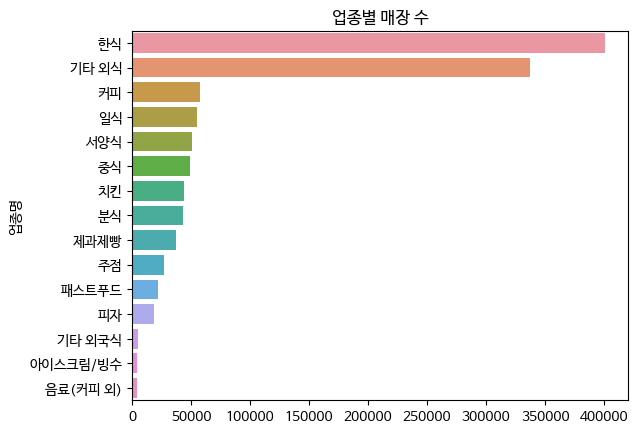

In [ ]:
sns.countplot(y='업종명', data=all_data, order=all_data['업종명'].value_counts().index)
plt.xlabel('')
plt.title('업종별 매장 수')

In [ ]:
a_sum = all_data['업종명'].value_counts().reset_index().rename(columns={'index':'업종명', '업종명':'합계'})
a_sum

,업종명,합계
0,한식,400457
1,기타 외식,337680
2,커피,57529
3,일식,54573
4,서양식,50559
5,중식,49329
6,치킨,43621
7,분식,43390
8,제과제빵,37287
9,주점,27174


In [ ]:
b = all_data.groupby(['업종명','SLS_GRD'])['LT_UNQ_NO'].count().reset_index()
b

,업종명,SLS_GRD,LT_UNQ_NO
0,기타 외국식,1,516
1,기타 외국식,2,1270
2,기타 외국식,3,1523
3,기타 외국식,4,1270
4,기타 외국식,5,515
...,...,...,...
70,한식,1,40052
71,한식,2,100111
72,한식,3,120133
73,한식,4,100110


In [ ]:
percen = pd.merge(b, a_sum, how='left', on='업종명')
percen['비율'] = (percen['LT_UNQ_NO'] / percen['합계']) * 100
percen.head(10)

,업종명,SLS_GRD,LT_UNQ_NO,합계,비율
0,기타 외국식,1,516,5094,10.12956
1,기타 외국식,2,1270,5094,24.93129
2,기타 외국식,3,1523,5094,29.89792
3,기타 외국식,4,1270,5094,24.93129
4,기타 외국식,5,515,5094,10.10993
5,기타 외식,1,33774,337680,10.00178
6,기타 외식,2,84417,337680,24.99911
7,기타 외식,3,101299,337680,29.99852
8,기타 외식,4,84420,337680,25.00000
9,기타 외식,5,33770,337680,10.00059


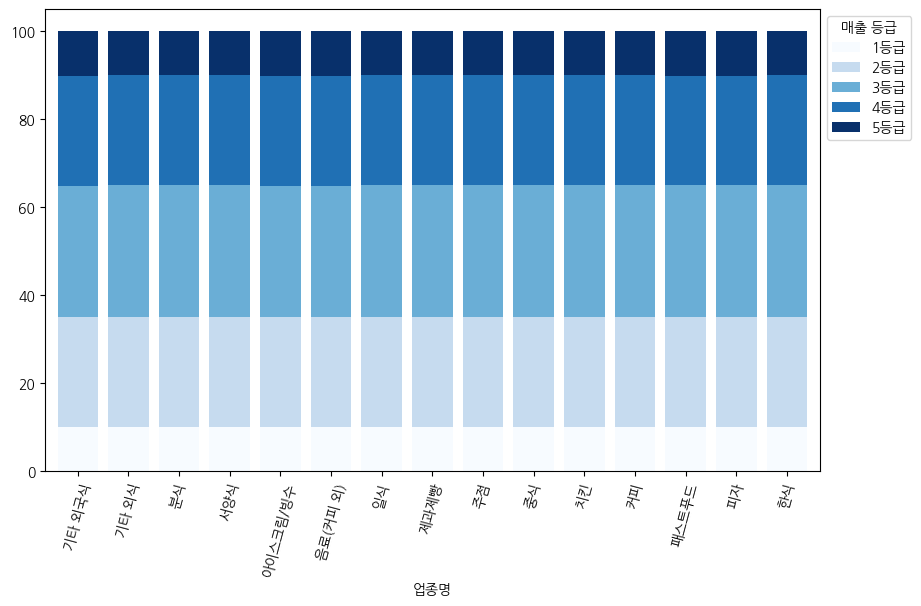

In [ ]:
# 업종별로 등급별 가게 수를 계산
pivot_df = percen.pivot_table(index='업종명', columns='SLS_GRD', values='비율', fill_value=0)

# 쌓은 막대 그래프 그리기
ax = pivot_df.plot(kind='bar', stacked=True, figsize=(10, 6), colormap='Blues', width=0.8)

plt.xticks(rotation=75)
plt.legend(loc='upper left', bbox_to_anchor=(1, 1), title='매출 등급', labels=['1등급', '2등급', '3등급', '4등급', '5등급'])

(array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14]),
 [Text(0, 0, '기타 외식'),
  Text(1, 0, '한식'),
  Text(2, 0, '중식'),
  Text(3, 0, '서양식'),
  Text(4, 0, '분식'),
  Text(5, 0, '패스트푸드'),
  Text(6, 0, '제과제빵'),
  Text(7, 0, '커피'),
  Text(8, 0, '치킨'),
  Text(9, 0, '일식'),
  Text(10, 0, '피자'),
  Text(11, 0, '음료(커피 외)'),
  Text(12, 0, '주점'),
  Text(13, 0, '기타 외국식'),
  Text(14, 0, '아이스크림/빙수')])

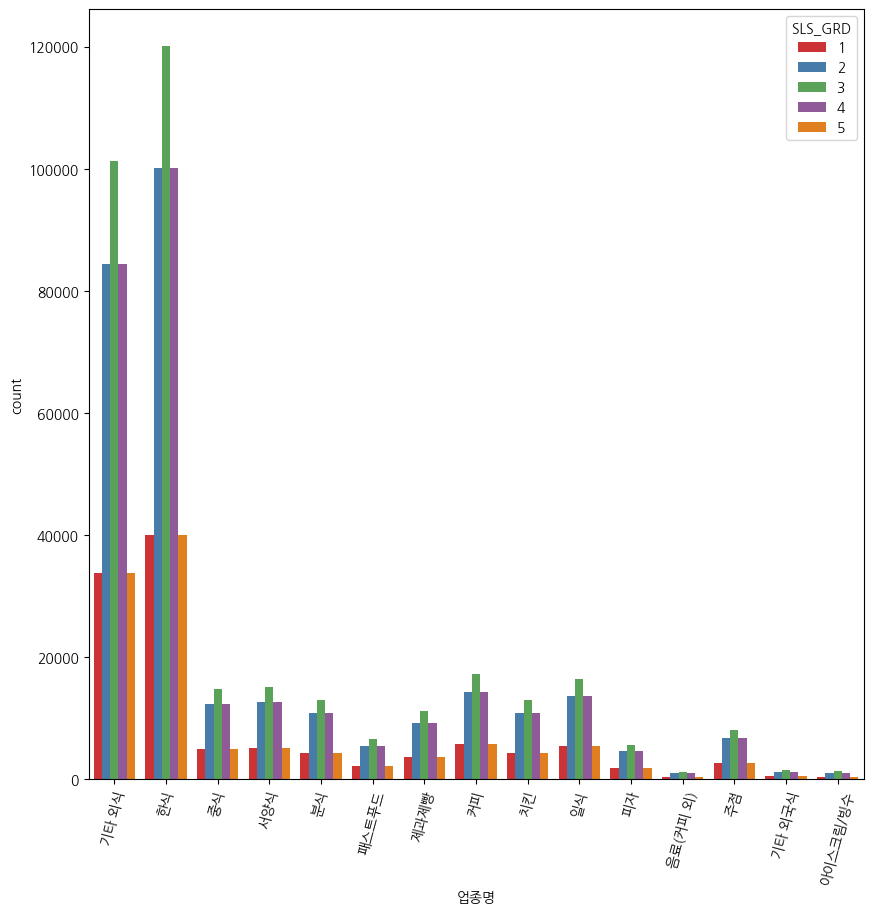

In [ ]:
plt.figure(figsize=(10,10))
sns.countplot(data=all_data, x='업종명', hue='SLS_GRD', palette='Set1')
plt.xticks(rotation=75)

## 기간별

In [ ]:
#추가 수집데이터 추가와 위경도 null값처리한 데이터를 이용한 EDA
all_data = pd.read_csv('/content/gdrive/MyDrive/2023 빅콘테스트/데이터/all_data(null).csv')
all_data.head()

,DATA_CRTR_YM,LT_UNQ_NO,STDG_EMD_CD,INDUSTRY_CD,SLS_GRD,pul_party_sopsrt_dims,fpop_scor_property,상권_변화_지표,fpop_scor,gtfc_scor,plot_dims,경도,위도,총생활인구수,지하철역
0,202201,1111010100100030100,11110101,A03,4,0.47,19.76,LH,89.26,NaN,934.011841,126.966923,37.592027,15346.7477,0
1,202201,1111010100100480000,11110101,A01,2,1.40,39.13,LH,59.29,59.42,386.339233,126.969415,37.587042,15346.7477,0
2,202201,1111010100100590001,11110101,A11,3,0.34,27.26,LH,53.20,48.86,6.136597,126.969893,37.586417,15346.7477,0
3,202201,1111010100100590005,11110101,A03,2,0.15,21.03,LH,91.49,46.78,100.975708,126.969359,37.586218,15346.7477,0
4,202201,1111010100100690000,11110101,A01,2,1.75,23.93,LH,45.40,50.58,311.235596,126.970119,37.586430,15346.7477,0


In [ ]:
# 각 기간과 매출등급으로 묶어주기
month=all_data.groupby(['DATA_CRTR_YM', 'SLS_GRD']).size().reset_index(name='횟수')
month

,DATA_CRTR_YM,SLS_GRD,횟수
0,202201,1,9399
1,202201,2,23467
2,202201,3,28164
3,202201,4,23467
4,202201,5,9398
5,202202,1,9348
6,202202,2,23351
7,202202,3,28017
8,202202,4,23351
9,202202,5,9348


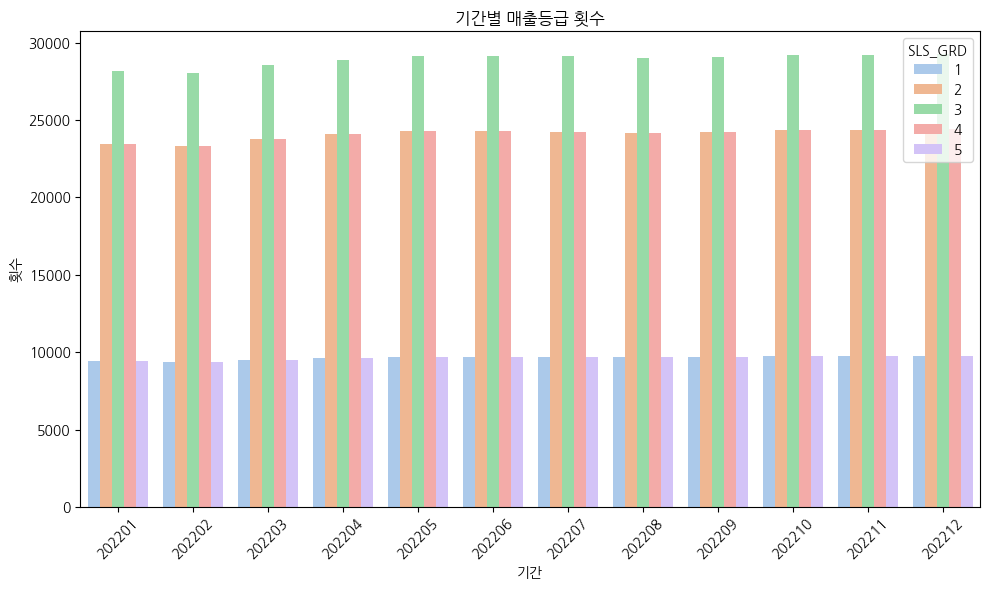

In [ ]:
# 그래프 그리기
import warnings
warnings.filterwarnings('ignore')

plt.figure(figsize=(10, 6))
sns.barplot(data=month, x='DATA_CRTR_YM', y='횟수', hue='SLS_GRD', palette='pastel')
plt.title('기간별 매출등급 횟수')
plt.xlabel('기간')
plt.ylabel('횟수')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
#월별 매출등급의 분포
data = pd.pivot_table(month,                # 피벗할 데이터프레임
                     index = 'DATA_CRTR_YM',    # 행 위치에 들어갈 열
                     columns = 'SLS_GRD',    # 열 위치에 들어갈 열
                     values = '횟수')    # 데이터로 사용할 열
data

SLS_GRD,1,2,3,4,5
DATA_CRTR_YM,,,,,
202201,9399,23467,28164,23467,9398
202202,9348,23351,28017,23351,9348
202203,9520,23776,28534,23776,9519
202204,9646,24088,28906,24090,9642
202205,9720,24277,29138,24277,9719
202206,9717,24266,29118,24267,9714
202207,9713,24257,29113,24257,9712
202208,9680,24178,29011,24179,9678
202209,9701,24230,29077,24231,9699


<Axes: title={'center': '월별 매출등급 건수'}, xlabel='월별', ylabel='매출등급 건수'>

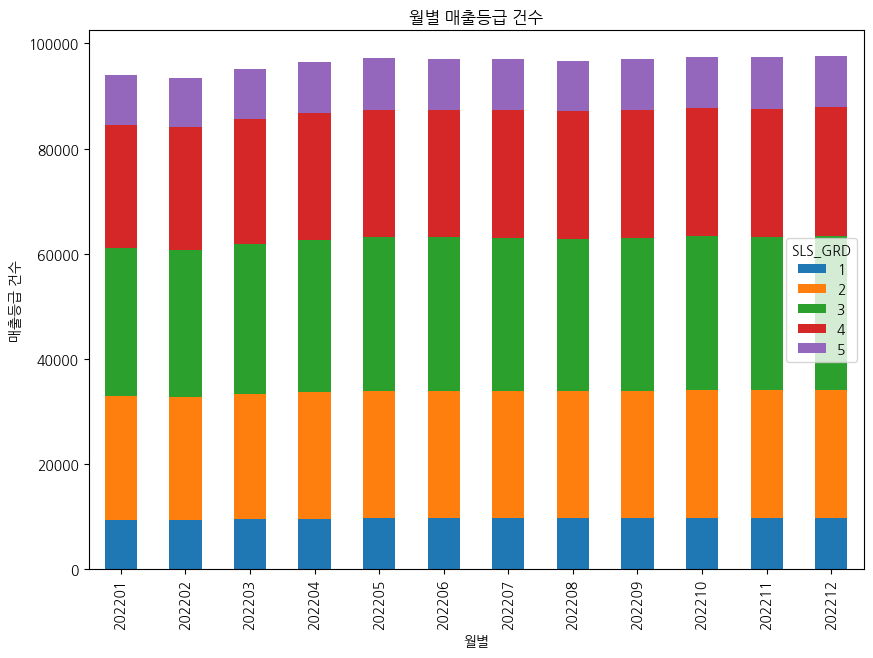

In [ ]:
data.plot.bar(stacked=True, figsize=(10,7),xlabel='월별',
               ylabel='매출등급 건수', title='월별 매출등급 건수')
#월별로 매출등급의 비율이 큰차이는 없다

In [ ]:
all_data.head()

,DATA_CRTR_YM,LT_UNQ_NO,STDG_EMD_CD,INDUSTRY_CD,SLS_GRD,pul_party_sopsrt_dims,fpop_scor_property,상권_변화_지표,fpop_scor,gtfc_scor,plot_dims,경도,위도,총생활인구수,지하철역
0,202201,1111010100100030100,11110101,A03,4,0.47,19.76,LH,89.26,NaN,934.011841,126.966923,37.592027,15346.7477,0
1,202201,1111010100100480000,11110101,A01,2,1.40,39.13,LH,59.29,59.42,386.339233,126.969415,37.587042,15346.7477,0
2,202201,1111010100100590001,11110101,A11,3,0.34,27.26,LH,53.20,48.86,6.136597,126.969893,37.586417,15346.7477,0
3,202201,1111010100100590005,11110101,A03,2,0.15,21.03,LH,91.49,46.78,100.975708,126.969359,37.586218,15346.7477,0
4,202201,1111010100100690000,11110101,A01,2,1.75,23.93,LH,45.40,50.58,311.235596,126.970119,37.586430,15346.7477,0


가게별 평균 매출등급 구하기

각 (필지번호,업종)을 키로 잡았다.

In [ ]:
#해당 가게의 전체 매출등급 합을 구한다.
aa=all_data.groupby(['LT_UNQ_NO', 'INDUSTRY_CD']).sum('SLS_GRD')['SLS_GRD'].reset_index(name='매출등급합')
aa

,LT_UNQ_NO,INDUSTRY_CD,매출등급합
0,1111010100100030100,A03,44
1,1111010100100480000,A01,21
2,1111010100100590001,A11,36
3,1111010100100590005,A01,37
4,1111010100100590005,A03,25
...,...,...,...
109967,1174011000106950000,A03,42
109968,1174011000106950000,A04,36
109969,1174011000106990000,A01,47
109970,1174011000107070000,A03,39


In [ ]:
#해당 가게의 전체 운영달의 횟수를 구한다.
a=all_data.groupby(['LT_UNQ_NO', 'INDUSTRY_CD']).size().reset_index(name='횟수')
a

,LT_UNQ_NO,INDUSTRY_CD,횟수
0,1111010100100030100,A03,12
1,1111010100100480000,A01,12
2,1111010100100590001,A11,12
3,1111010100100590005,A01,11
4,1111010100100590005,A03,12
...,...,...,...
109967,1174011000106950000,A03,12
109968,1174011000106950000,A04,12
109969,1174011000106990000,A01,11
109970,1174011000107070000,A03,12


In [ ]:
#해당 가게에 매출등급의 합과 운영달의 횟수 데이터를 붙여준다.
aaa=a.merge(aa,how='left')
aaa.head()

,LT_UNQ_NO,INDUSTRY_CD,횟수,매출등급합
0,1111010100100030100,A03,12,44
1,1111010100100480000,A01,12,21
2,1111010100100590001,A11,12,36
3,1111010100100590005,A01,11,37
4,1111010100100590005,A03,12,25


In [ ]:
# 매출등급 평균 열 생성하기
aaa['매출등급 평균']=aaa['매출등급합']/aaa['횟수']
aaa.head()

,LT_UNQ_NO,INDUSTRY_CD,횟수,매출등급합,매출등급 평균
0,1111010100100030100,A03,12,44,3.666667
1,1111010100100480000,A01,12,21,1.750000
2,1111010100100590001,A11,12,36,3.000000
3,1111010100100590005,A01,11,37,3.363636
4,1111010100100590005,A03,12,25,2.083333


In [ ]:
#열순서 재배치하기
aaa=aaa[['LT_UNQ_NO','INDUSTRY_CD','매출등급 평균','매출등급합','횟수']]
aaa

,LT_UNQ_NO,INDUSTRY_CD,매출등급 평균,매출등급합,횟수
0,1111010100100030100,A03,3.666667,44,12
1,1111010100100480000,A01,1.750000,21,12
2,1111010100100590001,A11,3.000000,36,12
3,1111010100100590005,A01,3.363636,37,11
4,1111010100100590005,A03,2.083333,25,12
...,...,...,...,...,...
109967,1174011000106950000,A03,3.500000,42,12
109968,1174011000106950000,A04,3.000000,36,12
109969,1174011000106990000,A01,4.272727,47,11
109970,1174011000107070000,A03,3.250000,39,12


### 매출등급 평균
2이하인 가게(매출등급이 좋은가게)

In [ ]:
a2_low=aaa[aaa['매출등급 평균']<=2]
a2_low

,LT_UNQ_NO,INDUSTRY_CD,매출등급 평균,매출등급합,횟수
1,1111010100100480000,A01,1.750000,21,12
5,1111010100100690000,A01,1.583333,19,12
9,1111010100100940001,A03,1.750000,21,12
10,1111010100100940002,A01,2.000000,24,12
25,1111010200100580001,A04,2.000000,24,12
...,...,...,...,...,...
109935,1174011000106750001,A04,2.000000,24,12
109956,1174011000106790000,A06,1.583333,19,12
109959,1174011000106790001,A11,2.000000,24,12
109960,1174011000106790002,A02,1.666667,20,12


In [ ]:
#어떤 업종이 주로 평점 2이하인지 알아보기: 비교기준을 같게 만들기 위한 작업
a2_low['INDUSTRY_CD'].value_counts().sort_index('index')

A01    7791
A02     864
A03    6501
A04     826
A05     509
A06     958
A07     375
A08    1268
A09      78
A10     115
A11    1021
A12     382
A13    1075
A14    1021
A15      87
Name: INDUSTRY_CD, dtype: int64

In [ ]:
#2022년 전체 기간에 존재하는 업종갯수
all_data['INDUSTRY_CD'].value_counts().sort_index('index')

A01    400457
A02     43621
A03    337680
A04     37287
A05     22033
A06     43390
A07     18567
A08     57529
A09      4438
A10      5094
A11     49329
A12     27174
A13     54573
A14     50559
A15      4309
Name: INDUSTRY_CD, dtype: int64

In [ ]:
#매출등급 평균이 2점이하인 것 중에 특정하게 많은 업종은 없었다.
(a2_low['INDUSTRY_CD'].value_counts().sort_index('index')/all_data['INDUSTRY_CD'].value_counts().sort_index('index'))*1000

A01    19.455272
A02    19.806974
A03    19.251955
A04    22.152493
A05    23.101711
A06    22.078820
A07    20.197124
A08    22.041058
A09    17.575484
A10    22.575579
A11    20.697764
A12    14.057555
A13    19.698386
A14    20.194229
A15    20.190299
Name: INDUSTRY_CD, dtype: float64

In [ ]:
#매출등급 평균이 2점이하인 것 중에 업종에 따라
a2_lowP=pd.DataFrame((a2_low['INDUSTRY_CD'].value_counts().sort_index('index')/all_data['INDUSTRY_CD'].value_counts().sort_index('index'))*100).reset_index().rename(columns={'index':'업종별','INDUSTRY_CD':'2점이하 비율'})

# '2점이하 비율' 열의 합 계산
sum_of_ratios =a2_lowP['2점이하 비율'].sum()

# 각 값을 현재 합에서 나눈 후 100을 곱함
a2_lowP['2점이하 비율'] = ((a2_lowP['2점이하 비율'] / sum_of_ratios) * 100).round(1)
a2_lowP

,업종별,2점이하 비율
0,A01,6.4
1,A02,6.5
2,A03,6.4
3,A04,7.3
4,A05,7.6
5,A06,7.3
6,A07,6.7
7,A08,7.3
8,A09,5.8
9,A10,7.4


<Axes: title={'center': '업종별 2점이하인 매출등급 비율'}, xlabel='업종별', ylabel='2점이하 비율'>

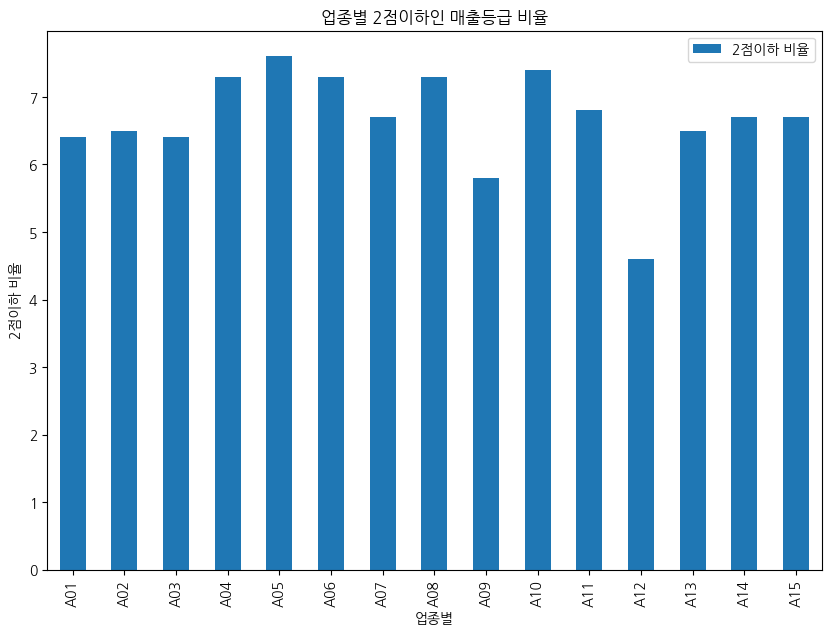

In [ ]:
#업종별 2점이하인 매출등급 비율이 업종이 A05인 패스트푸드 업종이 가장 많고 A12인 주점 업종이 가장 적다.
# 'A05':'패스트푸드점', 'A12':'주점'
a2_lowP.plot.bar(stacked=True, figsize=(10,7),x='업종별',xlabel='업종별',
               ylabel='2점이하 비율', title='업종별 2점이하인 매출등급 비율')

매출등급 평균이 4이상인 가게(매출등급이 낮은 가게=폐업위기)

In [ ]:
a4_up=aaa[aaa['매출등급 평균']>=4]
a4_up

#어떤 업종이 주로 평점 4이상인지 알아보기: 비교기준을 같게 만들기 위한 작업
a4_up['INDUSTRY_CD'].value_counts().sort_index('index')

#2022년 전체 기간에 존재하는 업종갯수
all_data['INDUSTRY_CD'].value_counts().sort_index('index')

#매출등급 평균이 4점이하인 것 중에 업종에 따라
a4_upP=pd.DataFrame((a4_up['INDUSTRY_CD'].value_counts().sort_index('index')/all_data['INDUSTRY_CD'].value_counts().sort_index('index'))*100).reset_index().rename(columns={'index':'업종별','INDUSTRY_CD':'4점이상 비율'})

# '4점이상 비율' 열의 합 계산
sum_of_ratios = a4_upP['4점이상 비율'].sum()

# 각 값을 현재 합에서 나눈 후 100을 곱함
a4_upP['4점이상 비율'] = ((a4_upP['4점이상 비율'] / sum_of_ratios) * 100).round(1)
a4_upP

,업종별,4점이상 비율
0,A01,6.1
1,A02,6.2
2,A03,6.5
3,A04,7.2
4,A05,7.2
5,A06,6.8
6,A07,6.6
7,A08,8.0
8,A09,4.9
9,A10,8.5


<Axes: title={'center': '업종별 4점이상인 매출등급 비율'}, xlabel='업종별', ylabel='4점이상 비율'>

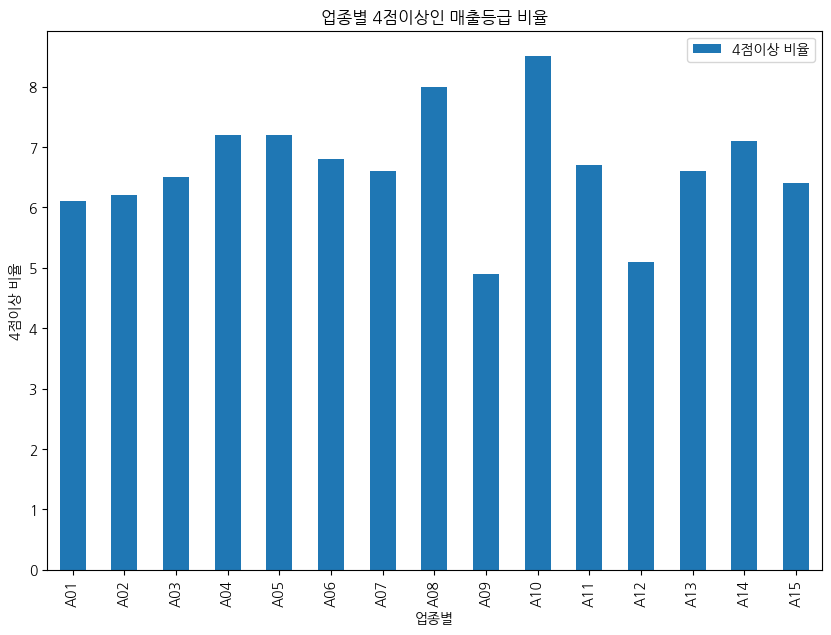

In [ ]:
#업종별 4점이상인 매출등급 비율이 업종이 A09인업종이 가장 적고, A10인 업종이 가장 많다.
# 'A09':'아이스크림/빙수', 'A10': '기타 외국식'
a4_upP.plot.bar(stacked=True, figsize=(10,7),x='업종별',xlabel='업종별',
               ylabel='4점이상 비율', title='업종별 4점이상인 매출등급 비율')

### 영업기간이 1년 미만 가게들

In [ ]:
#매출등급 평균 정수로 반올림
b=aaa.loc[aaa['횟수']<12].reset_index()
b=b.drop('index',axis=1)
b['매출등급 평균'] = b['매출등급 평균'].round(0)
b

,LT_UNQ_NO,INDUSTRY_CD,매출등급 평균,매출등급합,횟수
0,1111010100100590005,A01,3.0,37,11
1,1111010100100900000,A08,5.0,15,3
2,1111010200100170037,A03,3.0,20,7
3,1111010300100290002,A14,4.0,13,3
4,1111010400100520004,A03,4.0,27,6
...,...,...,...,...,...
30400,1174011000106770000,A03,2.0,27,11
30401,1174011000106790003,A02,3.0,22,8
30402,1174011000106840000,A06,5.0,49,10
30403,1174011000106990000,A01,4.0,47,11


In [ ]:
#b_count_by_industry['갯수'].sort_index('index')#all_data['INDUSTRY_CD'].value_counts().sort_index('index')

0      167
1      827
2     1416
3     2498
4     2426
      ... 
70       3
71      13
72      18
73      24
74      27
Name: 갯수, Length: 75, dtype: int64

In [ ]:
bby_industry = b.groupby(['INDUSTRY_CD']).size().reset_index(name='전체갯수')
bby_industry

,INDUSTRY_CD,전체갯수
0,A01,7334
1,A02,1013
2,A03,10286
3,A04,884
4,A05,560
5,A06,1002
6,A07,446
7,A08,2128
8,A09,85
9,A10,200


In [ ]:
#영업기간이 11개월이하인 가게들 중 각 업종별 매출등급평균 갯수
b_count_by_industry = b.groupby(['INDUSTRY_CD', '매출등급 평균']).size().reset_index(name='갯수')
#b_count_by_industry['업종별 갯수 정규화']=(b_count_by_industry['갯수']/all_data['INDUSTRY_CD'].value_counts())
b_count_by_industry

,INDUSTRY_CD,매출등급 평균,갯수
0,A01,1.0,167
1,A01,2.0,827
2,A01,3.0,1416
3,A01,4.0,2498
4,A01,5.0,2426
...,...,...,...
70,A15,1.0,3
71,A15,2.0,13
72,A15,3.0,18
73,A15,4.0,24


In [ ]:
#영업기간이 1년이 안되는 가게 중 비율 정규화하기
b_count=b_count_by_industry.merge(bby_industry,how='left')
b_count['비율']=((b_count['갯수']/b_count['전체갯수'])*100).round(1)
b_count

,INDUSTRY_CD,매출등급 평균,갯수,전체갯수,비율
0,A01,1.0,167,7334,2.3
1,A01,2.0,827,7334,11.3
2,A01,3.0,1416,7334,19.3
3,A01,4.0,2498,7334,34.1
4,A01,5.0,2426,7334,33.1
...,...,...,...,...,...
70,A15,1.0,3,85,3.5
71,A15,2.0,13,85,15.3
72,A15,3.0,18,85,21.2
73,A15,4.0,24,85,28.2


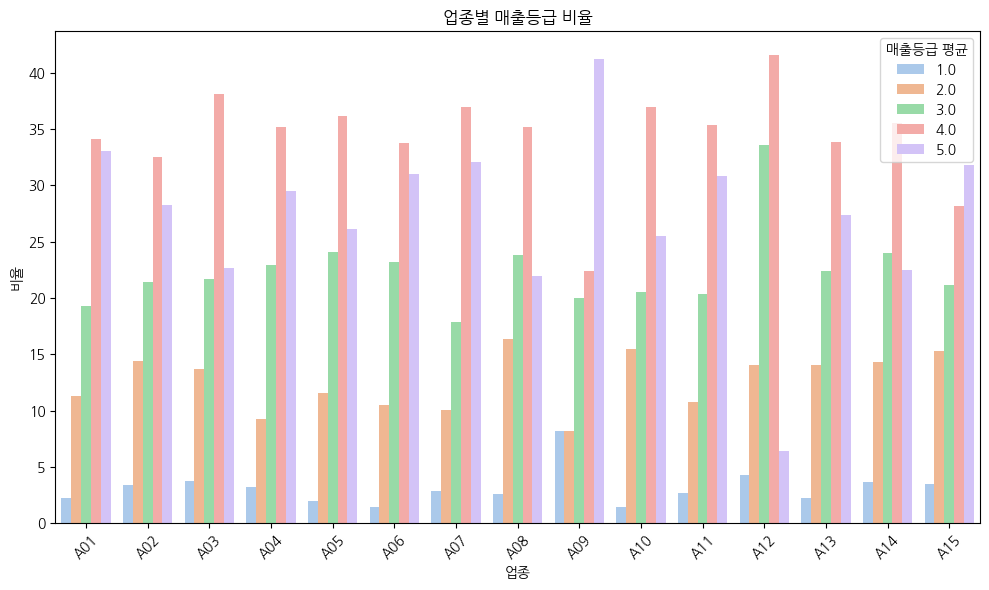

In [ ]:
# 그래프 그리기
import warnings
warnings.filterwarnings('ignore')

plt.figure(figsize=(10, 6))
sns.barplot(data=b_count, x='INDUSTRY_CD', y='비율', hue='매출등급 평균', palette='pastel')
plt.title('업종별 매출등급 비율')
plt.xlabel('업종')
plt.ylabel('비율')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 특정 업종 특징
(A05,A09,A10,A12)

#### A05-패스트푸드점

매출등급 상위의 가게와 매출등급 하위 가게의 비교결과,

상위 가게들이 하위가게들보다

 pul_party_sopsrt_dims 평균 차이가 약 2.5 높으며,

 fpop_scor_property	평균 차이가 약 3 높으며,

 plot_dims 평균 차이가 약 1000 높으며,

 총생활인구수 평균 차이가 약 4000 높았으며,

 지하철역 갯수가 1개 이상 정도 더 많은것으로 나왔다.

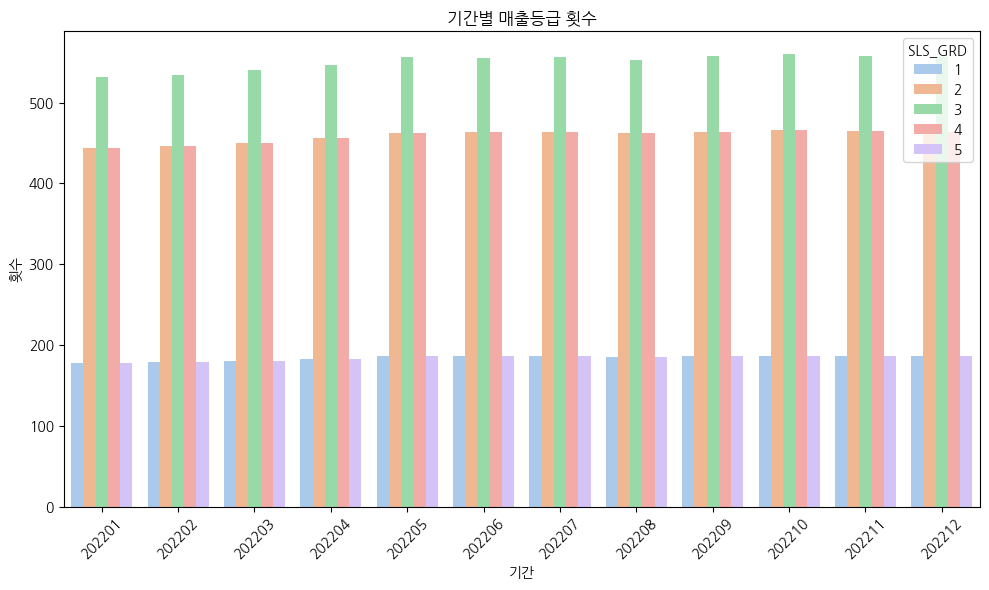

In [ ]:
#패스트푸드점 A05의 월별 매출등급변화 및 가게별 특징
A05_m=all_data[all_data['INDUSTRY_CD']=='A05'].reset_index().drop('index',axis=1)

# 각 기간과 매출등급으로 묶어주기
A05_mmonth=A05_m.groupby(['DATA_CRTR_YM', 'SLS_GRD']).size().reset_index(name='횟수')
# 그래프 그리기
import warnings
warnings.filterwarnings('ignore')

plt.figure(figsize=(10, 6))
sns.barplot(data=A05_mmonth, x='DATA_CRTR_YM', y='횟수', hue='SLS_GRD', palette='pastel')
plt.title('기간별 매출등급 횟수')
plt.xlabel('기간')
plt.ylabel('횟수')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
#해당 가게의 전체 매출등급 합을 구한다.
A05_maa=A05_m.groupby(['LT_UNQ_NO']).sum('SLS_GRD')['SLS_GRD'].reset_index(name='매출등급합')
#해당 가게의 전체 운영달의 횟수를 구한다.
A05_ma=A05_m.groupby(['LT_UNQ_NO']).size().reset_index(name='횟수')
#해당 가게에 매출등급의 합과 운영달의 횟수 데이터를 붙여준다.
A05_maaa=A05_ma.merge(A05_maa,how='left')
# 매출등급 평균 열 생성하기
A05_maaa['매출등급 평균']=A05_maaa['매출등급합']/A05_maaa['횟수']
A05_maaa=A05_maaa[['LT_UNQ_NO','매출등급 평균','매출등급합','횟수']]
#영업기간이 1년인 가게
A05_12=A05_maaa[A05_maaa['횟수']==12]
A05_12=A05_12.reset_index()
A05_12

,index,LT_UNQ_NO,매출등급 평균,매출등급합,횟수
0,0,1111010200100570000,3.916667,47,12
1,5,1111011000102600000,3.333333,40,12
2,7,1111011300101540000,4.000000,48,12
3,8,1111011400100110001,2.250000,27,12
4,9,1111011400101470000,2.333333,28,12
...,...,...,...,...,...
1538,2098,1174010900104540051,2.916667,35,12
1539,2099,1174011000106700000,4.333333,52,12
1540,2100,1174011000106750001,2.916667,35,12
1541,2101,1174011000106750004,3.000000,36,12


In [ ]:
#영업기간이 1년인 곳 중에서
#매출등급평균 상위 100의 필지고유번호
A05_12_top=A05_12.sort_values('매출등급 평균',ascending=True)[0:100]['LT_UNQ_NO'].reset_index()
A05_12_top_all=A05_12_top.merge(A05_m,how='left',on='LT_UNQ_NO').drop('index',axis=1).groupby(['LT_UNQ_NO','DATA_CRTR_YM']).mean()
A05_12_top_all0=A05_12_top_all[['pul_party_sopsrt_dims','fpop_scor_property','fpop_scor',	'gtfc_scor',	'plot_dims','총생활인구수','지하철역']]
A05_12_top_all0.describe()

,pul_party_sopsrt_dims,fpop_scor_property,fpop_scor,gtfc_scor,plot_dims,총생활인구수,지하철역
count,1077.000000,1005.000000,1140.000000,918.000000,1116.000000,1200.000000,1200.000000
mean,3.454958,48.071015,59.284079,49.584760,3276.912342,29133.442160,2.720000
std,22.896319,16.678946,12.409864,3.004638,13501.452233,13027.673974,1.866683
min,0.010000,3.480000,25.090000,37.670000,37.007324,1321.523200,0.000000
25%,0.060000,36.550000,51.707500,48.230000,424.288208,19257.027000,1.750000
50%,0.160000,49.870000,59.585000,49.350000,726.590942,28356.102300,2.000000
75%,0.620000,61.620000,66.197500,50.597500,1647.460938,36149.447500,4.000000
max,217.490000,83.130000,90.020000,75.330000,128144.959717,70345.421200,8.000000


In [ ]:
#매출등급 하위 100개 가게
A05_12_low=A05_12.sort_values('매출등급 평균',ascending=False)[0:100]['LT_UNQ_NO'].reset_index()
A05_12_low_all=A05_12_low.merge(A05_m,how='left',on='LT_UNQ_NO').drop('index',axis=1).groupby(['LT_UNQ_NO','DATA_CRTR_YM']).mean()
A05_12_low_all0=A05_12_low_all[['pul_party_sopsrt_dims','fpop_scor_property','fpop_scor',	'gtfc_scor',	'plot_dims','총생활인구수','지하철역']]
A05_12_low_all0.describe()

,pul_party_sopsrt_dims,fpop_scor_property,fpop_scor,gtfc_scor,plot_dims,총생활인구수,지하철역
count,1101.000000,1062.000000,1188.000000,950.000000,1176.000000,1200.000000,1200.000000
mean,0.778828,45.471215,60.923485,48.229253,2157.683204,25770.654851,1.720000
std,2.341438,15.378886,9.714696,6.214935,7019.418267,10488.237890,1.320247
min,0.010000,12.290000,34.320000,32.310000,28.405518,3518.576600,0.000000
25%,0.070000,34.140000,54.402500,44.962500,143.778198,18129.165400,1.000000
50%,0.130000,45.300000,61.555000,46.945000,211.629761,24365.939300,2.000000
75%,0.360000,57.410000,67.122500,50.027500,375.430664,32506.319900,2.000000
max,20.970000,84.040000,86.580000,94.930000,50953.826172,70345.421200,6.000000


#### A09-아이스크림/빙수
매출등급 상위의 가게와 매출등급 하위 가게의 비교결과,

상위 가게들이 하위가게들보다

 pul_party_sopsrt_dims 평균 차이가 약 7 높으며,

 plot_dims 평균 차이가 약 3000 높으며,

 지하철역 갯수차이는 0.4정도로 별차이 나지 않았지만 2개 이상정도여야 매출 등급이 좋은쪽이 더 많은것으로 나왔다.

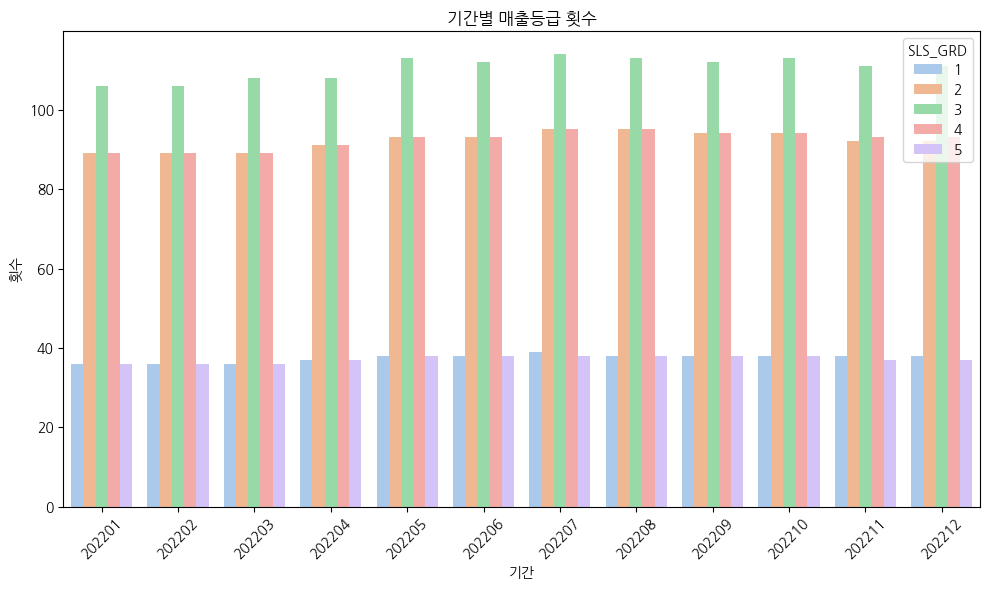

In [ ]:
#아이스크림/빙수 A09의 월별 매출등급변화 및 가게별 특징
A09_m=all_data[all_data['INDUSTRY_CD']=='A09'].reset_index().drop('index',axis=1)
# 각 기간과 매출등급으로 묶어주기
A09_mmonth=A09_m.groupby(['DATA_CRTR_YM', 'SLS_GRD']).size().reset_index(name='횟수')
# 그래프 그리기
import warnings
warnings.filterwarnings('ignore')

plt.figure(figsize=(10, 6))
sns.barplot(data=A09_mmonth, x='DATA_CRTR_YM', y='횟수', hue='SLS_GRD', palette='pastel')
plt.title('기간별 매출등급 횟수')
plt.xlabel('기간')
plt.ylabel('횟수')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
#해당 가게의 전체 매출등급 합을 구한다.
A09_maa=A09_m.groupby(['LT_UNQ_NO']).sum('SLS_GRD')['SLS_GRD'].reset_index(name='매출등급합')
#해당 가게의 전체 운영달의 횟수를 구한다.
A09_ma=A09_m.groupby(['LT_UNQ_NO']).size().reset_index(name='횟수')
#해당 가게에 매출등급의 합과 운영달의 횟수 데이터를 붙여준다.
A09_maaa=A09_ma.merge(A09_maa,how='left')
# 매출등급 평균 열 생성하기
A09_maaa['매출등급 평균']=A09_maaa['매출등급합']/A09_maaa['횟수']
A09_maaa=A09_maaa[['LT_UNQ_NO','매출등급 평균','매출등급합','횟수']]
#영업기간이 1년인 가게
A09_12=A09_maaa[A09_maaa['횟수']==12]
A09_12=A09_12.reset_index()
A09_12

,index,LT_UNQ_NO,매출등급 평균,매출등급합,횟수
0,1,1111013300101260001,4.583333,55,12
1,2,1111013800100840001,1.583333,19,12
2,3,1111014000100630019,2.250000,27,12
3,4,1111014300101370006,2.166667,26,12
4,5,1111014700101060004,3.000000,36,12
...,...,...,...,...,...
319,404,1174010800104280006,2.250000,27,12
320,405,1174010800104290003,3.833333,46,12
321,406,1174010900100340006,2.583333,31,12
322,407,1174010900104540013,2.833333,34,12


In [ ]:
#영업기간이 1년인 곳 중에서
#매출등급평균 상위 100개 가게
A09_12_top=A09_12.sort_values('매출등급 평균',ascending=True)[0:100]['LT_UNQ_NO'].reset_index()
A09_12_top_all=A09_12_top.merge(A09_m,how='left',on='LT_UNQ_NO').drop('index',axis=1).groupby(['LT_UNQ_NO','DATA_CRTR_YM']).mean()
A09_12_top_all0=A09_12_top_all[['pul_party_sopsrt_dims','fpop_scor_property','fpop_scor',	'gtfc_scor',	'plot_dims','총생활인구수','지하철역']]
A09_12_top_all0.describe()

,pul_party_sopsrt_dims,fpop_scor_property,fpop_scor,gtfc_scor,plot_dims,총생활인구수,지하철역
count,1092.000000,543.000000,1176.000000,908.000000,1140.000000,1200.000000,1200.00000
mean,8.217418,40.677017,58.004753,51.081156,8608.017806,27092.706111,2.22000
std,46.395944,19.435617,21.132791,13.576075,23688.805439,11444.928873,1.64738
min,0.010000,4.240000,6.320000,19.660000,47.659058,1321.523200,0.00000
25%,0.060000,25.210000,43.595000,41.567500,324.147583,19009.059500,1.00000
50%,0.150000,40.200000,57.320000,47.545000,612.416870,26371.461000,2.00000
75%,0.442500,59.330000,72.755000,56.972500,2390.795898,33661.504925,3.00000
max,402.740000,78.440000,98.050000,99.900000,159281.931641,70345.421200,9.00000


In [ ]:
#매출등급 하위 100개 가게
A09_12_low=A09_12.sort_values('매출등급 평균',ascending=False)[0:100]['LT_UNQ_NO'].reset_index()
A09_12_low_all=A09_12_low.merge(A09_m,how='left',on='LT_UNQ_NO').drop('index',axis=1).groupby(['LT_UNQ_NO','DATA_CRTR_YM']).mean()
A09_12_low_all0=A09_12_low_all[['pul_party_sopsrt_dims','fpop_scor_property','fpop_scor',	'gtfc_scor',	'plot_dims','총생활인구수','지하철역']]
A09_12_low_all0.describe()

,pul_party_sopsrt_dims,fpop_scor_property,fpop_scor,gtfc_scor,plot_dims,총생활인구수,지하철역
count,1044.000000,567.000000,1188.000000,916.000000,1200.000000,1200.000000,1200.00000
mean,1.117213,39.219259,58.518754,50.073712,5631.319616,26951.454509,1.82000
std,4.693400,17.726221,21.132100,15.928122,14464.147224,12713.077666,1.57787
min,0.010000,5.300000,8.540000,10.980000,26.460205,3518.576600,0.00000
25%,0.060000,25.750000,41.697500,40.307500,200.364899,18424.035100,1.00000
50%,0.200000,39.140000,61.755000,47.070000,445.489807,23432.969600,1.00000
75%,0.520000,52.010000,72.875000,57.370000,2581.868195,32349.980900,2.00000
max,42.130000,73.480000,97.420000,100.000000,113959.376343,70345.421200,10.00000


#### A10-기타외국식
창업하는 매장의 수가 꾸준히 증가하였고,
매출등급 상위의 가게와 매출등급 하위 가게의 비교결과,

상위 가게들이 하위가게들보다

 plot_dims 평균 차이가 약 1500 높으며,

 총생활인구수 평균 차이가 약 5000높으며,

 지하철역 갯수차이는 0.7정도차이 나지만 이것은 매출 등급에 큰영향을 주지 못하였다.

즉,상위100개매장과 하위 100개 매장의 plot_dims와 특히, 총생활인구수의 차이가 매출등급에 영향을 크게 준것으로 분석된다.

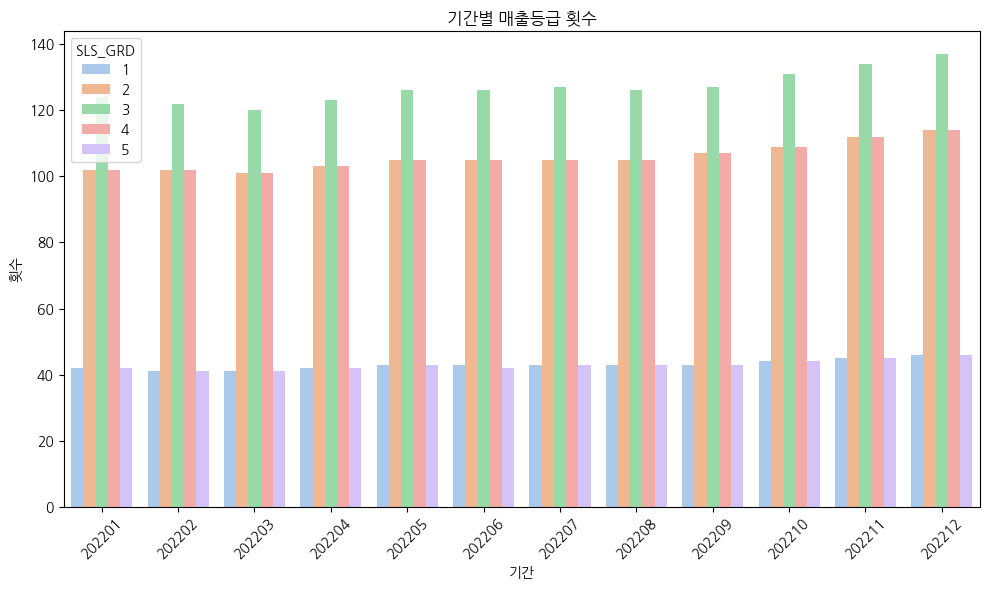

In [ ]:
#기타외국식 A10의 월별 매출등급변화 및 가게별 특징
A10_m=all_data[all_data['INDUSTRY_CD']=='A10'].reset_index().drop('index',axis=1)
# 각 기간과 매출등급으로 묶어주기
A10_mmonth=A10_m.groupby(['DATA_CRTR_YM', 'SLS_GRD']).size().reset_index(name='횟수')
# 그래프 그리기
import warnings
warnings.filterwarnings('ignore')

plt.figure(figsize=(10, 6))
sns.barplot(data=A10_mmonth, x='DATA_CRTR_YM', y='횟수', hue='SLS_GRD', palette='pastel')
plt.title('기간별 매출등급 횟수')
plt.xlabel('기간')
plt.ylabel('횟수')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
#해당 가게의 전체 매출등급 합을 구한다.
A10_maa=A10_m.groupby(['LT_UNQ_NO']).sum('SLS_GRD')['SLS_GRD'].reset_index(name='매출등급합')
#해당 가게의 전체 운영달의 횟수를 구한다.
A10_ma=A10_m.groupby(['LT_UNQ_NO']).size().reset_index(name='횟수')
#해당 가게에 매출등급의 합과 운영달의 횟수 데이터를 붙여준다.
A10_maaa=A10_ma.merge(A10_maa,how='left')
# 매출등급 평균 열 생성하기
A10_maaa['매출등급 평균']=A10_maaa['매출등급합']/A10_maaa['횟수']
A10_maaa=A10_maaa[['LT_UNQ_NO','매출등급 평균','매출등급합','횟수']]
#영업기간이 1년인 가게
A10_12=A10_maaa[A10_maaa['횟수']==12]
A10_12=A10_12.reset_index()
A10_12

,index,LT_UNQ_NO,매출등급 평균,매출등급합,횟수
0,1,1111011600100600000,2.833333,34,12
1,2,1111011800100730000,1.000000,12,12
2,3,1111012200100700000,1.000000,12,12
3,4,1111012600100240000,1.000000,12,12
4,5,1111013300101620000,3.000000,36,12
...,...,...,...,...,...
326,521,1174010900100540010,4.000000,48,12
327,523,1174010900101680006,4.666667,56,12
328,525,1174010900102880000,2.750000,33,12
329,527,1174010900104250005,3.166667,38,12


In [ ]:
#영업기간이 1년인 곳 중에서
#매출등급평균 상위 100개 가게
A10_12_top=A10_12.sort_values('매출등급 평균',ascending=True)[0:100]['LT_UNQ_NO'].reset_index()
A10_12_top_all=A10_12_top.merge(A10_m,how='left',on='LT_UNQ_NO').drop('index',axis=1).groupby(['LT_UNQ_NO','DATA_CRTR_YM']).mean()
A10_12_top_all0=A10_12_top_all[['pul_party_sopsrt_dims','fpop_scor_property','fpop_scor',	'gtfc_scor',	'plot_dims','총생활인구수','지하철역']]
A10_12_top_all0.describe()

,pul_party_sopsrt_dims,fpop_scor_property,fpop_scor,gtfc_scor,plot_dims,총생활인구수,지하철역
count,1068.000000,435.000000,1142.000000,926.000000,1164.000000,1200.000000,1200.000000
mean,0.355927,38.493310,53.387995,51.337214,3798.908048,31254.353255,2.670000
std,0.648066,14.434535,19.086907,9.505690,8210.024931,12837.790555,1.674346
min,0.010000,2.740000,5.960000,30.970000,22.436157,6281.724000,0.000000
25%,0.040000,26.100000,41.010000,46.782500,211.871704,20177.333100,2.000000
50%,0.120000,38.680000,51.695000,49.005000,509.542236,30556.177500,2.000000
75%,0.290000,50.520000,61.400000,52.875000,3287.517334,39168.827300,4.000000
max,3.560000,67.750000,99.010000,100.000000,54266.953613,70345.421200,7.000000


In [ ]:
#매출등급 하위 100개 가게
A10_12_low=A10_12.sort_values('매출등급 평균',ascending=False)[0:100]['LT_UNQ_NO'].reset_index()
A10_12_low_all=A10_12_low.merge(A10_m,how='left',on='LT_UNQ_NO').drop('index',axis=1).groupby(['LT_UNQ_NO','DATA_CRTR_YM']).mean()
A10_12_low_all0=A10_12_low_all[['pul_party_sopsrt_dims','fpop_scor_property','fpop_scor',	'gtfc_scor',	'plot_dims','총생활인구수','지하철역']]
A10_12_low_all0.describe()

,pul_party_sopsrt_dims,fpop_scor_property,fpop_scor,gtfc_scor,plot_dims,총생활인구수,지하철역
count,1056.000000,348.000000,1164.000000,893.000000,1200.000000,1200.000000,1200.000000
mean,0.143295,37.322845,55.328900,48.390314,2157.290520,26827.716812,1.960000
std,0.170729,14.243825,21.769446,11.869821,14370.730084,12271.538299,1.496752
min,0.010000,11.060000,14.820000,24.550000,5.026489,1321.523200,0.000000
25%,0.050000,28.847500,39.542500,41.970000,138.223542,18115.232350,1.000000
50%,0.090000,36.195000,52.180000,46.640000,191.118897,24474.387200,2.000000
75%,0.190000,46.007500,64.577500,50.720000,371.979279,33610.617400,3.000000
max,1.450000,78.410000,98.980000,100.000000,143843.786255,70345.421200,8.000000


#### A12-주점
창업하는 주점의 수가 3월과 4월에 확 증가하였다.


---



다른 업종과 다르게 pul_party_sopsrt_dims가 큰쪽이 오히려 매출등급이 저조하였다.

gtfc_scor를 제외한

fpop_scor_property 평균 차이가 약 10 높으며,

fpop_scor	평균 차이가 약5 높으며,

plot_dims	평균 차이가 약500 높으며,

총생활인구수 평균 차이가 약	8000 높으며,

지하철역 평균 차이가 약 0.8 높았다.

---

fpop_scor_property,  fpop_scor 특히 총생활인구수에서 큰차이를 보여주었다.

다른 업종과 달리 지하철역의 갯수가 3개 이상일 경우 매출등급이 좋은쪽인 경향을 보였다.

즉, 가게가 위치한 곳 주변에 지하철역 갯수(유동인구 수와 생활거주인구수)가 많지만 그에 비해 가게 면적이 그리 넓지 않아도 괜찮을 경우 주점을 하는 것도 괜찮은 방향이다.

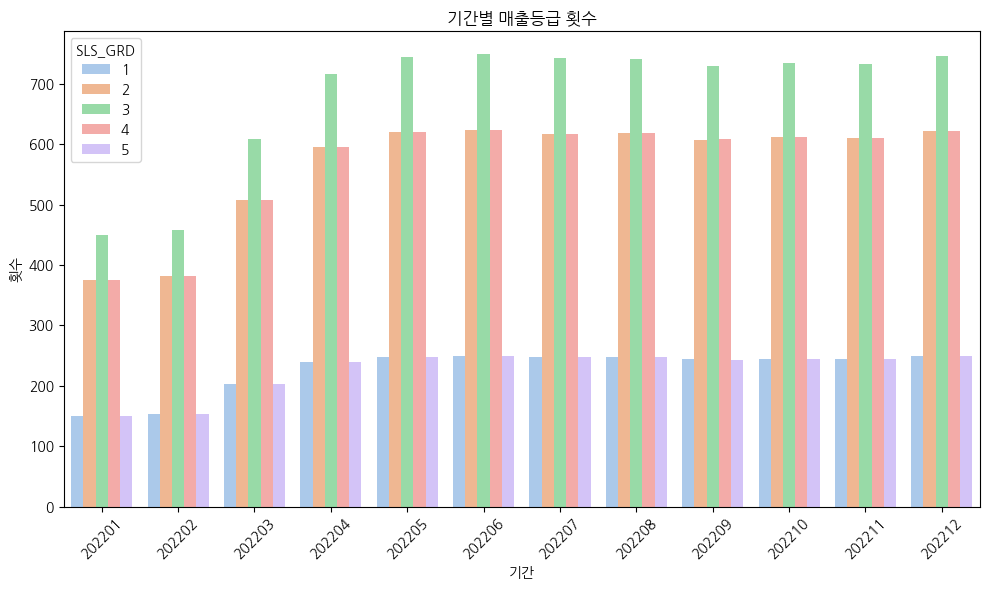

In [ ]:
#주점 A12의 월별 매출등급변화 및 가게별 특징
A12_m=all_data[all_data['INDUSTRY_CD']=='A12'].reset_index().drop('index',axis=1)
# 각 기간과 매출등급으로 묶어주기
A12_mmonth=A12_m.groupby(['DATA_CRTR_YM', 'SLS_GRD']).size().reset_index(name='횟수')
# 그래프 그리기
import warnings
warnings.filterwarnings('ignore')

plt.figure(figsize=(10, 6))
sns.barplot(data=A12_mmonth, x='DATA_CRTR_YM', y='횟수', hue='SLS_GRD', palette='pastel')
plt.title('기간별 매출등급 횟수')
plt.xlabel('기간')
plt.ylabel('횟수')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
#해당 가게의 전체 매출등급 합을 구한다.
A12_maa=A12_m.groupby(['LT_UNQ_NO']).sum('SLS_GRD')['SLS_GRD'].reset_index(name='매출등급합')
#해당 가게의 전체 운영달의 횟수를 구한다.
A12_ma=A12_m.groupby(['LT_UNQ_NO']).size().reset_index(name='횟수')
#해당 가게에 매출등급의 합과 운영달의 횟수 데이터를 붙여준다.
A12_maaa=A12_ma.merge(A12_maa,how='left')
# 매출등급 평균 열 생성하기
A12_maaa['매출등급 평균']=A12_maaa['매출등급합']/A12_maaa['횟수']
A12_maaa=A12_maaa[['LT_UNQ_NO','매출등급 평균','매출등급합','횟수']]
#영업기간이 1년인 가게
A12_12=A12_maaa[A12_maaa['횟수']==12]
A12_12=A12_12.reset_index()
A12_12

,index,LT_UNQ_NO,매출등급 평균,매출등급합,횟수
0,2,1111011700100020003,2.916667,35,12
1,3,1111011700100420002,1.666667,20,12
2,4,1111011700101000000,1.583333,19,12
3,10,1111012200100110006,2.500000,30,12
4,11,1111012200101400000,2.166667,26,12
...,...,...,...,...,...
995,2884,1174010900104540015,1.000000,12,12
996,2885,1174010900104540017,2.916667,35,12
997,2886,1174010900104540039,3.166667,38,12
998,2887,1174010900104540053,1.166667,14,12


In [ ]:
#영업기간이 1년인 곳 중에서
#매출등급평균 상위 100개 가게
A12_12_top=A12_12.sort_values('매출등급 평균',ascending=True)[0:100]['LT_UNQ_NO'].reset_index()
A12_12_top_all=A12_12_top.merge(A12_m,how='left',on='LT_UNQ_NO').drop('index',axis=1).groupby(['LT_UNQ_NO','DATA_CRTR_YM']).mean()
A12_12_top_all0=A12_12_top_all[['pul_party_sopsrt_dims','fpop_scor_property','fpop_scor',	'gtfc_scor',	'plot_dims','총생활인구수','지하철역']]
A12_12_top_all0.describe()

,pul_party_sopsrt_dims,fpop_scor_property,fpop_scor,gtfc_scor,plot_dims,총생활인구수,지하철역
count,1077.000000,1065.000000,1200.000000,941.000000,1200.000000,1200.000000,1200.000000
mean,0.249276,30.754648,49.168317,50.695133,868.562136,34455.468514,3.310000
std,0.415934,19.195324,13.146702,4.539959,984.089817,13704.829255,1.984233
min,0.010000,1.590000,13.880000,43.620000,22.479858,4137.342800,0.000000
25%,0.050000,14.740000,40.962500,49.730000,366.633514,25161.953000,2.000000
50%,0.090000,24.790000,49.675000,49.800000,653.694336,32786.198000,3.000000
75%,0.220000,49.670000,59.280000,50.120000,978.031067,42275.094975,4.000000
max,2.510000,78.440000,80.860000,99.980000,6753.789185,70345.421200,9.000000


In [ ]:
#매출등급 하위 100개 가게
A12_12_low=A12_12.sort_values('매출등급 평균',ascending=False)[0:100]['LT_UNQ_NO'].reset_index()
A12_12_low_all=A12_12_low.merge(A12_m,how='left',on='LT_UNQ_NO').drop('index',axis=1).groupby(['LT_UNQ_NO','DATA_CRTR_YM']).mean()
A12_12_low_all0=A12_12_low_all[['pul_party_sopsrt_dims','fpop_scor_property','fpop_scor',	'gtfc_scor',	'plot_dims','총생활인구수','지하철역']]
A12_12_low_all0.describe()

,pul_party_sopsrt_dims,fpop_scor_property,fpop_scor,gtfc_scor,plot_dims,총생활인구수,지하철역
count,1152.000000,861.000000,1188.000000,887.000000,1200.000000,1200.000000,1200.00000
mean,0.616042,41.526516,54.103418,49.944543,353.583344,26898.430822,2.52000
std,3.135647,14.129518,15.195861,2.897092,595.159957,11217.020600,1.84728
min,0.010000,6.620000,13.700000,42.580000,40.733398,3518.576600,0.00000
25%,0.040000,30.630000,46.912500,49.610000,137.537842,19529.640375,1.00000
50%,0.115000,42.700000,56.925000,49.740000,201.859253,24869.823600,2.00000
75%,0.310000,52.330000,65.600000,49.810000,331.241272,33640.094300,3.00000
max,43.230000,74.060000,80.630000,99.270000,4046.539673,68866.208300,9.00000


# 4. train 데이터 전처리

In [ ]:
all_data = pd.read_csv('/content/drive/MyDrive/빅콘테스트/데이터/all_data(null).csv')

In [ ]:
all_data

,DATA_CRTR_YM,LT_UNQ_NO,STDG_EMD_CD,INDUSTRY_CD,SLS_GRD,pul_party_sopsrt_dims,fpop_scor_property,상권_변화_지표,fpop_scor,gtfc_scor,plot_dims,경도,위도,총생활인구수,지하철역
0,202201,1111010100100030100,11110101,A03,4,0.47,19.76,LH,89.26,NaN,934.011841,126.966923,37.592027,15346.7477,0
1,202201,1111010100100480000,11110101,A01,2,1.40,39.13,LH,59.29,59.42,386.339233,126.969415,37.587042,15346.7477,0
2,202201,1111010100100590001,11110101,A11,3,0.34,27.26,LH,53.20,48.86,6.136597,126.969893,37.586417,15346.7477,0
3,202201,1111010100100590005,11110101,A03,2,0.15,21.03,LH,91.49,46.78,100.975708,126.969359,37.586218,15346.7477,0
4,202201,1111010100100690000,11110101,A01,2,1.75,23.93,LH,45.40,50.58,311.235596,126.970119,37.586430,15346.7477,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1156035,202212,1174011000106950000,11740110,A03,4,0.04,60.07,LL,65.91,NaN,40938.943848,127.180761,37.559969,55528.9932,2
1156036,202212,1174011000106950000,11740110,A04,3,0.04,50.85,LL,66.38,NaN,40938.943848,127.180761,37.559969,55528.9932,2
1156037,202212,1174011000106990000,11740110,A01,4,0.03,26.61,LL,59.94,NaN,52146.748779,127.178826,37.559850,55528.9932,2
1156038,202212,1174011000107070000,11740110,A03,4,0.05,41.32,LL,51.30,NaN,31270.143188,127.171665,37.561180,55528.9932,3


* 로그변환

In [ ]:
# plot_dims 컬럼에 대한 로그변환
all_data['plot_dims'] = np.log(all_data['plot_dims'])
# pul_party_sopsrt_dims 컬럼에 대한 로그변환
all_data['pul_party_sopsrt_dims'] = np.log(all_data['pul_party_sopsrt_dims'])

In [ ]:
all_data = all_data[['STDG_EMD_CD',	'SLS_GRD','INDUSTRY_CD', 'fpop_scor',	'gtfc_scor',	'plot_dims',	'pul_party_sopsrt_dims',	'fpop_scor_property',	'경도',	'위도', '지하철역', '상권_변화_지표','총생활인구수']]

* 범주형 변수 라벨 인코딩

In [ ]:
from sklearn.preprocessing import LabelEncoder

for i in ['INDUSTRY_CD', '상권_변화_지표']:
  encoder = LabelEncoder()
  encoder= encoder.fit(all_data[i])
  all_data[i]= encoder.transform(all_data[i]) + 1
all_data

,STDG_EMD_CD,SLS_GRD,INDUSTRY_CD,fpop_scor,gtfc_scor,plot_dims,pul_party_sopsrt_dims,fpop_scor_property,경도,위도,지하철역,상권_변화_지표,총생활인구수
0,11110101,4,3,89.26,NaN,6.839489,-0.755023,19.76,126.966923,37.592027,0,3,15346.7477
1,11110101,2,1,59.29,59.42,5.956716,0.336472,39.13,126.969415,37.587042,0,3,15346.7477
2,11110101,3,11,53.20,48.86,1.814270,-1.078810,27.26,126.969893,37.586417,0,3,15346.7477
3,11110101,2,3,91.49,46.78,4.614880,-1.897120,21.03,126.969359,37.586218,0,3,15346.7477
4,11110101,2,1,45.40,50.58,5.740550,0.559616,23.93,126.970119,37.586430,0,3,15346.7477
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1156035,11740110,4,3,65.91,NaN,10.619837,-3.218876,60.07,127.180761,37.559969,2,4,55528.9932
1156036,11740110,3,4,66.38,NaN,10.619837,-3.218876,50.85,127.180761,37.559969,2,4,55528.9932
1156037,11740110,4,1,59.94,NaN,10.861817,-3.506558,26.61,127.178826,37.559850,2,4,55528.9932
1156038,11740110,4,3,51.30,NaN,10.350419,-2.995732,41.32,127.171665,37.561180,3,4,55528.9932


In [ ]:
all_data_test1 = all_data.drop(['SLS_GRD'], axis=1) # test데이터 전처리에 이용하기 위함
all_data_test2 = all_data.drop(['SLS_GRD'], axis=1)

In [ ]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
cols = all_data.columns.to_list()

# 범주형 변수 제외
cols.remove('SLS_GRD')
cols.remove('INDUSTRY_CD')
cols.remove('STDG_EMD_CD')
cols.remove('상권_변화_지표')

for col in cols:
    all_data[col] = scaler.fit_transform(all_data[[col]])
all_data

,STDG_EMD_CD,SLS_GRD,INDUSTRY_CD,fpop_scor,gtfc_scor,plot_dims,pul_party_sopsrt_dims,fpop_scor_property,경도,위도,지하철역,상권_변화_지표,총생활인구수
0,11110101,4,3,2.03669,NaN,0.83725,0.83874,-2.11703,-0.34966,0.92953,-1.26516,3,-0.92093
1,11110101,2,1,0.01896,1.31142,0.16502,1.62189,-0.69534,-0.32009,0.82541,-1.26516,3,-0.92093
2,11110101,3,11,-0.39105,-0.10146,-2.98949,0.60642,-1.56655,-0.31442,0.81236,-1.26516,3,-0.92093
3,11110101,2,3,2.18683,-0.37975,-0.85680,0.01928,-2.02381,-0.32076,0.80819,-1.26516,3,-0.92093
4,11110101,2,1,-0.91618,0.12867,0.00040,1.78199,-1.81096,-0.31174,0.81263,-1.26516,3,-0.92093
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1156035,11740110,4,3,0.46465,NaN,3.71602,-0.92908,0.84159,2.18793,0.25992,-0.17994,4,2.42428
1156036,11740110,3,4,0.49630,NaN,3.71602,-0.92908,0.16487,2.18793,0.25992,-0.17994,4,2.42428
1156037,11740110,4,1,0.06272,NaN,3.90029,-1.13550,-1.61426,2.16496,0.25743,-0.17994,4,2.42428
1156038,11740110,4,3,-0.51897,NaN,3.51086,-0.76898,-0.53460,2.07999,0.28522,0.36267,4,2.42428


* knn imputer 사용한 결측치 처리

In [ ]:
from sklearn.impute import KNNImputer

imputer = KNNImputer(n_neighbors=3)
imputer.fit(all_data) # all_data로 학습
all_data_n_filled = imputer.transform(all_data) # all_data 결측치 채우기
a =pd.DataFrame(all_data_n_filled, columns=all_data.columns)

In [ ]:
train = a.iloc[:961096]    # 1~10월 train 데이터
test = a.iloc[961096:]    # 11~12월 test 데이터

In [ ]:
train.to_csv('train지표+생활+all+knn3.csv', index=False)
test.to_csv('test지표+생활+all+knn3.csv', index=False)

# 5. test 데이터 전처리

In [ ]:
# 소상공인 매출등급 예상 대상 필지 데이터를 가져온다
test_data1 = pd.read_excel('/content/drive/MyDrive/빅콘테스트/데이터/2023빅콘테스트_빅데이터플랫폼활용분야_지정주제(부동산)_데이터셋/소상공인 매출등급 예상 대상 필지.xlsx')
test_data2 = pd.read_excel('/content/drive/MyDrive/빅콘테스트/데이터/2023빅콘테스트_빅데이터플랫폼활용분야_지정주제(부동산)_데이터셋/소상공인 매출등급 예상 대상 필지.xlsx')
test_data1.drop(['SLS_GRD_2301', 'SLS_GRD_2302'], axis=1, inplace=True)
test_data2.drop(['SLS_GRD_2301', 'SLS_GRD_2302'], axis=1, inplace=True)
test_data1

,LT_UNQ_NO,INDUSTRY_CD,STDG_EMD_CD
0,1168010800102090000,A01,11680108
1,1135010300106330015,A05,11350103
2,1154510200109830004,A02,11545102
3,1162010200100920362,A01,11620102
4,1168011000104580000,A03,11680110
...,...,...,...
9995,1130510100100830004,A03,11305101
9996,1135010300107450000,A13,11350103
9997,1150010300103400017,A06,11500103
9998,1144012700116070000,A03,11440127


## 1. 배후지 인구당 상가면적

In [ ]:
from glob import glob

file_names = glob("/content/drive/MyDrive/빅콘테스트/데이터/배후지 인구당 상가면적/*.csv") #폴더 내의 모든 csv파일 목록을 불러온다
total = pd.DataFrame() #빈 데이터프레임 하나를 생성한다

for file_name in file_names:
    temp = pd.read_csv(file_name, sep='|')
    res = pd.read_csv(file_name, sep='|')
    for i in range(2):   # 1분기라면 3월 데이터만 있으니까 3월 값을 그대로 갖는 1월 2월 데이터를 추가하는 과정
      if '20221' in file_name:           # 22년 1분기 데이터
        res.loc[:, "data_strd_ym"] = 202201+i # 3월을 1월, 2월로 변경
        temp = pd.concat([temp, res])
      elif '20222' in file_name:          # 22년 2분기 데이터
        res.loc[:, "data_strd_ym"] = 202204+i
        temp = pd.concat([temp, res])
      elif '20223' in file_name:
        res.loc[:, "data_strd_ym"] = 202207+i
        temp = pd.concat([temp, res])
      elif '20224' in file_name:
        res.loc[:, "data_strd_ym"] = 202210+i
        temp = pd.concat([temp, res])
      elif '20231' in file_name:
        res.loc[:, "data_strd_ym"] = 202301+i
        temp = pd.concat([temp, res])
    total = pd.concat([total, temp])

In [ ]:
total.sort_values('data_strd_ym', inplace=True)

In [ ]:
total.columns = ['DATA_CRTR_YM', 'LT_UNQ_NO', 'STDG_EMD_CD', 'INDUSTRY_CD', 'pul_party_sopsrt_dims'] # merge를 위해 컬럼명 바꾸기

In [ ]:
total['DATA_CRTR_YM'] = total['DATA_CRTR_YM'].astype(str) # str로 타입 변경

* 23년 1월

In [ ]:
b202301 = total.loc[total['DATA_CRTR_YM']=='202301'] # 23년 1월 데이터만 저장
b202301

,DATA_CRTR_YM,LT_UNQ_NO,STDG_EMD_CD,INDUSTRY_CD,pul_party_sopsrt_dims
730171,202301,4213010500103860016,42130105,A01,0.25
730170,202301,4213010500103860009,42130105,A01,0.63
730169,202301,4213010500103860003,42130105,A15,0.07
730168,202301,4213010500103850023,42130105,C01,0.18
730181,202301,4213010500103870022,42130105,C06,0.24
...,...,...,...,...,...
365069,202301,2823710400103010023,28237104,B15,0.29
365082,202301,2823710400103020000,28237104,A03,4.29
365080,202301,2823710400103010029,28237104,C07,0.28
365081,202301,2823710400103010034,28237104,A01,0.68


In [ ]:
# 2023년 1월 필지 데이터와 merge해준다
jantest1 = pd.merge(test_data1, b202301, how='left', on=['LT_UNQ_NO', 'STDG_EMD_CD', 'INDUSTRY_CD'])
jantest1 = jantest1[['LT_UNQ_NO', 'INDUSTRY_CD', 'STDG_EMD_CD', 'pul_party_sopsrt_dims']]
jantest1

,LT_UNQ_NO,INDUSTRY_CD,STDG_EMD_CD,pul_party_sopsrt_dims
0,1168010800102090000,A01,11680108,0.29
1,1135010300106330015,A05,11350103,NaN
2,1154510200109830004,A02,11545102,0.19
3,1162010200100920362,A01,11620102,0.11
4,1168011000104580000,A03,11680110,NaN
...,...,...,...,...
9995,1130510100100830004,A03,11305101,0.46
9996,1135010300107450000,A13,11350103,0.10
9997,1150010300103400017,A06,11500103,0.14
9998,1144012700116070000,A03,11440127,0.05


* 23년 2월

In [ ]:
b202302 = total.loc[total['DATA_CRTR_YM']=='202302'] # 23년 2월만 불러온다
b202302

,DATA_CRTR_YM,LT_UNQ_NO,STDG_EMD_CD,INDUSTRY_CD,pul_party_sopsrt_dims
357070,202302,2820011000101090038,28200110,C05,50.89
357069,202302,2820011000101090037,28200110,A01,3.78
357068,202302,2820011000101090035,28200110,C01,3.27
357067,202302,2820011000101090035,28200110,B19,3.27
357066,202302,2820011000101090035,28200110,A07,3.27
...,...,...,...,...,...
722168,202302,4211011200100200013,42110112,A01,0.47
722149,202302,4211011200100180041,42110112,C01,0.27
722150,202302,4211011200100180042,42110112,A14,0.18
722151,202302,4211011200100180043,42110112,A03,0.28


In [ ]:
# 23년 2월 필지 데이터와 merge 해준다
febtest1 = pd.merge(test_data2, b202302, how='left', on=['LT_UNQ_NO', 'STDG_EMD_CD', 'INDUSTRY_CD'])
febtest1 = febtest1[['LT_UNQ_NO', 'INDUSTRY_CD', 'STDG_EMD_CD', 'pul_party_sopsrt_dims']]
febtest1

,LT_UNQ_NO,INDUSTRY_CD,STDG_EMD_CD,pul_party_sopsrt_dims
0,1168010800102090000,A01,11680108,0.29
1,1135010300106330015,A05,11350103,NaN
2,1154510200109830004,A02,11545102,0.19
3,1162010200100920362,A01,11620102,0.11
4,1168011000104580000,A03,11680110,NaN
...,...,...,...,...
9995,1130510100100830004,A03,11305101,0.46
9996,1135010300107450000,A13,11350103,0.10
9997,1150010300103400017,A06,11500103,0.14
9998,1144012700116070000,A03,11440127,0.05


## 2. 부동산거래량대비유동인구

In [ ]:
# 23년 1분기 데이터만 불러온다
fsp = pd.read_csv('/content/drive/MyDrive/빅콘테스트/데이터/부동산거래량 (금액)대비 유동인구/부동산거래량 (금액) 대비 유동인구(20231Q).csv', sep='|')
fsp.drop('data_strd_ym', axis=1, inplace=True)

In [ ]:
fsp

,pnu,legaldong_cd,induty_cd,fpop_scor
0,1111010100100010000,11110101,C05,41.34
1,1111010100100030100,11110101,A03,23.35
2,1111010100100040014,11110101,B01,6.82
3,1111010100100050000,11110101,C01,12.21
4,1111010100100420003,11110101,C03,27.93
...,...,...,...,...
1168433,5013032026105370003,50130320,A01,3.48
1168434,5013032026108360001,50130320,A01,2.96
1168435,5013032026113660001,50130320,C06,3.23
1168436,5013032026113660001,50130320,A01,3.90


In [ ]:
fsp.columns = ['LT_UNQ_NO', 'STDG_EMD_CD', 'INDUSTRY_CD', 'fpop_scor_property'] # 컬럼명 수정

* 23년 1월

In [ ]:
# jantest1 + 부동산거래량대비유동인구인 jantest2 생성
jantest2 = pd.merge(jantest1, fsp, how='left', on=['LT_UNQ_NO', 'STDG_EMD_CD', 'INDUSTRY_CD'] )
jantest2

,LT_UNQ_NO,INDUSTRY_CD,STDG_EMD_CD,pul_party_sopsrt_dims,fpop_scor_property
0,1168010800102090000,A01,11680108,0.29,45.06
1,1135010300106330015,A05,11350103,NaN,NaN
2,1154510200109830004,A02,11545102,0.19,41.53
3,1162010200100920362,A01,11620102,0.11,61.00
4,1168011000104580000,A03,11680110,NaN,NaN
...,...,...,...,...,...
9995,1130510100100830004,A03,11305101,0.46,52.98
9996,1135010300107450000,A13,11350103,0.10,36.41
9997,1150010300103400017,A06,11500103,0.14,45.98
9998,1144012700116070000,A03,11440127,0.05,56.97


* 23년 2월

In [ ]:
# febtest1 + 부동산거래량대비유동인구인 febtest2 생성
febtest2 = pd.merge(febtest1, fsp, how='left', on=['LT_UNQ_NO', 'STDG_EMD_CD', 'INDUSTRY_CD'] )
febtest2

,LT_UNQ_NO,INDUSTRY_CD,STDG_EMD_CD,pul_party_sopsrt_dims,fpop_scor_property
0,1168010800102090000,A01,11680108,0.29,45.06
1,1135010300106330015,A05,11350103,NaN,NaN
2,1154510200109830004,A02,11545102,0.19,41.53
3,1162010200100920362,A01,11620102,0.11,61.00
4,1168011000104580000,A03,11680110,NaN,NaN
...,...,...,...,...,...
9995,1130510100100830004,A03,11305101,0.46,52.98
9996,1135010300107450000,A13,11350103,0.10,36.41
9997,1150010300103400017,A06,11500103,0.14,45.98
9998,1144012700116070000,A03,11440127,0.05,56.97


## 3. 상권변화지표

In [ ]:
cdci = pd.read_csv("/content/drive/MyDrive/빅콘테스트/데이터/행정동별 상권변화지표/서울시 상권분석서비스(행정동별 상권변화지표).csv", encoding = 'cp949')
cdci

,기준_년_코드,기준_분기_코드,행정동_코드,행정동_코드_명,상권_변화_지표,상권_변화_지표_명,운영_영업_개월_평균,폐업_영업_개월_평균,서울_운영_영업_개월_평균,서울_폐업_영업_개월_평균
0,2023,1,11740700,둔촌2동,HL,상권축소,106,49,104,52
1,2023,1,11740690,둔촌1동,HH,정체,160,62,104,52
2,2023,1,11740685,길동,LL,다이나믹,102,47,104,52
3,2023,1,11740660,성내3동,HL,상권축소,109,46,104,52
4,2023,1,11740650,성내2동,LL,다이나믹,103,45,104,52
...,...,...,...,...,...,...,...,...,...,...
15684,2014,1,11110560,평창동,HH,정체,95,51,92,45
15685,2014,1,11110550,부암동,LH,상권확장,92,48,92,45
15686,2014,1,11110540,삼청동,LH,상권확장,78,49,92,45
15687,2014,1,11110530,사직동,HH,정체,103,51,92,45


In [ ]:
# 2023년 데이터만 불러오기
cdci = cdci[cdci['기준_년_코드']==2023]
cdci

,기준_년_코드,기준_분기_코드,행정동_코드,행정동_코드_명,상권_변화_지표,상권_변화_지표_명,운영_영업_개월_평균,폐업_영업_개월_평균,서울_운영_영업_개월_평균,서울_폐업_영업_개월_평균
0,2023,1,11740700,둔촌2동,HL,상권축소,106,49,104,52
1,2023,1,11740690,둔촌1동,HH,정체,160,62,104,52
2,2023,1,11740685,길동,LL,다이나믹,102,47,104,52
3,2023,1,11740660,성내3동,HL,상권축소,109,46,104,52
4,2023,1,11740650,성내2동,LL,다이나믹,103,45,104,52
...,...,...,...,...,...,...,...,...,...,...
420,2023,1,11110560,평창동,HH,정체,111,58,104,52
421,2023,1,11110550,부암동,LH,상권확장,99,56,104,52
422,2023,1,11110540,삼청동,LH,상권확장,99,55,104,52
423,2023,1,11110530,사직동,HH,정체,122,59,104,52


In [ ]:
cdci=cdci[['기준_분기_코드', '행정동_코드', '행정동_코드_명', '상권_변화_지표']] # 필요한 변수만 불러오기
cdci

,기준_분기_코드,행정동_코드,행정동_코드_명,상권_변화_지표
0,1,11740700,둔촌2동,HL
1,1,11740690,둔촌1동,HH
2,1,11740685,길동,LL
3,1,11740660,성내3동,HL
4,1,11740650,성내2동,LL
...,...,...,...,...
420,1,11110560,평창동,HH
421,1,11110550,부암동,LH
422,1,11110540,삼청동,LH
423,1,11110530,사직동,HH


* 분기별로 나눠서 저장하기

In [ ]:
cdci1 = cdci[cdci['기준_분기_코드']==1] # 1분기만 불러오기
cdci1 = cdci1.replace({'기준_분기_코드' : {1:202303}}) # 1분기의 1을 202303으로 값 변경
cdci1

,기준_분기_코드,행정동_코드,행정동_코드_명,상권_변화_지표
0,202303,11740700,둔촌2동,HL
1,202303,11740690,둔촌1동,HH
2,202303,11740685,길동,LL
3,202303,11740660,성내3동,HL
4,202303,11740650,성내2동,LL
...,...,...,...,...
420,202303,11110560,평창동,HH
421,202303,11110550,부암동,LH
422,202303,11110540,삼청동,LH
423,202303,11110530,사직동,HH


In [ ]:
cdci1.to_csv('평가지표_202301.csv', index=False)

* 분기별 데이터 채워주기

In [ ]:
from glob import glob

file_names = glob("/content/drive/MyDrive/빅콘테스트/데이터/상권변화지표 2/*.csv") #폴더 내의 모든 csv파일 목록을 불러온다
total = pd.DataFrame() #빈 데이터프레임 하나를 생성한다

for file_name in file_names:
    temp = pd.read_csv(file_name)
    res = pd.read_csv(file_name)
    for i in range(2):   # 1분기라면 3월 데이터만 있으니까 3월 값을 그대로 갖는 1월 2월 데이터를 추가하는 과정
      if '2301' in file_name:           # 22년 1분기 데이터
        res.loc[:, "기준_분기_코드"] = 202301+i # 3월을 1월, 2월로 변경
        temp = pd.concat([temp, res])
    total = pd.concat([total, temp])

In [ ]:
total.sort_values('기준_분기_코드', inplace=True)

* 23년 1월

In [ ]:
# 1월 데이터 불러오기
cdf1 = total[total['기준_분기_코드']==202301]
cdf1

,기준_분기_코드,행정동_코드,행정동_코드_명,상권_변화_지표
212,202301,11440630,신수동,LL
134,202301,11560560,당산2동,LL
135,202301,11560550,당산1동,HL
136,202301,11560540,여의동,HH
137,202301,11560535,영등포동,HH
...,...,...,...,...
288,202301,11305603,번2동,LL
264,202301,11350595,공릉1동,LL
424,202301,11110515,청운효자동,LH
422,202301,11110540,삼청동,LH


In [ ]:
cdf1.rename(columns={'행정동_코드': 'STDG_EMD_CD'}, inplace=True)

In [ ]:
# 위에서 행정동, 법정동 코드 매칭을 정리해놓은 fcode를 이용한다
test11 = pd.merge(cdf1, fcode, how = 'left', on = 'STDG_EMD_CD')
test11

,기준_분기_코드,STDG_EMD_CD,행정동_코드_명_x,상권_변화_지표,법정동코드,행정동_코드_명_y,법정동_코드_명
0,202301,11440630,신수동,LL,11440108,신수동,대흥동
1,202301,11440630,신수동,LL,11440111,신수동,신수동
2,202301,11440630,신수동,LL,11440112,신수동,현석동
3,202301,11440630,신수동,LL,11440113,신수동,구수동
4,202301,11440630,신수동,LL,11440117,신수동,신정동
...,...,...,...,...,...,...,...
772,202301,11110540,삼청동,LH,11110144,삼청동,사간동
773,202301,11110540,삼청동,LH,11110145,삼청동,송현동
774,202301,11110550,부암동,LH,11110184,부암동,부암동
775,202301,11110550,부암동,LH,11110185,부암동,홍지동


In [ ]:
final_test1 = test11.drop_duplicates(subset=['법정동코드']) # 중복된 행 삭제
final_test1

,기준_분기_코드,STDG_EMD_CD,행정동_코드_명_x,상권_변화_지표,법정동코드,행정동_코드_명_y,법정동_코드_명
0,202301,11440630,신수동,LL,11440108,신수동,대흥동
1,202301,11440630,신수동,LL,11440111,신수동,신수동
2,202301,11440630,신수동,LL,11440112,신수동,현석동
3,202301,11440630,신수동,LL,11440113,신수동,구수동
4,202301,11440630,신수동,LL,11440117,신수동,신정동
...,...,...,...,...,...,...,...
772,202301,11110540,삼청동,LH,11110144,삼청동,사간동
773,202301,11110540,삼청동,LH,11110145,삼청동,송현동
774,202301,11110550,부암동,LH,11110184,부암동,부암동
775,202301,11110550,부암동,LH,11110185,부암동,홍지동


In [ ]:
final_test1.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 476 entries, 0 to 776
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   기준_분기_코드     476 non-null    int64 
 1   STDG_EMD_CD  476 non-null    int64 
 2   행정동_코드_명_x   476 non-null    object
 3   상권_변화_지표     476 non-null    object
 4   법정동코드        476 non-null    int64 
 5   행정동_코드_명_y   476 non-null    object
 6   법정동_코드_명     476 non-null    object
dtypes: int64(3), object(4)
memory usage: 29.8+ KB


In [ ]:
fff1 = final_test1[['상권_변화_지표',	'법정동코드']] # 필요한 변수만 불러오기
fff1.rename(columns = {'법정동코드':'STDG_EMD_CD'},inplace=True) # merge를 위해 변수명 변경

In [ ]:
fff1

,상권_변화_지표,STDG_EMD_CD
0,LL,11440108
1,LL,11440111
2,LL,11440112
3,LL,11440113
4,LL,11440117
...,...,...
772,LH,11110144
773,LH,11110145
774,LH,11110184
775,LH,11110185


In [ ]:
# 1월 데이터에 merge
jantest3 = pd.merge(jantest2, fff1[['STDG_EMD_CD', '상권_변화_지표']], how='left', on='STDG_EMD_CD')
jantest3

,LT_UNQ_NO,INDUSTRY_CD,STDG_EMD_CD,pul_party_sopsrt_dims,fpop_scor_property,상권_변화_지표
0,1168010800102090000,A01,11680108,0.29,45.06,LL
1,1135010300106330015,A05,11350103,NaN,NaN,LL
2,1154510200109830004,A02,11545102,0.19,41.53,HL
3,1162010200100920362,A01,11620102,0.11,61.00,LH
4,1168011000104580000,A03,11680110,NaN,NaN,LL
...,...,...,...,...,...,...
9995,1130510100100830004,A03,11305101,0.46,52.98,LL
9996,1135010300107450000,A13,11350103,0.10,36.41,LL
9997,1150010300103400017,A06,11500103,0.14,45.98,LL
9998,1144012700116070000,A03,11440127,0.05,56.97,LL


* 23년 2월

In [ ]:
# test2에 불일 데이터
cdf2 = total[total['기준_분기_코드']==202302]
cdf2

,기준_분기_코드,행정동_코드,행정동_코드_명,상권_변화_지표
288,202302,11305603,번2동,LL
287,202302,11305608,번3동,LL
286,202302,11305615,수유1동,HL
285,202302,11305625,수유2동,LL
284,202302,11305635,수유3동,LL
...,...,...,...,...
134,202302,11560560,당산2동,LL
158,202302,11530595,가리봉동,HL
0,202302,11740700,둔촌2동,HL
424,202302,11110515,청운효자동,LH


In [ ]:
cdf2.rename(columns={'행정동_코드': 'STDG_EMD_CD'}, inplace=True)

In [ ]:
# 위에서 정리해놓은 행정동, 법정동 코드 매칭 코드 fcode와 merge
test22 = pd.merge(cdf2, fcode, how = 'left', on = 'STDG_EMD_CD')
test22

,기준_분기_코드,STDG_EMD_CD,행정동_코드_명_x,상권_변화_지표,법정동코드,행정동_코드_명_y,법정동_코드_명
0,202302,11305603,번2동,LL,11305102,번2동,번동
1,202302,11305608,번3동,LL,11305102,번3동,번동
2,202302,11305615,수유1동,HL,11305103,수유1동,수유동
3,202302,11305625,수유2동,LL,11305103,수유2동,수유동
4,202302,11305635,수유3동,LL,11305103,수유3동,수유동
...,...,...,...,...,...,...,...
772,202302,11110530,사직동,HH,11110117,사직동,당주동
773,202302,11110530,사직동,HH,11110118,사직동,내수동
774,202302,11110530,사직동,HH,11110119,사직동,세종로
775,202302,11110530,사직동,HH,11110120,사직동,신문로1가


In [ ]:
final_test2 = test22.drop_duplicates(subset=['법정동코드']) # 중복행 제거
final_test2

,기준_분기_코드,STDG_EMD_CD,행정동_코드_명_x,상권_변화_지표,법정동코드,행정동_코드_명_y,법정동_코드_명
0,202302,11305603,번2동,LL,11305102,번2동,번동
2,202302,11305615,수유1동,HL,11305103,수유1동,수유동
6,202302,11305645,우이동,LH,11305104,우이동,우이동
8,202302,11320511,창1동,LL,11320107,창제1동,창동
13,202302,11320521,도봉1동,HL,11320108,도봉제1동,도봉동
...,...,...,...,...,...,...,...
771,202302,11110530,사직동,HH,11110116,사직동,도렴동
772,202302,11110530,사직동,HH,11110117,사직동,당주동
773,202302,11110530,사직동,HH,11110118,사직동,내수동
775,202302,11110530,사직동,HH,11110120,사직동,신문로1가


In [ ]:
final_test2.info() # null없이 잘 채워졌는지 확인

<class 'pandas.core.frame.DataFrame'>
Int64Index: 476 entries, 0 to 776
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   기준_분기_코드     476 non-null    int64 
 1   STDG_EMD_CD  476 non-null    int64 
 2   행정동_코드_명_x   476 non-null    object
 3   상권_변화_지표     476 non-null    object
 4   법정동코드        476 non-null    int64 
 5   행정동_코드_명_y   476 non-null    object
 6   법정동_코드_명     476 non-null    object
dtypes: int64(3), object(4)
memory usage: 29.8+ KB


In [ ]:
fff2 = final_test2[['상권_변화_지표',	'법정동코드']] # 필요한 변수만 불러오기
fff2.rename(columns = {'법정동코드':'STDG_EMD_CD'},inplace=True) # merge를 위해 컬럼명 변경

In [ ]:
# 2023년 2월 데이터와 merge
febtest3 = pd.merge(febtest2, fff2[['STDG_EMD_CD', '상권_변화_지표']], how='left', on='STDG_EMD_CD')
febtest3

,LT_UNQ_NO,INDUSTRY_CD,STDG_EMD_CD,pul_party_sopsrt_dims,fpop_scor_property,상권_변화_지표
0,1168010800102090000,A01,11680108,0.29,45.06,LL
1,1135010300106330015,A05,11350103,NaN,NaN,LL
2,1154510200109830004,A02,11545102,0.19,41.53,LH
3,1162010200100920362,A01,11620102,0.11,61.00,LH
4,1168011000104580000,A03,11680110,NaN,NaN,LL
...,...,...,...,...,...,...
9995,1130510100100830004,A03,11305101,0.46,52.98,LL
9996,1135010300107450000,A13,11350103,0.10,36.41,LL
9997,1150010300103400017,A06,11500103,0.14,45.98,LL
9998,1144012700116070000,A03,11440127,0.05,56.97,LL


## 4. sns 노출대비 유동인구

* 23년 1월

In [ ]:
#sns 노출대비 유동인구 데이터에서 202301데이터만 추출
sns13 = pd.read_csv('/content/drive/MyDrive/빅콘테스트/데이터/SNS 노출대비 유동인구/ES1007AD00101MM2301_csv.csv',sep="|", encoding='UTF-8')
sns14 = pd.read_csv('/content/drive/MyDrive/빅콘테스트/데이터/SNS 노출대비 유동인구/ES1007AD00101MM2302_csv.csv',sep="|", encoding='UTF-8')
sns34=pd.concat([sns13,sns14], axis = 0)
sns34.columns = ['DATA_CRTR_YM', 'LT_UNQ_NO', 'STDG_EMD_CD','INDUSTRY_CD','fpop_scor']
sns_1=sns34.loc[(sns34['DATA_CRTR_YM']==202301)]
sns_1

,DATA_CRTR_YM,LT_UNQ_NO,STDG_EMD_CD,INDUSTRY_CD,fpop_scor
0,202301,1111010100100010000,11110101,C05,95.58
1,202301,1111010100100060003,11110101,B22,11.53
2,202301,1111010100100480000,11110101,A01,60.22
3,202301,1111010100100500031,11110101,C05,93.49
4,202301,1111010100100530024,11110101,B01,67.95
...,...,...,...,...,...
1260170,202301,5013032026104680001,50130320,A03,7.81
1260171,202301,5013032026105370003,50130320,A01,18.93
1260172,202301,5013032026108360001,50130320,A01,5.20
1260173,202301,5013032026113660001,50130320,C06,9.05


In [ ]:
# 기존test데이터에 sns 2023년 1월 데이터 합치기
jantest4=jantest3.merge(sns_1,how='left',on=['LT_UNQ_NO','INDUSTRY_CD','STDG_EMD_CD'])
jantest4=jantest4.drop('DATA_CRTR_YM',axis=1)
jantest4

,LT_UNQ_NO,INDUSTRY_CD,STDG_EMD_CD,pul_party_sopsrt_dims,fpop_scor_property,상권_변화_지표,fpop_scor
0,1168010800102090000,A01,11680108,0.29,45.06,LL,49.69
1,1135010300106330015,A05,11350103,NaN,NaN,LL,57.67
2,1154510200109830004,A02,11545102,0.19,41.53,HL,65.24
3,1162010200100920362,A01,11620102,0.11,61.00,LH,59.62
4,1168011000104580000,A03,11680110,NaN,NaN,LL,NaN
...,...,...,...,...,...,...,...
9995,1130510100100830004,A03,11305101,0.46,52.98,LL,43.01
9996,1135010300107450000,A13,11350103,0.10,36.41,LL,59.92
9997,1150010300103400017,A06,11500103,0.14,45.98,LL,57.95
9998,1144012700116070000,A03,11440127,0.05,56.97,LL,62.84


* 23년 2월

In [ ]:
# sns 노출대비 유동인구 데이터에서 202302데이터만 추출
sns13 = pd.read_csv('/content/drive/MyDrive/빅콘테스트/데이터/SNS 노출대비 유동인구/ES1007AD00101MM2301_csv.csv',sep="|", encoding='UTF-8')
sns14 = pd.read_csv('/content/drive/MyDrive/빅콘테스트/데이터/SNS 노출대비 유동인구/ES1007AD00101MM2302_csv.csv',sep="|", encoding='UTF-8')
sns34=pd.concat([sns13,sns14], axis = 0)
sns34.columns = ['DATA_CRTR_YM', 'LT_UNQ_NO', 'STDG_EMD_CD','INDUSTRY_CD','fpop_scor']
sns_2=sns34.loc[(sns34['DATA_CRTR_YM']==202302)]
sns_2

,DATA_CRTR_YM,LT_UNQ_NO,STDG_EMD_CD,INDUSTRY_CD,fpop_scor
0,202302,1111010100100010000,11110101,C05,95.70
1,202302,1111010100100040014,11110101,B01,26.23
2,202302,1111010100100050000,11110101,C01,77.25
3,202302,1111010100100060003,11110101,B22,11.32
4,202302,1111010100100390006,11110101,B13,85.94
...,...,...,...,...,...
1275761,202302,5013032026113380001,50130320,A03,4.23
1275762,202302,5013032026113660001,50130320,A01,6.19
1275763,202302,5013032026113660001,50130320,C06,9.11
1275764,202302,5013032026114300001,50130320,C01,6.41


In [ ]:
# 기존test데이터에 sns 2023년 2월 데이터 합치기
febtest4=febtest3.merge(sns_2,how='left',on=['LT_UNQ_NO','INDUSTRY_CD','STDG_EMD_CD'])
febtest4=febtest4.drop('DATA_CRTR_YM',axis=1)
febtest4

,LT_UNQ_NO,INDUSTRY_CD,STDG_EMD_CD,pul_party_sopsrt_dims,fpop_scor_property,상권_변화_지표,fpop_scor
0,1168010800102090000,A01,11680108,0.29,45.06,LL,52.29
1,1135010300106330015,A05,11350103,NaN,NaN,LL,57.77
2,1154510200109830004,A02,11545102,0.19,41.53,LH,64.83
3,1162010200100920362,A01,11620102,0.11,61.00,LH,61.05
4,1168011000104580000,A03,11680110,NaN,NaN,LL,NaN
...,...,...,...,...,...,...,...
9995,1130510100100830004,A03,11305101,0.46,52.98,LL,42.35
9996,1135010300107450000,A13,11350103,0.10,36.41,LL,60.53
9997,1150010300103400017,A06,11500103,0.14,45.98,LL,59.87
9998,1144012700116070000,A03,11440127,0.05,56.97,LL,65.20


## 5. 젠트리피케이션위험지수

* 23년 1월

In [ ]:
# 젠트리피케이션 위험지수 데이터에서 202301데이터만 추출
gen13 = pd.read_csv('/content/drive/MyDrive/빅콘테스트/데이터/젠트리피케이션 위험지수/ES1007AJ00101MM2301_csv.csv',sep="|", encoding='UTF-8')
gen14 = pd.read_csv('/content/drive/MyDrive/빅콘테스트/데이터/젠트리피케이션 위험지수/ES1007AJ00101MM2302_csv.csv',sep="|", encoding='UTF-8')
gen34=pd.concat([gen13,gen14], axis = 0)
gen34.columns = ['DATA_CRTR_YM', 'LT_UNQ_NO', 'STDG_EMD_CD','INDUSTRY_CD','gtfc_scor']
gen_1=gen34.loc[(gen34['DATA_CRTR_YM']==202301)]

# 기존의 2023년 1월 데이터에 젠트리피케이션 변수 추가하기
jantest5=jantest4.merge(gen_1,how='left',on=['LT_UNQ_NO','INDUSTRY_CD','STDG_EMD_CD'])
jantest5=jantest5.drop('DATA_CRTR_YM',axis=1)
jantest5

,LT_UNQ_NO,INDUSTRY_CD,STDG_EMD_CD,pul_party_sopsrt_dims,fpop_scor_property,상권_변화_지표,fpop_scor,gtfc_scor
0,1168010800102090000,A01,11680108,0.29,45.06,LL,49.69,48.52
1,1135010300106330015,A05,11350103,NaN,NaN,LL,57.67,56.17
2,1154510200109830004,A02,11545102,0.19,41.53,HL,65.24,36.90
3,1162010200100920362,A01,11620102,0.11,61.00,LH,59.62,48.56
4,1168011000104580000,A03,11680110,NaN,NaN,LL,NaN,NaN
...,...,...,...,...,...,...,...,...
9995,1130510100100830004,A03,11305101,0.46,52.98,LL,43.01,49.65
9996,1135010300107450000,A13,11350103,0.10,36.41,LL,59.92,NaN
9997,1150010300103400017,A06,11500103,0.14,45.98,LL,57.95,58.91
9998,1144012700116070000,A03,11440127,0.05,56.97,LL,62.84,46.71


* 23년 2월

In [ ]:
#젠트리피케이션 위험지수 데이터에서 202302데이터만 추출
gen_2=gen34.loc[(gen34['DATA_CRTR_YM']==202302)]

#기존의 2023년 2월 데이터에 젠트리피케이션 변수 추가하기
febtest5=febtest4.merge(gen_2,how='left',on=['LT_UNQ_NO','INDUSTRY_CD','STDG_EMD_CD'])
febtest5=febtest5.drop('DATA_CRTR_YM',axis=1)
febtest5

,LT_UNQ_NO,INDUSTRY_CD,STDG_EMD_CD,pul_party_sopsrt_dims,fpop_scor_property,상권_변화_지표,fpop_scor,gtfc_scor
0,1168010800102090000,A01,11680108,0.29,45.06,LL,52.29,50.19
1,1135010300106330015,A05,11350103,NaN,NaN,LL,57.77,51.39
2,1154510200109830004,A02,11545102,0.19,41.53,LH,64.83,33.37
3,1162010200100920362,A01,11620102,0.11,61.00,LH,61.05,50.94
4,1168011000104580000,A03,11680110,NaN,NaN,LL,NaN,NaN
...,...,...,...,...,...,...,...,...
9995,1130510100100830004,A03,11305101,0.46,52.98,LL,42.35,49.16
9996,1135010300107450000,A13,11350103,0.10,36.41,LL,60.53,NaN
9997,1150010300103400017,A06,11500103,0.14,45.98,LL,59.87,59.29
9998,1144012700116070000,A03,11440127,0.05,56.97,LL,65.20,46.62


## 6. 필지기초데이터

In [ ]:
# 추가수집데이터에서 미리 위경도로 변환해놓은 필지기초데이터위경도 파일을 불러온다
location = pd.read_csv('/content/drive/MyDrive/빅콘테스트/데이터/필지기초데이터/필지기초데이터위경도.csv')
location

,Unnamed: 0,pnu,lot_no,ctpr_cd,signgu_cd,legdong_cd,lct_cen_x,lct_cen_y,plot_dims,경도,위도
0,0,4127110100105430000,543대,31000,31091,3109151,9.435389e+05,1.924613e+06,312.451538,126.862769,37.318788
1,1,4127110100105430003,543-3대,31000,31091,3109151,9.435339e+05,1.924574e+06,268.701904,126.862715,37.318433
2,2,4127110100105430004,543-4대,31000,31091,3109151,9.435248e+05,1.924563e+06,268.630249,126.862613,37.318334
3,3,4127110100105430008,543-8대,31000,31091,3109151,9.434833e+05,1.924542e+06,259.928101,126.862146,37.318147
4,4,4127110100105430010,543-10대,31000,31091,3109151,9.435011e+05,1.924564e+06,268.645752,126.862345,37.318346
...,...,...,...,...,...,...,...,...,...,...,...
7565586,7565586,3171026221105340000,534대,26000,26310,2631015,1.162721e+06,1.722563e+06,781.554321,129.293777,35.485622
7565587,7565587,3171026229107020005,702-5 대,26000,26310,2631015,1.165064e+06,1.720691e+06,350.387329,129.319214,35.468367
7565588,7565588,3171038025106410000,641 대,26000,26310,2631038,1.136810e+06,1.727290e+06,475.152832,129.009039,35.532135
7565589,7565589,3171038025106410019,641-19 대,26000,26310,2631038,1.136798e+06,1.727276e+06,378.691650,129.008909,35.532014


In [ ]:
location = location.rename(columns={'pnu':'LT_UNQ_NO'})

* 23년 1월

In [ ]:
# 2023년 1월 데이터와 merge
jantest6 = pd.merge(jantest5, location[['LT_UNQ_NO','plot_dims', '경도', '위도']], how='left', on='LT_UNQ_NO')
jantest6

,LT_UNQ_NO,INDUSTRY_CD,STDG_EMD_CD,pul_party_sopsrt_dims,fpop_scor_property,상권_변화_지표,fpop_scor,gtfc_scor,plot_dims,경도,위도
0,1168010800102090000,A01,11680108,0.29,45.06,LL,49.69,48.52,626.862671,127.033332,37.514452
1,1135010300106330015,A05,11350103,NaN,NaN,LL,57.67,56.17,1278.157104,127.077832,37.619347
2,1154510200109830004,A02,11545102,0.19,41.53,HL,65.24,36.90,221.578735,126.899389,37.473852
3,1162010200100920362,A01,11620102,0.11,61.00,LH,59.62,48.56,278.600098,126.932455,37.478927
4,1168011000104580000,A03,11680110,NaN,NaN,LL,NaN,NaN,47830.806519,127.030830,37.529658
...,...,...,...,...,...,...,...,...,...,...,...
9995,1130510100100830004,A03,11305101,0.46,52.98,LL,43.01,49.65,258.303101,127.034734,37.614160
9996,1135010300107450000,A13,11350103,0.10,36.41,LL,59.92,NaN,12416.398560,127.076842,37.628081
9997,1150010300103400017,A06,11500103,0.14,45.98,LL,57.95,58.91,311.632568,126.846490,37.533464
9998,1144012700116070000,A03,11440127,0.05,56.97,LL,62.84,46.71,5007.140503,126.892308,37.579204


* 23년 2월

In [ ]:
# 2023년 2월 데이터와 merge
febtest6 = pd.merge(febtest5, location[['LT_UNQ_NO','plot_dims', '경도', '위도']], how='left', on='LT_UNQ_NO')
febtest6

,LT_UNQ_NO,INDUSTRY_CD,STDG_EMD_CD,pul_party_sopsrt_dims,fpop_scor_property,상권_변화_지표,fpop_scor,gtfc_scor,plot_dims,경도,위도
0,1168010800102090000,A01,11680108,0.29,45.06,LL,52.29,50.19,626.862671,127.033332,37.514452
1,1135010300106330015,A05,11350103,NaN,NaN,LL,57.77,51.39,1278.157104,127.077832,37.619347
2,1154510200109830004,A02,11545102,0.19,41.53,LH,64.83,33.37,221.578735,126.899389,37.473852
3,1162010200100920362,A01,11620102,0.11,61.00,LH,61.05,50.94,278.600098,126.932455,37.478927
4,1168011000104580000,A03,11680110,NaN,NaN,LL,NaN,NaN,47830.806519,127.030830,37.529658
...,...,...,...,...,...,...,...,...,...,...,...
9995,1130510100100830004,A03,11305101,0.46,52.98,LL,42.35,49.16,258.303101,127.034734,37.614160
9996,1135010300107450000,A13,11350103,0.10,36.41,LL,60.53,NaN,12416.398560,127.076842,37.628081
9997,1150010300103400017,A06,11500103,0.14,45.98,LL,59.87,59.29,311.632568,126.846490,37.533464
9998,1144012700116070000,A03,11440127,0.05,56.97,LL,65.20,46.62,5007.140503,126.892308,37.579204


- 2023년 1월 위경도 null 채우기

In [ ]:
# 추가 수집 데이터에서 정리한 구와 동 데이터와 merge해준다
jantest6 = pd.merge(jantest6, dong, how='left', on='STDG_EMD_CD')

In [ ]:
# 구와 동 분리
jantest6['구'] = jantest6['법정동명'].str.split(' ').str[1]
jantest6['동'] = jantest6['법정동명'].str.split(' ').str[2]

In [ ]:
jantest6.drop('법정동명', axis=1, inplace=True)

In [ ]:
# 위,경도 null값만 가져오기
a = jantest6[jantest6.위도.isna()]
b = a[['LT_UNQ_NO', '구', '동', '위도', '경도']]
b

,LT_UNQ_NO,구,동,위도,경도
18,1153010200102120001,구로구,구로동,NaN,NaN
35,1150010500107380003,강서구,마곡동,NaN,NaN
38,1156012900100390000,영등포구,양평동5가,NaN,NaN
167,1156012300100090000,영등포구,문래동5가,NaN,NaN
168,1156012100100770009,영등포구,문래동3가,NaN,NaN
...,...,...,...,...,...
9864,1132010500104190000,도봉구,쌍문동,NaN,NaN
9882,1154510100103450029,금천구,가산동,NaN,NaN
9911,1144012500101340002,마포구,성산동,NaN,NaN
9938,1168011300101080009,강남구,율현동,NaN,NaN


In [ ]:
# 전처리를 위해 str로 변경
b['LT_UNQ_NO'] = b['LT_UNQ_NO'].astype(str)

In [ ]:
# 필지고유번호 중간 4자리가 본번호
bon = b['LT_UNQ_NO'].str.slice(11, 15)
bon

18      0212
35      0738
38      0039
167     0009
168     0077
        ... 
9864    0419
9882    0345
9911    0134
9938    0108
9940    0680
Name: LT_UNQ_NO, Length: 204, dtype: object

In [ ]:
# 필지고유번호 마지막 4자리가 부번호
bu = b['LT_UNQ_NO'].str.slice(15, 19)
bu

18      0001
35      0003
38      0000
167     0000
168     0009
        ... 
9864    0000
9882    0029
9911    0002
9938    0009
9940    0000
Name: LT_UNQ_NO, Length: 204, dtype: object

In [ ]:
bon_e = bon.str.lstrip("0") # 문자열 앞쪽 0들을 제거한다
bu_e = bu.str.lstrip("0")

In [ ]:
# 본번호 데이터프레임화
bon_e = pd.DataFrame(bon_e)
bon_e = bon_e.rename(columns={'LT_UNQ_NO':'bon'})
bon_e

,bon
18,212
35,738
38,39
167,9
168,77
...,...
9864,419
9882,345
9911,134
9938,108


In [ ]:
# 부번호 데이터프레임화
bu_e = pd.DataFrame(bu_e)
bu_e = bu_e.rename(columns={'LT_UNQ_NO':'bu'})
bu_e

,bu
18,1
35,3
38,
167,
168,9
...,...
9864,
9882,29
9911,2
9938,9


In [ ]:
all = bon_e.join(bu_e,how='inner') # 본번호와 부번호 join

all['address'] = all[['bon', 'bu']].apply(lambda x: '-'.join(x), axis=1) # 본번호와 부번호 합쳐주기

all = all['address'].str.rstrip("-") # 마지막에 붙은 -는 제거
all = pd.DataFrame(all)

c = b[['구', '동']]

all_join = c.join(all,how='inner') # 구와 동 join해주기

all_join['all_address'] = all_join[['구', '동', 'address']].apply(lambda x: ' '.join(x), axis=1)

all_join['all_address'] = '서울특별시 ' + all_join['all_address'].astype(str) # 구, 동, address와 서울특별시를 한 번에 붙여주기
all_join

,구,동,address,all_address
18,구로구,구로동,212-1,서울특별시 구로구 구로동 212-1
35,강서구,마곡동,738-3,서울특별시 강서구 마곡동 738-3
38,영등포구,양평동5가,39,서울특별시 영등포구 양평동5가 39
167,영등포구,문래동5가,9,서울특별시 영등포구 문래동5가 9
168,영등포구,문래동3가,77-9,서울특별시 영등포구 문래동3가 77-9
...,...,...,...,...
9864,도봉구,쌍문동,419,서울특별시 도봉구 쌍문동 419
9882,금천구,가산동,345-29,서울특별시 금천구 가산동 345-29
9911,마포구,성산동,134-2,서울특별시 마포구 성산동 134-2
9938,강남구,율현동,108-9,서울특별시 강남구 율현동 108-9


In [ ]:
# API키 입력
mykey = "여기에 API 키 입력"
maps = googlemaps.Client(key=mykey)  # my key값 입력

# 위도,경도 변환하는 함수 생성
def trans_geo(addr):
    try:
        geo_location = maps.geocode(addr)[0].get('geometry')
        lat = geo_location['location']['lat']
        lng =  geo_location['location']['lng']
        return [lat,lng]
    except:
        return [0,0]

# 빈 리스트 생성
latitudes = []
longitudes = []

# 실행
for addr in tqdm(all_join.all_address):
    lat, lng = trans_geo(addr)
    latitudes.append(lat)
    longitudes.append(lng)

# 리스트를 데이터프레임에 추가
all_join['latitude'] = latitudes
all_join['longitude'] = longitudes

100%|██████████| 204/204 [00:15<00:00, 13.36it/s]


In [ ]:
all_join

,구,동,address,all_address,latitude,longitude
18,구로구,구로동,212-1,서울특별시 구로구 구로동 212-1,37.484487,126.894518
35,강서구,마곡동,738-3,서울특별시 강서구 마곡동 738-3,37.568185,126.824596
38,영등포구,양평동5가,39,서울특별시 영등포구 양평동5가 39,37.538660,126.891551
167,영등포구,문래동5가,9,서울특별시 영등포구 문래동5가 9,37.515053,126.886083
168,영등포구,문래동3가,77-9,서울특별시 영등포구 문래동3가 77-9,37.517304,126.889503
...,...,...,...,...,...,...
9864,도봉구,쌍문동,419,서울특별시 도봉구 쌍문동 419,37.651298,127.016573
9882,금천구,가산동,345-29,서울특별시 금천구 가산동 345-29,37.474638,126.882134
9911,마포구,성산동,134-2,서울특별시 마포구 성산동 134-2,37.569264,126.913107
9938,강남구,율현동,108-9,서울특별시 강남구 율현동 108-9,37.469254,127.118832


In [ ]:
# null값이 잘 채워졌나 확인
all_join.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 204 entries, 18 to 9940
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   구            204 non-null    object 
 1   동            204 non-null    object 
 2   address      204 non-null    object 
 3   all_address  204 non-null    object 
 4   latitude     204 non-null    float64
 5   longitude    204 non-null    float64
dtypes: float64(2), object(4)
memory usage: 19.3+ KB


In [ ]:
# 위도와 경도만 빼오기
latlong = all_join[['latitude','longitude']]
latlong

,latitude,longitude
18,37.484487,126.894518
35,37.568185,126.824596
38,37.538660,126.891551
167,37.515053,126.886083
168,37.517304,126.889503
...,...,...
9864,37.651298,127.016573
9882,37.474638,126.882134
9911,37.569264,126.913107
9938,37.469254,127.118832


In [ ]:
# 위도 경도 null값에 채워준다
jantest6['경도'].fillna(latlong['longitude'], inplace=True)
jantest6['위도'].fillna(latlong['latitude'], inplace=True)
jantest6

,LT_UNQ_NO,INDUSTRY_CD,STDG_EMD_CD,pul_party_sopsrt_dims,fpop_scor_property,상권_변화_지표,fpop_scor,gtfc_scor,plot_dims,경도,위도,구,동
0,1168010800102090000,A01,11680108,0.29,45.06,LL,49.69,48.52,626.862671,127.033332,37.514452,강남구,논현동
1,1135010300106330015,A05,11350103,NaN,NaN,LL,57.67,56.17,1278.157104,127.077832,37.619347,노원구,공릉동
2,1154510200109830004,A02,11545102,0.19,41.53,HL,65.24,36.90,221.578735,126.899389,37.473852,금천구,독산동
3,1162010200100920362,A01,11620102,0.11,61.00,LH,59.62,48.56,278.600098,126.932455,37.478927,관악구,신림동
4,1168011000104580000,A03,11680110,NaN,NaN,LL,NaN,NaN,47830.806519,127.030830,37.529658,강남구,압구정동
...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,1130510100100830004,A03,11305101,0.46,52.98,LL,43.01,49.65,258.303101,127.034734,37.614160,강북구,미아동
9996,1135010300107450000,A13,11350103,0.10,36.41,LL,59.92,NaN,12416.398560,127.076842,37.628081,노원구,공릉동
9997,1150010300103400017,A06,11500103,0.14,45.98,LL,57.95,58.91,311.632568,126.846490,37.533464,강서구,화곡동
9998,1144012700116070000,A03,11440127,0.05,56.97,LL,62.84,46.71,5007.140503,126.892308,37.579204,마포구,상암동


In [ ]:
# null값이 채워졌나 확인
jantest6.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 10000 entries, 0 to 9999
Data columns (total 13 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   LT_UNQ_NO              10000 non-null  object 
 1   INDUSTRY_CD            10000 non-null  object 
 2   STDG_EMD_CD            10000 non-null  int64  
 3   pul_party_sopsrt_dims  9118 non-null   float64
 4   fpop_scor_property     9337 non-null   float64
 5   상권_변화_지표               10000 non-null  object 
 6   fpop_scor              9821 non-null   float64
 7   gtfc_scor              8875 non-null   float64
 8   plot_dims              9796 non-null   float64
 9   경도                     10000 non-null  float64
 10  위도                     10000 non-null  float64
 11  구                      10000 non-null  object 
 12  동                      10000 non-null  object 
dtypes: float64(7), int64(1), object(5)
memory usage: 1.1+ MB


- 2023년 2월 위경도 null 채우기

In [ ]:
# 추가 수집 데이터에서 뽑아온 구와 동 데이터를 merge
febtest6 = pd.merge(febtest6, dong, how='left', on='STDG_EMD_CD')

In [ ]:
# 구와 동 분리
febtest6['구'] = febtest6['법정동명'].str.split(' ').str[1]
febtest6['동'] = febtest6['법정동명'].str.split(' ').str[2]

In [ ]:
febtest6.drop('법정동명', axis=1, inplace=True)

In [ ]:
# null값만 불러오기
a = febtest6[febtest6.위도.isna()]
b = a[['LT_UNQ_NO', '구', '동', '위도', '경도']]
b

,LT_UNQ_NO,구,동,위도,경도
18,1153010200102120001,구로구,구로동,NaN,NaN
35,1150010500107380003,강서구,마곡동,NaN,NaN
38,1156012900100390000,영등포구,양평동5가,NaN,NaN
167,1156012300100090000,영등포구,문래동5가,NaN,NaN
168,1156012100100770009,영등포구,문래동3가,NaN,NaN
...,...,...,...,...,...
9864,1132010500104190000,도봉구,쌍문동,NaN,NaN
9882,1154510100103450029,금천구,가산동,NaN,NaN
9911,1144012500101340002,마포구,성산동,NaN,NaN
9938,1168011300101080009,강남구,율현동,NaN,NaN


In [ ]:
# 전처리를 위해 str로 변경
b['LT_UNQ_NO'] = b['LT_UNQ_NO'].astype(str)

In [ ]:
# 필지고유번호 중간 4자리가 본번호
bon = b['LT_UNQ_NO'].str.slice(11, 15)
bon

18      0212
35      0738
38      0039
167     0009
168     0077
        ... 
9864    0419
9882    0345
9911    0134
9938    0108
9940    0680
Name: LT_UNQ_NO, Length: 204, dtype: object

In [ ]:
# 필지고유번호 마지막 4자리가 부번호
bu = b['LT_UNQ_NO'].str.slice(15, 19)
bu

18      0001
35      0003
38      0000
167     0000
168     0009
        ... 
9864    0000
9882    0029
9911    0002
9938    0009
9940    0000
Name: LT_UNQ_NO, Length: 204, dtype: object

In [ ]:
bon_e = bon.str.lstrip("0") # 문자열 앞쪽 0들을 제거한다
bu_e = bu.str.lstrip("0")

In [ ]:
# 본번호 데이터프레임화
bon_e = pd.DataFrame(bon_e)
bon_e = bon_e.rename(columns={'LT_UNQ_NO':'bon'})
bon_e

,bon
18,212
35,738
38,39
167,9
168,77
...,...
9864,419
9882,345
9911,134
9938,108


In [ ]:
# 부번호 데이터프레임화
bu_e = pd.DataFrame(bu_e)
bu_e = bu_e.rename(columns={'LT_UNQ_NO':'bu'})
bu_e

,bu
18,1
35,3
38,
167,
168,9
...,...
9864,
9882,29
9911,2
9938,9


In [ ]:
all = bon_e.join(bu_e,how='inner') # 본번호와 부번호 join

all['address'] = all[['bon', 'bu']].apply(lambda x: '-'.join(x), axis=1) # 본번호와 부번호 합쳐주기

all = all['address'].str.rstrip("-") # 마지막에 붙은 -는 제거
all = pd.DataFrame(all)

c = b[['구', '동']]

all_join = c.join(all,how='inner') # 구와 동 join

all_join['all_address'] = all_join[['구', '동', 'address']].apply(lambda x: ' '.join(x), axis=1) # 구와 동도 합쳐주기

all_join['all_address'] = '서울특별시 ' + all_join['all_address'].astype(str) # 서울특별시를 붙여준다
all_join

,구,동,address,all_address
18,구로구,구로동,212-1,서울특별시 구로구 구로동 212-1
35,강서구,마곡동,738-3,서울특별시 강서구 마곡동 738-3
38,영등포구,양평동5가,39,서울특별시 영등포구 양평동5가 39
167,영등포구,문래동5가,9,서울특별시 영등포구 문래동5가 9
168,영등포구,문래동3가,77-9,서울특별시 영등포구 문래동3가 77-9
...,...,...,...,...
9864,도봉구,쌍문동,419,서울특별시 도봉구 쌍문동 419
9882,금천구,가산동,345-29,서울특별시 금천구 가산동 345-29
9911,마포구,성산동,134-2,서울특별시 마포구 성산동 134-2
9938,강남구,율현동,108-9,서울특별시 강남구 율현동 108-9


In [ ]:
# import 라이브러리
import googlemaps
import pandas as pd
from tqdm import tqdm

# API키 입력
mykey = "여기에 API 키값 입력"
maps = googlemaps.Client(key=mykey)  # my key값 입력

# 위도,경도 변환하는 함수 생성
def trans_geo(addr):
    try:
        geo_location = maps.geocode(addr)[0].get('geometry')
        lat = geo_location['location']['lat']
        lng =  geo_location['location']['lng']
        return [lat,lng]
    except:
        return [0,0]

# 빈 리스트 생성
latitudes = []
longitudes = []

# 실행
for addr in tqdm(all_join.all_address):
    lat, lng = trans_geo(addr)
    latitudes.append(lat)
    longitudes.append(lng)

# 리스트를 데이터프레임에 추가
all_join['latitude'] = latitudes
all_join['longitude'] = longitudes

100%|██████████| 204/204 [00:06<00:00, 32.72it/s]


In [ ]:
all_join

,구,동,address,all_address,latitude,longitude
18,구로구,구로동,212-1,서울특별시 구로구 구로동 212-1,37.484487,126.894518
35,강서구,마곡동,738-3,서울특별시 강서구 마곡동 738-3,37.568185,126.824596
38,영등포구,양평동5가,39,서울특별시 영등포구 양평동5가 39,37.538660,126.891551
167,영등포구,문래동5가,9,서울특별시 영등포구 문래동5가 9,37.515053,126.886083
168,영등포구,문래동3가,77-9,서울특별시 영등포구 문래동3가 77-9,37.517304,126.889503
...,...,...,...,...,...,...
9864,도봉구,쌍문동,419,서울특별시 도봉구 쌍문동 419,37.651298,127.016573
9882,금천구,가산동,345-29,서울특별시 금천구 가산동 345-29,37.474638,126.882134
9911,마포구,성산동,134-2,서울특별시 마포구 성산동 134-2,37.569264,126.913107
9938,강남구,율현동,108-9,서울특별시 강남구 율현동 108-9,37.469254,127.118832


In [ ]:
latlong = all_join[['latitude','longitude']]
latlong

,latitude,longitude
18,37.484487,126.894518
35,37.568185,126.824596
38,37.538660,126.891551
167,37.515053,126.886083
168,37.517304,126.889503
...,...,...
9864,37.651298,127.016573
9882,37.474638,126.882134
9911,37.569264,126.913107
9938,37.469254,127.118832


In [ ]:
# febtest6의 위도, 경도 null값에 채워준다
febtest6['경도'].fillna(latlong['longitude'], inplace=True)
febtest6['위도'].fillna(latlong['latitude'], inplace=True)
febtest6

,LT_UNQ_NO,INDUSTRY_CD,STDG_EMD_CD,pul_party_sopsrt_dims,fpop_scor_property,상권_변화_지표,fpop_scor,gtfc_scor,plot_dims,경도,위도,구,동
0,1168010800102090000,A01,11680108,0.29,45.06,LL,52.29,50.19,626.862671,127.033332,37.514452,강남구,논현동
1,1135010300106330015,A05,11350103,NaN,NaN,LL,57.77,51.39,1278.157104,127.077832,37.619347,노원구,공릉동
2,1154510200109830004,A02,11545102,0.19,41.53,LH,64.83,33.37,221.578735,126.899389,37.473852,금천구,독산동
3,1162010200100920362,A01,11620102,0.11,61.00,LH,61.05,50.94,278.600098,126.932455,37.478927,관악구,신림동
4,1168011000104580000,A03,11680110,NaN,NaN,LL,NaN,NaN,47830.806519,127.030830,37.529658,강남구,압구정동
...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,1130510100100830004,A03,11305101,0.46,52.98,LL,42.35,49.16,258.303101,127.034734,37.614160,강북구,미아동
9996,1135010300107450000,A13,11350103,0.10,36.41,LL,60.53,NaN,12416.398560,127.076842,37.628081,노원구,공릉동
9997,1150010300103400017,A06,11500103,0.14,45.98,LL,59.87,59.29,311.632568,126.846490,37.533464,강서구,화곡동
9998,1144012700116070000,A03,11440127,0.05,56.97,LL,65.20,46.62,5007.140503,126.892308,37.579204,마포구,상암동


In [ ]:
# null값이 잘 채워졌나 확인
febtest6.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 10000 entries, 0 to 9999
Data columns (total 13 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   LT_UNQ_NO              10000 non-null  object 
 1   INDUSTRY_CD            10000 non-null  object 
 2   STDG_EMD_CD            10000 non-null  int64  
 3   pul_party_sopsrt_dims  9118 non-null   float64
 4   fpop_scor_property     9337 non-null   float64
 5   상권_변화_지표               10000 non-null  object 
 6   fpop_scor              9820 non-null   float64
 7   gtfc_scor              8874 non-null   float64
 8   plot_dims              9796 non-null   float64
 9   경도                     10000 non-null  float64
 10  위도                     10000 non-null  float64
 11  구                      10000 non-null  object 
 12  동                      10000 non-null  object 
dtypes: float64(7), int64(1), object(5)
memory usage: 1.1+ MB


## 7. 행정동 생활인구

In [ ]:
#데이터를 불러왔을시
from glob import glob

file_names = glob("/content/drive/MyDrive/빅콘테스트/데이터/행정동 단위 서울 생활인구(내국인)/*.csv") #폴더 내의 모든 csv파일 목록을 불러온다
total = pd.DataFrame()

for file_name in file_names:
    temp = pd.read_csv(file_name)
    temp = temp.reset_index()
    column_names0 = []

    for n in range(32):
        column_name = temp.columns[1:33][n]
        column_names0.append(column_name)

    # '여자70세이상생활인구수1' 열 이름 추가
    column_names0.append('여자70세이상생활인구수1')

    # 열 이름 변경
    temp.columns = column_names0

    temp=temp.iloc[:,:-1]
    temp['기준일ID']=temp['기준일ID'].astype(str).str[:6]

    # total에 데이터프레임 추가
    total = pd.concat([total, temp])


In [ ]:
total

,기준일ID,시간대구분,행정동코드,총생활인구수,남자0세부터9세생활인구수,남자10세부터14세생활인구수,남자15세부터19세생활인구수,남자20세부터24세생활인구수,남자25세부터29세생활인구수,남자30세부터34세생활인구수,...,여자25세부터29세생활인구수,여자30세부터34세생활인구수,여자35세부터39세생활인구수,여자40세부터44세생활인구수,여자45세부터49세생활인구수,여자50세부터54세생활인구수,여자55세부터59세생활인구수,여자60세부터64세생활인구수,여자65세부터69세생활인구수,여자70세이상생활인구수
0,202205,0,11110550,15391.9626,440.5974,341.6334,532.5806,421.9936,420.1630,393.9117,...,421.2574,394.5753,616.7841,618.3331,858.9796,608.9686,720.9171,655.3401,447.0748,1359.1787
1,202205,0,11530530,31337.0034,643.2218,378.0988,458.2176,615.0467,1052.3233,1203.4303,...,1107.5918,1027.9276,1246.5865,1159.1286,1420.2154,1404.0680,1432.8738,1239.2695,1003.2720,2328.7255
2,202205,0,11200560,15412.0812,392.0911,225.3606,382.9341,664.8111,710.3556,607.7598,...,688.8825,669.0346,888.5896,630.7116,635.2347,494.5580,536.6443,445.7940,314.5461,763.9039
3,202205,0,11140665,9637.3889,403.9446,197.4024,207.1014,306.4221,280.0841,339.1095,...,325.3964,306.9802,440.6858,331.5716,379.5473,353.5687,431.3396,400.7528,250.4759,818.7259
4,202205,0,11200650,14827.1962,388.7819,187.1241,314.5420,474.0936,678.0446,676.7035,...,652.7258,818.4850,817.7743,499.3416,606.8770,613.5921,695.8618,520.0661,333.0945,731.5204
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
315451,202208,23,11290600,22331.8687,225.9797,168.7110,1433.6417,2794.7282,1776.9640,816.5482,...,1370.0236,664.6449,579.3131,479.0613,561.9335,549.1290,521.3299,432.6561,366.9922,1058.2434
315452,202208,23,11710600,31674.4480,876.3363,399.7190,555.1862,653.5133,1486.9485,1796.3822,...,1765.1060,2058.2643,2045.5160,1390.2946,1214.3775,1024.1717,1155.3642,1089.7029,833.0090,1585.9081
315453,202208,23,11230740,25338.4917,373.2784,238.1620,897.6860,2811.7829,1783.2715,824.8575,...,1614.9036,643.9747,530.2555,541.8273,672.4408,554.7650,502.8206,514.9492,428.6984,1329.9039
315454,202208,23,11590660,42446.7898,985.0729,757.2241,1467.3967,1566.1288,1847.5732,1637.5646,...,2027.4980,1628.1337,1738.8747,1695.1860,2058.5103,1625.5897,1483.1150,1292.9910,1004.4275,2660.7177


In [ ]:
#총 생활인구수만 뽑기
total0=total.iloc[:,0:4]
total0=total0.drop('시간대구분',axis=1)
total0

,기준일ID,행정동코드,총생활인구수
0,202205,11110550,15391.9626
1,202205,11530530,31337.0034
2,202205,11200560,15412.0812
3,202205,11140665,9637.3889
4,202205,11200650,14827.1962
...,...,...,...
315451,202208,11290600,22331.8687
315452,202208,11710600,31674.4480
315453,202208,11230740,25338.4917
315454,202208,11590660,42446.7898


* 23년 1월

In [ ]:
# 2023년도 1월데이터만 가져온다.
total0_test1=total0[total0['기준일ID']=='202301']
total0_test1

,기준일ID,행정동코드,총생활인구수
0,202301,11620655,20101.7019
1,202301,11740515,53691.8435
2,202301,11650621,25383.1167
3,202301,11650580,20984.6421
4,202301,11305630,31798.8229
...,...,...,...
315451,202301,11710710,23632.4975
315452,202301,11680655,37133.6259
315453,202301,11680610,36965.3909
315454,202301,11680531,34415.9227


In [ ]:
# 1월 행정동법정동매칭(말소코드포함)데이터와 합치기 편하게 '행정동코드' 이름 바꾸기
total0_test1.rename(columns={'기준일ID':'DATA_CRTR_YM','행정동코드':'STDG_EMD_CD'},inplace=True)
total0_test1

,DATA_CRTR_YM,STDG_EMD_CD,총생활인구수
0,202301,11620655,20101.7019
1,202301,11740515,53691.8435
2,202301,11650621,25383.1167
3,202301,11650580,20984.6421
4,202301,11305630,31798.8229
...,...,...,...
315451,202301,11710710,23632.4975
315452,202301,11680655,37133.6259
315453,202301,11680610,36965.3909
315454,202301,11680531,34415.9227


In [ ]:
# 'DATA_CRTR_YM'변수 타입 다시 int로 변환하여주기
total0_test1['DATA_CRTR_YM'] = total0_test1['DATA_CRTR_YM'].astype(int)

In [ ]:
# 2023년 1월 행정동 단위 서울 생활인구 데이터에 행정동법정동매칭(말소코드포함)데이터 합치기
ccdf1 = pd.merge(total0_test1, fcode, how = 'left', on = 'STDG_EMD_CD')
ccdf1

,DATA_CRTR_YM,STDG_EMD_CD,총생활인구수,법정동코드,행정동_코드_명,법정동_코드_명
0,202301,11620655,20101.7019,11620102,신원동,신림동
1,202301,11740515,53691.8435,11740103,강일동,상일동
2,202301,11740515,53691.8435,11740104,강일동,하일동
3,202301,11740515,53691.8435,11740110,강일동,강일동
4,202301,11650621,25383.1167,11650101,방배4동,방배동
...,...,...,...,...,...,...
577339,202301,11710710,23632.4975,11710102,잠실6동,신천동
577340,202301,11680655,37133.6259,11680118,도곡1동,도곡동
577341,202301,11680610,36965.3909,11680106,대치2동,대치동
577342,202301,11680531,34415.9227,11680108,논현2동,논현동


In [ ]:
# 1월 중복되는 데이터 제거하기
final_ccdf1 = ccdf1.drop_duplicates(subset=['DATA_CRTR_YM','법정동코드'])
final_ccdf1

,DATA_CRTR_YM,STDG_EMD_CD,총생활인구수,법정동코드,행정동_코드_명,법정동_코드_명
0,202301,11620655,20101.7019,11620102,신원동,신림동
1,202301,11740515,53691.8435,11740103,강일동,상일동
2,202301,11740515,53691.8435,11740104,강일동,하일동
3,202301,11740515,53691.8435,11740110,강일동,강일동
4,202301,11650621,25383.1167,11650101,방배4동,방배동
...,...,...,...,...,...,...
759,202301,11170580,8912.1875,11170119,효창동,효창동
764,202301,11170510,14346.3926,11170101,후암동,후암동
767,202301,11620630,23225.2962,11620103,남현동,남현동
771,202301,11650540,30361.9852,11650113,잠원동,신사동


In [ ]:
# 기존의 편리를 위해 바꾼 열이름 다시 원래대로 돌려주기
fff1 = final_ccdf1.drop('STDG_EMD_CD',axis=1)
fff1.rename(columns = {'법정동코드':'STDG_EMD_CD'},inplace=True)

In [ ]:
# 2023년 1월 test 데이터에 합치기
jantest7 = jantest6.merge(fff1[['STDG_EMD_CD', '총생활인구수']], how='left',on=['STDG_EMD_CD'])
jantest7

,LT_UNQ_NO,INDUSTRY_CD,STDG_EMD_CD,pul_party_sopsrt_dims,fpop_scor_property,상권_변화_지표,fpop_scor,gtfc_scor,plot_dims,경도,위도,구,동,총생활인구수
0,1168010800102090000,A01,11680108,0.29,45.06,LL,49.69,48.52,626.862671,127.033332,37.514452,강남구,논현동,32573.1357
1,1135010300106330015,A05,11350103,NaN,NaN,LL,57.67,56.17,1278.157104,127.077832,37.619347,노원구,공릉동,42524.3160
2,1154510200109830004,A02,11545102,0.19,41.53,HL,65.24,36.90,221.578735,126.899389,37.473852,금천구,독산동,23848.0012
3,1162010200100920362,A01,11620102,0.11,61.00,LH,59.62,48.56,278.600098,126.932455,37.478927,관악구,신림동,20101.7019
4,1168011000104580000,A03,11680110,NaN,NaN,LL,NaN,NaN,47830.806519,127.030830,37.529658,강남구,압구정동,26814.6700
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,1130510100100830004,A03,11305101,0.46,52.98,LL,43.01,49.65,258.303101,127.034734,37.614160,강북구,미아동,36336.7346
9996,1135010300107450000,A13,11350103,0.10,36.41,LL,59.92,NaN,12416.398560,127.076842,37.628081,노원구,공릉동,42524.3160
9997,1150010300103400017,A06,11500103,0.14,45.98,LL,57.95,58.91,311.632568,126.846490,37.533464,강서구,화곡동,21238.7167
9998,1144012700116070000,A03,11440127,0.05,56.97,LL,62.84,46.71,5007.140503,126.892308,37.579204,마포구,상암동,34756.0016


* 23년 2월

In [ ]:
# 2023년도 2월데이터만 가져온다.
total0_test2=total0[total0['기준일ID']=='202302']
total0_test2

,기준일ID,행정동코드,총생활인구수
0,202302,11650610,19374.1348
1,202302,11170530,9411.2123
2,202302,11170660,12114.3821
3,202302,11710610,34265.1713
4,202302,11230536,36697.8815
...,...,...,...
284923,202302,11710670,30018.4346
284924,202302,11710632,28075.0246
284925,202302,11710631,30562.6670
284926,202302,11740590,14933.6738


In [ ]:
# 2월 행정동법정동매칭(말소코드포함)데이터와 합치기 편하게 '행정동코드' 이름 바꾸기
total0_test2.rename(columns={'기준일ID':'DATA_CRTR_YM','행정동코드':'STDG_EMD_CD'},inplace=True)
total0_test2

,DATA_CRTR_YM,STDG_EMD_CD,총생활인구수
0,202302,11650610,19374.1348
1,202302,11170530,9411.2123
2,202302,11170660,12114.3821
3,202302,11710610,34265.1713
4,202302,11230536,36697.8815
...,...,...,...
284923,202302,11710670,30018.4346
284924,202302,11710632,28075.0246
284925,202302,11710631,30562.6670
284926,202302,11740590,14933.6738


In [ ]:
# 'DATA_CRTR_YM'변수 타입 다시 int로 변환하여주기
total0_test2['DATA_CRTR_YM'] = total0_test2['DATA_CRTR_YM'].astype(int)

In [ ]:
# 2023년 2월 행정동 단위 서울 생활인구 데이터에 행정동법정동매칭(말소코드포함)데이터 합치기
ccdf2 = pd.merge(total0_test2, fcode, how = 'left', on = 'STDG_EMD_CD')
ccdf2

,DATA_CRTR_YM,STDG_EMD_CD,총생활인구수,법정동코드,행정동_코드_명,법정동_코드_명
0,202302,11650610,19374.1348,11650101,방배2동,방배동
1,202302,11170530,9411.2123,11170104,남영동,갈월동
2,202302,11170530,9411.2123,11170105,남영동,남영동
3,202302,11170530,9411.2123,11170106,남영동,용산동1가
4,202302,11170530,9411.2123,11170107,남영동,동자동
...,...,...,...,...,...,...
521467,202302,11710670,30018.4346,11710101,잠실2동,잠실동
521468,202302,11710632,28075.0246,11710107,가락2동,가락동
521469,202302,11710631,30562.6670,11710107,가락1동,가락동
521470,202302,11740590,14933.6738,11740107,암사제3동,암사동


In [ ]:
# 2월 중복되는 데이터 제거하기
final_ccdf2 = ccdf2.drop_duplicates(subset=['DATA_CRTR_YM','법정동코드'])
final_ccdf2

,DATA_CRTR_YM,STDG_EMD_CD,총생활인구수,법정동코드,행정동_코드_명,법정동_코드_명
0,202302,11650610,19374.1348,11650101,방배2동,방배동
1,202302,11170530,9411.2123,11170104,남영동,갈월동
2,202302,11170530,9411.2123,11170105,남영동,남영동
3,202302,11170530,9411.2123,11170106,남영동,용산동1가
4,202302,11170530,9411.2123,11170107,남영동,동자동
...,...,...,...,...,...,...
759,202302,11440660,51776.0163,11440121,서교동,동교동
761,202302,11200645,28042.2460,11200113,옥수동,옥수동
765,202302,11110570,7630.2595,11110187,무악동,무악동
766,202302,11530595,11580.8560,11530103,가리봉동,가리봉동


In [ ]:
# 기존의 편리를 위해 바꾼 열이름 다시 원래대로 돌려주기
fff2 = final_ccdf2.drop('STDG_EMD_CD',axis=1)
fff2.rename(columns = {'법정동코드':'STDG_EMD_CD'},inplace=True)

In [ ]:
fff2

,DATA_CRTR_YM,총생활인구수,STDG_EMD_CD,행정동_코드_명,법정동_코드_명
0,202302,19374.1348,11650101,방배2동,방배동
1,202302,9411.2123,11170104,남영동,갈월동
2,202302,9411.2123,11170105,남영동,남영동
3,202302,9411.2123,11170106,남영동,용산동1가
4,202302,9411.2123,11170107,남영동,동자동
...,...,...,...,...,...
759,202302,51776.0163,11440121,서교동,동교동
761,202302,28042.2460,11200113,옥수동,옥수동
765,202302,7630.2595,11110187,무악동,무악동
766,202302,11580.8560,11530103,가리봉동,가리봉동


In [ ]:
# 2023년 2월 test데이터에 합치기
febtest7 = febtest6.merge(fff2[['STDG_EMD_CD', '총생활인구수']], how='left',on=['STDG_EMD_CD'])
febtest7

,LT_UNQ_NO,INDUSTRY_CD,STDG_EMD_CD,pul_party_sopsrt_dims,fpop_scor_property,상권_변화_지표,fpop_scor,gtfc_scor,plot_dims,경도,위도,구,동,총생활인구수
0,1168010800102090000,A01,11680108,0.29,45.06,LL,52.29,50.19,626.862671,127.033332,37.514452,강남구,논현동,33129.7821
1,1135010300106330015,A05,11350103,NaN,NaN,LL,57.77,51.39,1278.157104,127.077832,37.619347,노원구,공릉동,44690.3012
2,1154510200109830004,A02,11545102,0.19,41.53,LH,64.83,33.37,221.578735,126.899389,37.473852,금천구,독산동,37929.5979
3,1162010200100920362,A01,11620102,0.11,61.00,LH,61.05,50.94,278.600098,126.932455,37.478927,관악구,신림동,24260.2362
4,1168011000104580000,A03,11680110,NaN,NaN,LL,NaN,NaN,47830.806519,127.030830,37.529658,강남구,압구정동,23591.1508
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,1130510100100830004,A03,11305101,0.46,52.98,LL,42.35,49.16,258.303101,127.034734,37.614160,강북구,미아동,26491.9409
9996,1135010300107450000,A13,11350103,0.10,36.41,LL,60.53,NaN,12416.398560,127.076842,37.628081,노원구,공릉동,44690.3012
9997,1150010300103400017,A06,11500103,0.14,45.98,LL,59.87,59.29,311.632568,126.846490,37.533464,강서구,화곡동,23022.1493
9998,1144012700116070000,A03,11440127,0.05,56.97,LL,65.20,46.62,5007.140503,126.892308,37.579204,마포구,상암동,38173.6272


## 8. 서울시 역사마스터 정보

* 23년 1월

In [ ]:
# 반경 800m 내에 있는 지하철역 개수 추가
a = 0
lst=[]
for i, row1 in jantest7.iterrows():
  for j, row2 in subway.iterrows():
    distance = haversine((row1['위도'], row1['경도']), (row2['위도'], row2['경도']), unit='m')
    if distance <= 800:
      a += 1
  lst.append(a)
  a=0

In [ ]:
jantest7['지하철역'] = lst # 지하철역 변수를 만들어 데이터 추가
jantest7

,LT_UNQ_NO,INDUSTRY_CD,STDG_EMD_CD,pul_party_sopsrt_dims,fpop_scor_property,상권_변화_지표,fpop_scor,gtfc_scor,plot_dims,경도,위도,구,동,총생활인구수,지하철역
0,1168010800102090000,A01,11680108,0.29,45.06,LL,49.69,48.52,626.862671,127.033332,37.514452,강남구,논현동,32573.1357,4
1,1135010300106330015,A05,11350103,NaN,NaN,LL,57.67,56.17,1278.157104,127.077832,37.619347,노원구,공릉동,42524.3160,3
2,1154510200109830004,A02,11545102,0.19,41.53,HL,65.24,36.90,221.578735,126.899389,37.473852,금천구,독산동,23848.0012,0
3,1162010200100920362,A01,11620102,0.11,61.00,LH,59.62,48.56,278.600098,126.932455,37.478927,관악구,신림동,20101.7019,4
4,1168011000104580000,A03,11680110,NaN,NaN,LL,NaN,NaN,47830.806519,127.030830,37.529658,강남구,압구정동,26814.6700,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,1130510100100830004,A03,11305101,0.46,52.98,LL,43.01,49.65,258.303101,127.034734,37.614160,강북구,미아동,36336.7346,1
9996,1135010300107450000,A13,11350103,0.10,36.41,LL,59.92,NaN,12416.398560,127.076842,37.628081,노원구,공릉동,42524.3160,1
9997,1150010300103400017,A06,11500103,0.14,45.98,LL,57.95,58.91,311.632568,126.846490,37.533464,강서구,화곡동,21238.7167,1
9998,1144012700116070000,A03,11440127,0.05,56.97,LL,62.84,46.71,5007.140503,126.892308,37.579204,마포구,상암동,34756.0016,4


* 23년 2월

In [ ]:
# 반경 800m 내에 있는 지하철역 개수
a = 0
lst=[]
for i, row1 in febtest7.iterrows():
  for j, row2 in subway.iterrows():
    distance = haversine((row1['위도'], row1['경도']), (row2['위도'], row2['경도']), unit='m')
    if distance <= 800:
      a += 1
  lst.append(a)
  a=0

In [ ]:
febtest7['지하철역'] = lst # 지하철역 변수를 만들어 데이터 추가
febtest7

,LT_UNQ_NO,INDUSTRY_CD,STDG_EMD_CD,pul_party_sopsrt_dims,fpop_scor_property,상권_변화_지표,fpop_scor,gtfc_scor,plot_dims,경도,위도,구,동,총생활인구수,지하철역
0,1168010800102090000,A01,11680108,0.29,45.06,LL,52.29,50.19,626.862671,127.033332,37.514452,강남구,논현동,33129.7821,4
1,1135010300106330015,A05,11350103,NaN,NaN,LL,57.77,51.39,1278.157104,127.077832,37.619347,노원구,공릉동,44690.3012,3
2,1154510200109830004,A02,11545102,0.19,41.53,LH,64.83,33.37,221.578735,126.899389,37.473852,금천구,독산동,37929.5979,0
3,1162010200100920362,A01,11620102,0.11,61.00,LH,61.05,50.94,278.600098,126.932455,37.478927,관악구,신림동,24260.2362,4
4,1168011000104580000,A03,11680110,NaN,NaN,LL,NaN,NaN,47830.806519,127.030830,37.529658,강남구,압구정동,23591.1508,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,1130510100100830004,A03,11305101,0.46,52.98,LL,42.35,49.16,258.303101,127.034734,37.614160,강북구,미아동,26491.9409,1
9996,1135010300107450000,A13,11350103,0.10,36.41,LL,60.53,NaN,12416.398560,127.076842,37.628081,노원구,공릉동,44690.3012,1
9997,1150010300103400017,A06,11500103,0.14,45.98,LL,59.87,59.29,311.632568,126.846490,37.533464,강서구,화곡동,23022.1493,1
9998,1144012700116070000,A03,11440127,0.05,56.97,LL,65.20,46.62,5007.140503,126.892308,37.579204,마포구,상암동,38173.6272,4


In [ ]:
# 학습에 필요없는 구, 동 삭제
jantest7 = jantest7.drop(['구', '동'], axis=1)

In [ ]:
# 학습에 필요없는 구, 동 제
febtest7 = febtest7.drop(['구', '동'], axis=1)

In [ ]:
jantest7.to_csv('test2301_all.csv', index=False)
febtest7.to_csv('test2302_all.csv', index=False)

## 9. 최종 전처리

- 23년 1월 데이터 test1

In [ ]:
# 변수 붙이기를 완료한 test 데이터 1월을 불러온다
train1 = pd.read_csv('/content/drive/MyDrive/빅콘테스트/데이터/train지표+생활+all+knn3.csv') # 1~10월 데이터
train2 = pd.read_csv('/content/drive/MyDrive/빅콘테스트/데이터/test지표+생활+all+knn3.csv') # 11월~12월 데이터
test1 = pd.read_csv('/content/drive/MyDrive/빅콘테스트/데이터/2023예측/test2301_all.csv')

In [ ]:
train = pd.concat([train1, train2]) # knn-imputer에 이용

In [ ]:
train

,STDG_EMD_CD,SLS_GRD,INDUSTRY_CD,fpop_scor,gtfc_scor,plot_dims,pul_party_sopsrt_dims,fpop_scor_property,경도,위도,지하철역,상권_변화_지표,총생활인구수
0,11110101.0,4.0,3.0,2.036694,-0.097443,0.837254,0.838736,-2.117025,-0.349661,0.929529,-1.265159,3.0,-0.920926
1,11110101.0,2.0,1.0,0.018961,1.311424,0.165015,1.621885,-0.695335,-0.320086,0.825407,-1.265159,3.0,-0.920926
2,11110101.0,3.0,11.0,-0.391049,-0.101457,-2.989492,0.606418,-1.566552,-0.314416,0.812357,-1.265159,3.0,-0.920926
3,11110101.0,2.0,3.0,2.186829,-0.379751,-0.856804,0.019278,-2.023812,-0.320758,0.808186,-1.265159,3.0,-0.920926
4,11110101.0,2.0,1.0,-0.916185,0.128672,0.000403,1.781991,-1.810962,-0.311740,0.812628,-1.265159,3.0,-0.920926
...,...,...,...,...,...,...,...,...,...,...,...,...,...
194939,11740110.0,4.0,3.0,0.464653,0.184866,3.716021,-0.929084,0.841587,2.187926,0.259923,-0.179937,4.0,2.424279
194940,11740110.0,3.0,4.0,0.496296,0.124212,3.716021,-0.929084,0.164871,2.187926,0.259923,-0.179937,4.0,2.424279
194941,11740110.0,4.0,1.0,0.062722,2.185109,3.900291,-1.135497,-1.614259,2.164964,0.257433,-0.179937,4.0,2.424279
194942,11740110.0,4.0,3.0,-0.518967,0.184866,3.510857,-0.768978,-0.534597,2.079985,0.285219,0.362674,4.0,2.424279


- 로그 변환

In [ ]:
# plot_dims 컬럼에 대한 로그변환
test1['plot_dims'] = np.log(test1['plot_dims'])
# pul_party_sopsrt_dims 컬럼에 대한 로그변환
test1['pul_party_sopsrt_dims'] = np.log(test1['pul_party_sopsrt_dims'])

In [ ]:
test1 = test1[['STDG_EMD_CD','INDUSTRY_CD', 'fpop_scor',	'gtfc_scor',	'plot_dims',	'pul_party_sopsrt_dims',	'fpop_scor_property',	'경도',	'위도', '지하철역', '상권_변화_지표','총생활인구수']]

* 범주형 변수 라벨 인코딩

In [ ]:
from sklearn.preprocessing import LabelEncoder

for i in ['INDUSTRY_CD', '상권_변화_지표']: # 범주형 변수
  encoder = LabelEncoder()
  encoder= encoder.fit(test1[i])
  test1[i]= encoder.transform(test1[i]) + 1
test1

,STDG_EMD_CD,INDUSTRY_CD,fpop_scor,gtfc_scor,plot_dims,pul_party_sopsrt_dims,fpop_scor_property,경도,위도,지하철역,상권_변화_지표,총생활인구수
0,11680108,1,49.69,48.52,6.440727,-1.237874,45.06,127.033332,37.514452,4,4,32573.1357
1,11350103,5,57.67,56.17,7.153175,NaN,NaN,127.077832,37.619347,3,4,42524.3160
2,11545102,2,65.24,36.90,5.400778,-1.660731,41.53,126.899389,37.473852,0,2,23848.0012
3,11620102,1,59.62,48.56,5.629777,-2.207275,61.00,126.932455,37.478927,4,3,20101.7019
4,11680110,3,NaN,NaN,10.775425,NaN,NaN,127.030830,37.529658,1,4,26814.6700
...,...,...,...,...,...,...,...,...,...,...,...,...
9995,11305101,3,43.01,49.65,5.554134,-0.776529,52.98,127.034734,37.614160,1,4,36336.7346
9996,11350103,13,59.92,NaN,9.426773,-2.302585,36.41,127.076842,37.628081,1,4,42524.3160
9997,11500103,6,57.95,58.91,5.741825,-1.966113,45.98,126.846490,37.533464,1,4,21238.7167
9998,11440127,3,62.84,46.71,8.518620,-2.995732,56.97,126.892308,37.579204,4,4,34756.0016


- 수치형 변수 정규화

In [ ]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
cols = all_data_test1.columns.to_list() # for문 사용을 위한 컬럼명 불러오기

# 범주형 변수 제외
cols.remove('INDUSTRY_CD')
cols.remove('STDG_EMD_CD')
cols.remove('상권_변화_지표')

for col in cols:
    all_data_test1[col] = scaler.fit(all_data_test1[[col]]) # train 데이터로 학습 (스케일링 기준 정보를 같게 하기 위함)
    test1[col] = scaler.transform(test1[[col]]) # test 데이터에 적용

test1

,STDG_EMD_CD,INDUSTRY_CD,fpop_scor,gtfc_scor,plot_dims,pul_party_sopsrt_dims,fpop_scor_property,경도,위도,지하철역,상권_변화_지표,총생활인구수
0,11680108,1,-0.627360,-0.146947,0.533594,0.492288,-0.260094,0.438407,-0.690825,0.905285,4,0.513185
1,11350103,5,-0.090106,0.876589,1.076128,NaN,NaN,0.966478,1.500176,0.362674,4,1.341629
2,11545102,2,0.419545,-1.701651,-0.258336,0.188888,-0.519184,-1.151077,-1.538872,-1.265159,2,-0.213190
3,11620102,1,0.041178,-0.141595,-0.083951,-0.203259,0.909845,-0.758687,-1.432862,0.905285,3,-0.525072
4,11680110,3,NaN,NaN,3.834503,NaN,NaN,0.408711,-0.373202,-0.722548,4,0.033788
...,...,...,...,...,...,...,...,...,...,...,...,...
9995,11305101,3,-1.077092,0.004242,-0.141555,0.823305,0.321206,0.455043,1.391840,-0.722548,4,0.826507
9996,11350103,13,0.061376,NaN,2.807493,-0.271644,-0.894974,0.954737,1.682615,-0.722548,4,1.341629
9997,11500103,6,-0.071255,1.243189,0.001374,-0.030224,-0.192570,-1.778825,-0.293712,-0.722548,4,-0.430415
9998,11440127,3,0.257965,-0.389117,2.115927,-0.768978,0.614057,-1.235104,0.661691,0.905285,4,0.694910


* knn imputer 사용한 결측치 처리

In [ ]:
from sklearn.impute import KNNImputer

train = train.drop(['SLS_GRD'], axis = 1)

imputer = KNNImputer(n_neighbors=3)
imputer.fit(train) # train으로 학습
test1_n_filled = imputer.transform(test1) # test1 결측치 채우기
test1_final = pd.DataFrame(test1_n_filled, columns=test1.columns)

In [ ]:
test1_final.info() # null값이 잘 채워졌나 확인

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   STDG_EMD_CD            10000 non-null  float64
 1   INDUSTRY_CD            10000 non-null  float64
 2   fpop_scor              10000 non-null  float64
 3   gtfc_scor              10000 non-null  float64
 4   plot_dims              10000 non-null  float64
 5   pul_party_sopsrt_dims  10000 non-null  float64
 6   fpop_scor_property     10000 non-null  float64
 7   경도                     10000 non-null  float64
 8   위도                     10000 non-null  float64
 9   지하철역                   10000 non-null  float64
 10  상권_변화_지표               10000 non-null  float64
 11  총생활인구수                 10000 non-null  float64
dtypes: float64(12)
memory usage: 937.6 KB


In [ ]:
test1_final.to_csv('test2301_final.csv', index=False)

- 23년 2월 데이터 test2

In [ ]:
# 변수 붙이기를 완료한 test 데이터 2월을 불러온다
train1 = pd.read_csv('/content/drive/MyDrive/빅콘테스트/데이터/train지표+생활+all+knn3.csv') # 1~10월 데이터
train2 = pd.read_csv('/content/drive/MyDrive/빅콘테스트/데이터/test지표+생활+all+knn3.csv') # 11월~12월 데이터
test2 = pd.read_csv('/content/drive/MyDrive/빅콘테스트/데이터/2023예측/test2302_all.csv')

In [ ]:
train = pd.concat([train1, train2])

- 로그 변환

In [ ]:
# plot_dims 컬럼에 대한 로그변환
test2['plot_dims'] = np.log(test2['plot_dims'])
# pul_party_sopsrt_dims 컬럼에 대한 로그변환
test2['pul_party_sopsrt_dims'] = np.log(test2['pul_party_sopsrt_dims'])

In [ ]:
test2 = test2[['STDG_EMD_CD','INDUSTRY_CD', 'fpop_scor',	'gtfc_scor',	'plot_dims',	'pul_party_sopsrt_dims',	'fpop_scor_property',	'경도',	'위도', '지하철역', '상권_변화_지표','총생활인구수']]

* 범주형 변수 라벨 인코딩

In [ ]:
from sklearn.preprocessing import LabelEncoder

for i in ['INDUSTRY_CD', '상권_변화_지표']: # 범주형 변수
  encoder = LabelEncoder()
  encoder= encoder.fit(test2[i])
  test2[i]= encoder.transform(test2[i]) + 1
test2

,STDG_EMD_CD,INDUSTRY_CD,fpop_scor,gtfc_scor,plot_dims,pul_party_sopsrt_dims,fpop_scor_property,경도,위도,지하철역,상권_변화_지표,총생활인구수
0,11680108,1,52.29,50.19,6.440727,-1.237874,45.06,127.033332,37.514452,4,4,33129.7821
1,11350103,5,57.77,51.39,7.153175,NaN,NaN,127.077832,37.619347,3,4,44690.3012
2,11545102,2,64.83,33.37,5.400778,-1.660731,41.53,126.899389,37.473852,0,3,37929.5979
3,11620102,1,61.05,50.94,5.629777,-2.207275,61.00,126.932455,37.478927,4,3,24260.2362
4,11680110,3,NaN,NaN,10.775425,NaN,NaN,127.030830,37.529658,1,4,23591.1508
...,...,...,...,...,...,...,...,...,...,...,...,...
9995,11305101,3,42.35,49.16,5.554134,-0.776529,52.98,127.034734,37.614160,1,4,26491.9409
9996,11350103,13,60.53,NaN,9.426773,-2.302585,36.41,127.076842,37.628081,1,4,44690.3012
9997,11500103,6,59.87,59.29,5.741825,-1.966113,45.98,126.846490,37.533464,1,4,23022.1493
9998,11440127,3,65.20,46.62,8.518620,-2.995732,56.97,126.892308,37.579204,4,4,38173.6272


* 수치형 변수 정규화

In [ ]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
cols = all_data_test2.columns.to_list() # for문 사용을 위한 컬럼명 불러오기

# 범주형 변수 제외
cols.remove('INDUSTRY_CD')
cols.remove('STDG_EMD_CD')
cols.remove('상권_변화_지표')

for col in cols:
    all_data_test2[col] = scaler.fit(all_data_test2[[col]]) # train 데이터로 학습 (스케일링 기준 정보를 같게 하기 위함)
    test2[col] = scaler.transform(test2[[col]]) # test 데이터에 적용

test2

,STDG_EMD_CD,INDUSTRY_CD,fpop_scor,gtfc_scor,plot_dims,pul_party_sopsrt_dims,fpop_scor_property,경도,위도,지하철역,상권_변화_지표,총생활인구수
0,11680108,1,-0.452315,0.076491,0.533594,0.492288,-0.260094,0.438407,-0.690825,0.905285,4,0.559526
1,11350103,5,-0.083373,0.237046,1.076128,NaN,NaN,0.966478,1.500176,0.362674,4,1.521949
2,11545102,2,0.391942,-2.173950,-0.258336,0.188888,-0.519184,-1.151077,-1.538872,-1.265159,3,0.959115
3,11620102,1,0.137453,0.176838,-0.083951,-0.203259,0.909845,-0.758687,-1.432862,0.905285,3,-0.178871
4,11680110,3,NaN,NaN,3.834503,NaN,NaN,0.408711,-0.373202,-0.722548,4,-0.234573
...,...,...,...,...,...,...,...,...,...,...,...,...
9995,11305101,3,-1.121526,-0.061318,-0.141555,0.823305,0.321206,0.455043,1.391840,-0.722548,4,0.006920
9996,11350103,13,0.102444,NaN,2.807493,-0.271644,-0.894974,0.954737,1.682615,-0.722548,4,1.521949
9997,11500103,6,0.058009,1.294031,0.001374,-0.030224,-0.192570,-1.778825,-0.293712,-0.722548,4,-0.281943
9998,11440127,3,0.416852,-0.401159,2.115927,-0.768978,0.614057,-1.235104,0.661691,0.905285,4,0.979430


* knn imputer 사용한 결측치 처리

In [ ]:
from sklearn.impute import KNNImputer

train = train.drop(['SLS_GRD'], axis = 1)

imputer = KNNImputer(n_neighbors=3)
imputer.fit(train) # train으로 학습
test2_n_filled = imputer.transform(test2) # test2 결측치 채우기
test2_final = pd.DataFrame(test2_n_filled, columns=test2.columns)

In [ ]:
test2_final.info() # null값이 잘 채워졌나 확인

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   STDG_EMD_CD            10000 non-null  float64
 1   INDUSTRY_CD            10000 non-null  float64
 2   fpop_scor              10000 non-null  float64
 3   gtfc_scor              10000 non-null  float64
 4   plot_dims              10000 non-null  float64
 5   pul_party_sopsrt_dims  10000 non-null  float64
 6   fpop_scor_property     10000 non-null  float64
 7   경도                     10000 non-null  float64
 8   위도                     10000 non-null  float64
 9   지하철역                   10000 non-null  float64
 10  상권_변화_지표               10000 non-null  float64
 11  총생활인구수                 10000 non-null  float64
dtypes: float64(12)
memory usage: 937.6 KB


In [ ]:
test2_final.to_csv('test2302_final.csv', index=False)

# 6. 모델

In [6]:
#학습용 데이터 불러오기
train = pd.read_csv('/content/drive/MyDrive/2023 빅콘테스트/데이터/train지표+생활+all+knn3.csv')
train.head()

,STDG_EMD_CD,SLS_GRD,INDUSTRY_CD,fpop_scor,gtfc_scor,plot_dims,pul_party_sopsrt_dims,fpop_scor_property,경도,위도,지하철역,상권_변화_지표,총생활인구수
0,11110101.0,4.0,3.0,2.036694,-0.097443,0.837254,0.838736,-2.117025,-0.349661,0.929529,-1.265159,3.0,-0.920926
1,11110101.0,2.0,1.0,0.018961,1.311424,0.165015,1.621885,-0.695335,-0.320086,0.825407,-1.265159,3.0,-0.920926
2,11110101.0,3.0,11.0,-0.391049,-0.101457,-2.989492,0.606418,-1.566552,-0.314416,0.812357,-1.265159,3.0,-0.920926
3,11110101.0,2.0,3.0,2.186829,-0.379751,-0.856804,0.019278,-2.023812,-0.320758,0.808186,-1.265159,3.0,-0.920926
4,11110101.0,2.0,1.0,-0.916185,0.128672,0.000403,1.781991,-1.810962,-0.311740,0.812628,-1.265159,3.0,-0.920926


In [7]:
#테스트용 데이터 불러오기
test = pd.read_csv('/content/drive/MyDrive/2023 빅콘테스트/데이터/test지표+생활+all+knn3.csv')
test.head()

,STDG_EMD_CD,SLS_GRD,INDUSTRY_CD,fpop_scor,gtfc_scor,plot_dims,pul_party_sopsrt_dims,fpop_scor_property,경도,위도,지하철역,상권_변화_지표,총생활인구수
0,11110101.0,4.0,3.0,2.014476,-0.489464,0.837254,0.838736,-2.230790,-0.349661,0.929529,-1.265159,3.0,-0.887537
1,11110101.0,1.0,1.0,0.360972,0.132686,0.165015,1.611561,0.057712,-0.320086,0.825407,-1.265159,3.0,-0.887537
2,11110101.0,3.0,11.0,-0.502809,0.226342,-2.989492,0.584998,-1.955553,-0.314416,0.812357,-1.265159,3.0,-0.887537
3,11110101.0,2.0,3.0,2.211066,-0.727620,-0.856804,0.019278,-1.810228,-0.320758,0.808186,-1.265159,3.0,-0.887537
4,11110101.0,3.0,1.0,-0.513581,0.113954,-0.856804,0.019278,-1.249479,-0.320758,0.808186,-1.265159,3.0,-0.887537


## 모델 1. XGBoost

In [ ]:
#XGBoost를 위한 'SLS_GRD'변수 라벨링 작업
#train 라벨인코딩
encoder = LabelEncoder()
encoder= encoder.fit(train['SLS_GRD'])
train['SLS_GRD']= encoder.transform(train['SLS_GRD'])
train

,STDG_EMD_CD,SLS_GRD,INDUSTRY_CD,fpop_scor,gtfc_scor,plot_dims,pul_party_sopsrt_dims,fpop_scor_property,경도,위도,지하철역,상권_변화_지표,총생활인구수
0,11110101.0,3,3.0,2.036694,-0.097443,0.837254,0.838736,-2.117025,-0.349661,0.929529,-1.265159,3.0,-0.920926
1,11110101.0,1,1.0,0.018961,1.311424,0.165015,1.621885,-0.695335,-0.320086,0.825407,-1.265159,3.0,-0.920926
2,11110101.0,2,11.0,-0.391049,-0.101457,-2.989492,0.606418,-1.566552,-0.314416,0.812357,-1.265159,3.0,-0.920926
3,11110101.0,1,3.0,2.186829,-0.379751,-0.856804,0.019278,-2.023812,-0.320758,0.808186,-1.265159,3.0,-0.920926
4,11110101.0,1,1.0,-0.916185,0.128672,0.000403,1.781991,-1.810962,-0.311740,0.812628,-1.265159,3.0,-0.920926
...,...,...,...,...,...,...,...,...,...,...,...,...,...
961091,11740110.0,2,4.0,0.398001,0.124212,3.716021,-0.929084,0.164871,2.187926,0.259923,-0.179937,4.0,2.235438
961092,11740110.0,3,3.0,0.339428,0.184866,3.716021,-0.929084,0.841587,2.187926,0.259923,-0.179937,4.0,2.235438
961093,11740110.0,4,1.0,0.039832,0.010486,3.900291,-1.135497,-1.614259,2.164964,0.257433,-0.179937,4.0,2.235438
961094,11740110.0,2,3.0,-0.601103,0.568413,3.510857,-0.768978,-0.534597,2.079985,0.285219,0.362674,4.0,2.235438


In [ ]:
#test 라벨인코딩
encoder = LabelEncoder()
encoder= encoder.fit(test['SLS_GRD'])
test['SLS_GRD']= encoder.transform(test['SLS_GRD'])
test

,STDG_EMD_CD,SLS_GRD,INDUSTRY_CD,fpop_scor,gtfc_scor,plot_dims,pul_party_sopsrt_dims,fpop_scor_property,경도,위도,지하철역,상권_변화_지표,총생활인구수
0,11110101.0,3,3.0,2.014476,-0.489464,0.837254,0.838736,-2.230790,-0.349661,0.929529,-1.265159,3.0,-0.887537
1,11110101.0,0,1.0,0.360972,0.132686,0.165015,1.611561,0.057712,-0.320086,0.825407,-1.265159,3.0,-0.887537
2,11110101.0,2,11.0,-0.502809,0.226342,-2.989492,0.584998,-1.955553,-0.314416,0.812357,-1.265159,3.0,-0.887537
3,11110101.0,1,3.0,2.211066,-0.727620,-0.856804,0.019278,-1.810228,-0.320758,0.808186,-1.265159,3.0,-0.887537
4,11110101.0,2,1.0,-0.513581,0.113954,-0.856804,0.019278,-1.249479,-0.320758,0.808186,-1.265159,3.0,-0.887537
...,...,...,...,...,...,...,...,...,...,...,...,...,...
194939,11740110.0,3,3.0,0.464653,0.184866,3.716021,-0.929084,0.841587,2.187926,0.259923,-0.179937,4.0,2.424279
194940,11740110.0,2,4.0,0.496296,0.124212,3.716021,-0.929084,0.164871,2.187926,0.259923,-0.179937,4.0,2.424279
194941,11740110.0,3,1.0,0.062722,2.185109,3.900291,-1.135497,-1.614259,2.164964,0.257433,-0.179937,4.0,2.424279
194942,11740110.0,3,3.0,-0.518967,0.184866,3.510857,-0.768978,-0.534597,2.079985,0.285219,0.362674,4.0,2.424279


In [ ]:
# train,test데이터 모두 'SLS_GRD' 열을 제외한 모든 열을 독립 변수로 설정합니다.
X = train.drop('SLS_GRD', axis=1)
y = train['SLS_GRD']

X_test=test.drop('SLS_GRD', axis=1)
y_test = test['SLS_GRD']

In [ ]:
model1 = XGBClassifier(random_state=31)
model1.fit(X, y)
w_preds1 = model1.predict(X_test)

In [ ]:
mean_squared_error(y_test, w_preds1)

1.0557698621142482

## 모델2. lightGBM

In [ ]:
# train,test데이터 모두 'SLS_GRD' 열을 제외한 모든 열을 독립 변수로 설정합니다.
X = train.drop('SLS_GRD', axis=1)
y = train['SLS_GRD']

X_test=test.drop('SLS_GRD', axis=1)
y_test = test['SLS_GRD']

In [ ]:
# 모델 적합 및 검증
model2 = LGBMClassifier(random_state=31)
model2.fit(X, y)
w_preds2 = model2.predict(X_test)

[LightGBM] [Warning] Auto-choosing row-wise multi-threading, the overhead of testing was 0.017358 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2304
[LightGBM] [Info] Number of data points in the train set: 961096, number of used features: 12
[LightGBM] [Info] Start training from score -2.301811
[LightGBM] [Info] Start training from score -1.386490
[LightGBM] [Info] Start training from score -1.204128
[LightGBM] [Info] Start training from score -1.386469
[LightGBM] [Info] Start training from score -2.301967


In [ ]:
mean_squared_error(y_test, w_preds2)

1.1125554005252791

## 모델3.  DecisionTree

In [ ]:
# train,test데이터 모두 'SLS_GRD' 열을 제외한 모든 열을 독립 변수로 설정합니다.
X = train.drop('SLS_GRD', axis=1)
y = train['SLS_GRD']

X_test=test.drop('SLS_GRD', axis=1)
y_test = test['SLS_GRD']

In [ ]:
model3 = DecisionTreeClassifier(random_state=31)
model3.fit(X, y)

w_preds3 = model3.predict(X_test)

In [ ]:
mean_squared_error(y_test, w_preds3)

0.8099454202232436

## 모델4. GradientBoost

In [ ]:
# train,test데이터 모두 'SLS_GRD' 열을 제외한 모든 열을 독립 변수로 설정합니다.
X = train.drop('SLS_GRD', axis=1)
y = train['SLS_GRD']

X_test=test.drop('SLS_GRD', axis=1)
y_test = test['SLS_GRD']

In [ ]:
model5 = GradientBoostingClassifier(random_state=31)
model5.fit(X, y)

y_pred = model5.predict(X_test)

In [ ]:
# 성능평가
mse = mean_squared_error(y_test, y_pred)
print("mse:", mse)
report = classification_report(y_test, y_pred)
print(report)

mse: 1.1808981040709128
              precision    recall  f1-score   support

         1.0       0.44      0.15      0.22     19508
         2.0       0.37      0.40      0.38     48728
         3.0       0.34      0.56      0.43     58473
         4.0       0.39      0.32      0.36     48731
         5.0       0.56      0.03      0.05     19504

    accuracy                           0.37    194944
   macro avg       0.42      0.29      0.29    194944
weighted avg       0.39      0.37      0.34    194944



## 모델5. RandomForest

In [ ]:
# train,test데이터 모두 'SLS_GRD' 열을 제외한 모든 열을 독립 변수로 설정합니다.
X = train.drop('SLS_GRD', axis=1)
y = train['SLS_GRD']

X_test=test.drop('SLS_GRD', axis=1)
y_test = test['SLS_GRD']

In [ ]:
model6 = RandomForestClassifier(random_state=31)
model6.fit(X, y)

y_pred = model6.predict(X_test)

In [ ]:
# 성능평가
mse = mean_squared_error(y_test, y_pred)
print("mse:", mse)
report = classification_report(y_test, y_pred)
print(report)

mse: 0.4535199852265266
              precision    recall  f1-score   support

         1.0       0.79      0.76      0.77     19508
         2.0       0.72      0.76      0.74     48728
         3.0       0.68      0.72      0.70     58473
         4.0       0.68      0.70      0.69     48731
         5.0       0.73      0.51      0.60     19504

    accuracy                           0.71    194944
   macro avg       0.72      0.69      0.70    194944
weighted avg       0.71      0.71      0.71    194944



## 모델6. ExtraTrees

In [8]:
# train,test데이터 모두 'SLS_GRD' 열을 제외한 모든 열을 독립 변수로 설정합니다.
X_train = train.drop('SLS_GRD', axis=1)
y_train = train['SLS_GRD']

X_test=test.drop('SLS_GRD', axis=1)
y_test = test['SLS_GRD']

In [9]:
X_train

,STDG_EMD_CD,INDUSTRY_CD,fpop_scor,gtfc_scor,plot_dims,pul_party_sopsrt_dims,fpop_scor_property,경도,위도,지하철역,상권_변화_지표,총생활인구수
0,11110101.0,3.0,2.036694,-0.097443,0.837254,0.838736,-2.117025,-0.349661,0.929529,-1.265159,3.0,-0.920926
1,11110101.0,1.0,0.018961,1.311424,0.165015,1.621885,-0.695335,-0.320086,0.825407,-1.265159,3.0,-0.920926
2,11110101.0,11.0,-0.391049,-0.101457,-2.989492,0.606418,-1.566552,-0.314416,0.812357,-1.265159,3.0,-0.920926
3,11110101.0,3.0,2.186829,-0.379751,-0.856804,0.019278,-2.023812,-0.320758,0.808186,-1.265159,3.0,-0.920926
4,11110101.0,1.0,-0.916185,0.128672,0.000403,1.781991,-1.810962,-0.311740,0.812628,-1.265159,3.0,-0.920926
...,...,...,...,...,...,...,...,...,...,...,...,...
961091,11740110.0,4.0,0.398001,0.124212,3.716021,-0.929084,0.164871,2.187926,0.259923,-0.179937,4.0,2.235438
961092,11740110.0,3.0,0.339428,0.184866,3.716021,-0.929084,0.841587,2.187926,0.259923,-0.179937,4.0,2.235438
961093,11740110.0,1.0,0.039832,0.010486,3.900291,-1.135497,-1.614259,2.164964,0.257433,-0.179937,4.0,2.235438
961094,11740110.0,3.0,-0.601103,0.568413,3.510857,-0.768978,-0.534597,2.079985,0.285219,0.362674,4.0,2.235438


- 기본 하이퍼파라미터

In [ ]:
from sklearn.ensemble import ExtraTreesClassifier
from sklearn import metrics
from sklearn.metrics import classification_report
from sklearn.metrics import mean_squared_error

xtree = ExtraTreesClassifier(n_estimators=300, random_state=31)
xtree.fit(X_train, y_train)

y_pred = xtree.predict(X_test)

print(classification_report(y_test, y_pred))
print('ExtraTreeClassifier mse: %.3f' % (mean_squared_error(y_test, y_pred)))

              precision    recall  f1-score   support

         1.0       0.79      0.76      0.78     19508
         2.0       0.73      0.75      0.74     48728
         3.0       0.69      0.72      0.70     58473
         4.0       0.69      0.70      0.69     48731
         5.0       0.71      0.57      0.63     19504

    accuracy                           0.71    194944
   macro avg       0.72      0.70      0.71    194944
weighted avg       0.71      0.71      0.71    194944

ExtraTreeClassifier mse: 0.434


- 하이퍼파라미터 조정

In [ ]:
from sklearn.ensemble import ExtraTreesClassifier
from sklearn import metrics
from sklearn.metrics import classification_report
from sklearn.metrics import mean_squared_error

xtree = ExtraTreesClassifier(n_estimators=300, random_state=31,
                                  max_features= None,
                             )
xtree.fit(X_train, y_train)

y_pred = xtree.predict(X_test)

print(classification_report(y_test, y_pred))
print('ExtraTreeClassifier mse: %.3f' % (mean_squared_error(y_test, y_pred)))

              precision    recall  f1-score   support

         1.0       0.79      0.78      0.78     19508
         2.0       0.74      0.75      0.74     48728
         3.0       0.70      0.72      0.71     58473
         4.0       0.69      0.70      0.69     48731
         5.0       0.69      0.59      0.64     19504

    accuracy                           0.71    194944
   macro avg       0.72      0.71      0.71    194944
weighted avg       0.71      0.71      0.71    194944

ExtraTreeClassifier mse: 0.423


In [10]:
from sklearn.ensemble import ExtraTreesClassifier
from sklearn import metrics
from sklearn.metrics import classification_report
from sklearn.metrics import mean_squared_error

xtree = ExtraTreesClassifier(n_estimators=300, random_state=31,
                                  min_samples_split=8,
                                  max_features= None,
                                  max_depth=50
                             )
xtree.fit(X_train, y_train)

y_pred = xtree.predict(X_test)

print(classification_report(y_test, y_pred))
print('ExtraTreeClassifier mse: %.3f' % (mean_squared_error(y_test, y_pred)))

              precision    recall  f1-score   support

         1.0       0.80      0.77      0.79     19508
         2.0       0.74      0.76      0.75     48728
         3.0       0.70      0.73      0.72     58473
         4.0       0.70      0.71      0.70     48731
         5.0       0.73      0.57      0.64     19504

    accuracy                           0.72    194944
   macro avg       0.74      0.71      0.72    194944
weighted avg       0.72      0.72      0.72    194944

ExtraTreeClassifier mse: 0.408


In [12]:
xtree.feature_importances_

array([0.0527192 , 0.09519718, 0.08917806, 0.07744768, 0.14484319,
       0.12284742, 0.08256963, 0.11923966, 0.11889035, 0.04013774,
       0.01819567, 0.03873421])

In [13]:
X_train.columns

Index(['STDG_EMD_CD', 'INDUSTRY_CD', 'fpop_scor', 'gtfc_scor', 'plot_dims',
       'pul_party_sopsrt_dims', 'fpop_scor_property', '경도', '위도', '지하철역',
       '상권_변화_지표', '총생활인구수'],
      dtype='object')

Feature ranking:
1. feature 4 (plot_dims): 0.1448431869279669
2. feature 5 (pul_party_sopsrt_dims): 0.12284742205188294
3. feature 7 (경도): 0.1192396642850444
4. feature 8 (위도): 0.11889035066678241
5. feature 1 (INDUSTRY_CD): 0.0951971840532392
6. feature 2 (fpop_scor): 0.08917805965111086
7. feature 6 (fpop_scor_property): 0.08256963407890439
8. feature 3 (gtfc_scor): 0.07744767710889196
9. feature 0 (STDG_EMD_CD): 0.05271919786861987
10. feature 9 (지하철역): 0.04013773957759315
11. feature 11 (총생활인구수): 0.038734214406658904
12. feature 10 (상권_변화_지표): 0.018195669323305047


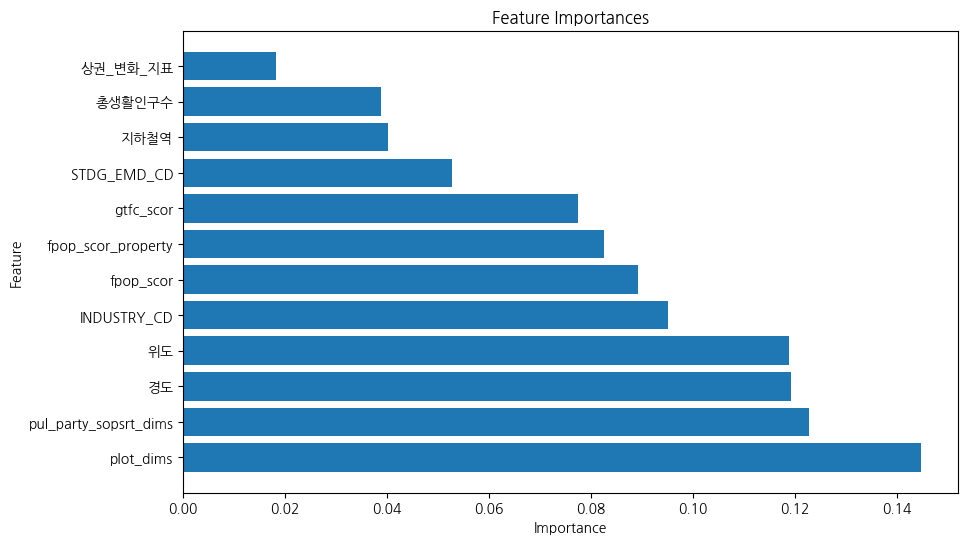

In [11]:
# 변수 중요도 가져오기
importances = xtree.feature_importances_

# 변수 중요도를 내림차순으로 정렬
indices = np.argsort(importances)[::-1]

# 변수 이름 가져오기
feature_names = X_train.columns

# 변수 중요도 출력
print("Feature ranking:")
for f in range(X_train.shape[1]):
    print(f"{f + 1}. feature {indices[f]} ({feature_names[indices[f]]}): {importances[indices[f]]}")

# 변수 중요도를 가로 막대 그래프로 시각화
plt.figure(figsize=(10, 6))
plt.barh(range(X_train.shape[1]), importances[indices], align="center")
plt.yticks(range(X_train.shape[1]), np.array(feature_names)[indices])
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Feature Importances")
plt.show()

In [ ]:
X_train22 = pd.concat([X_train, X_test])
y_train22 = pd.concat([y_train, y_test])

In [ ]:
X_train22.columns

Index(['STDG_EMD_CD', 'INDUSTRY_CD', 'fpop_scor', 'gtfc_scor', 'plot_dims',
       'pul_party_sopsrt_dims', 'fpop_scor_property', '경도', '위도', '지하철역',
       '상권_변화_지표', '총생활인구수'],
      dtype='object')

In [ ]:
X_test2301 = pd.read_csv('/content/drive/MyDrive/2023 빅콘테스트/데이터/23년데이터/test_data/test2301_final.csv')
X_test2302 = pd.read_csv('/content/drive/MyDrive/2023 빅콘테스트/데이터/23년데이터/test_data/test2302_final.csv')

In [ ]:
X_test2302

,STDG_EMD_CD,INDUSTRY_CD,fpop_scor,gtfc_scor,plot_dims,pul_party_sopsrt_dims,fpop_scor_property,경도,위도,지하철역,상권_변화_지표,총생활인구수
0,11680108.0,1.0,-0.452315,0.076491,0.533594,0.492288,-0.260094,0.438407,-0.690825,0.905285,4.0,0.559526
1,11350103.0,5.0,-0.083373,0.237046,1.076128,-1.757975,0.133311,0.966478,1.500176,0.362674,4.0,1.521949
2,11545102.0,2.0,0.391942,-2.173950,-0.258336,0.188888,-0.519184,-1.151077,-1.538872,-1.265159,3.0,0.959115
3,11620102.0,1.0,0.137453,0.176838,-0.083951,-0.203259,0.909845,-0.758687,-1.432862,0.905285,3.0,-0.178871
4,11680110.0,3.0,-1.005353,-0.382873,3.834503,-0.252961,-1.969090,0.408711,-0.373202,-0.722548,4.0,-0.234573
...,...,...,...,...,...,...,...,...,...,...,...,...
9995,11305101.0,3.0,-1.121526,-0.061318,-0.141555,0.823305,0.321206,0.455043,1.391840,-0.722548,4.0,0.006920
9996,11350103.0,13.0,0.102444,0.144727,2.807493,-0.271644,-0.894974,0.954737,1.682615,-0.722548,4.0,1.521949
9997,11500103.0,6.0,0.058009,1.294031,0.001374,-0.030224,-0.192570,-1.778825,-0.293712,-0.722548,4.0,-0.281943
9998,11440127.0,3.0,0.416852,-0.401159,2.115927,-0.768978,0.614057,-1.235104,0.661691,0.905285,4.0,0.979430


In [ ]:
from sklearn.ensemble import ExtraTreesClassifier
from sklearn import metrics
from sklearn.metrics import classification_report
from sklearn.metrics import mean_squared_error

xtree = ExtraTreesClassifier(n_estimators=300, random_state=31,
                                  min_samples_split=8,
                                  max_features= None,
                                  max_depth=50
                             )
xtree.fit(X_train22, y_train22)

y_pred2301 = xtree.predict(X_test2301)
y_pred2302 = xtree.predict(X_test2302)


In [ ]:
X_test2301['SLS_GRD'] = y_pred2301
X_test2302['SLS_GRD'] = y_pred2302

In [ ]:
X_test2301.to_csv('/content/drive/MyDrive/2023 빅콘테스트/데이터/23년데이터/1월예측결과.csv', index=False)
X_test2302.to_csv('/content/drive/MyDrive/2023 빅콘테스트/데이터/23년데이터/2월예측결과.csv', index=False)

In [ ]:
test23 = pd.read_excel('/content/drive/MyDrive/2023 빅콘테스트/소상공인 매출등급 예상 대상 필지.xlsx')

In [ ]:
test23['SLS_GRD_2301'] = y_pred2301
test23['SLS_GRD_2302'] = y_pred2302

In [ ]:
test23

,LT_UNQ_NO,INDUSTRY_CD,STDG_EMD_CD,SLS_GRD_2301,SLS_GRD_2302
0,1168010800102090000,A01,11680108,2.0,2.0
1,1135010300106330015,A05,11350103,3.0,3.0
2,1154510200109830004,A02,11545102,4.0,4.0
3,1162010200100920362,A01,11620102,4.0,4.0
4,1168011000104580000,A03,11680110,4.0,4.0
...,...,...,...,...,...
9995,1130510100100830004,A03,11305101,3.0,4.0
9996,1135010300107450000,A13,11350103,3.0,3.0
9997,1150010300103400017,A06,11500103,4.0,4.0
9998,1144012700116070000,A03,11440127,2.0,3.0


In [ ]:
test23.to_csv('/content/drive/MyDrive/2023 빅콘테스트/소상공인 매출등급 예상 대상 필지.csv', index=False)

# 활용방안
(예상 매출 등급 필지에 대한 분석)

## 기간별

기간별로 매출 등급 예측 결과를 활용하여 2022년 12월 대비 예상 매출 등급이 3등급 이상  상승하거나 하락할 가능성이 있는 곳을 주목하고, 해당 지역의 원인을 분석하고 사전에 해당 가게를 지원하는데 이를 활용할 수 있다.

In [ ]:
# 2022년 매출등급데이터에 추가수집데이터 붙은 형태의 데이터 중 2022년 12월데이터만 불러오기
all_data = pd.read_csv('/content/drive/MyDrive/2023 빅콘테스트/데이터/all_data(null).csv')
all_data=all_data[all_data['DATA_CRTR_YM']==202212].reset_index().drop('index',axis=1)
all_data

,DATA_CRTR_YM,LT_UNQ_NO,STDG_EMD_CD,INDUSTRY_CD,SLS_GRD,pul_party_sopsrt_dims,fpop_scor_property,상권_변화_지표,fpop_scor,gtfc_scor,plot_dims,경도,위도,총생활인구수,지하철역
0,202212,1111010100100030100,11110101,A03,5,0.47,18.21,LH,87.92,47.67,934.011841,126.966923,37.592027,15457.3312,0
1,202212,1111010100100480000,11110101,A01,1,1.38,49.39,LH,63.06,50.04,386.339233,126.969415,37.587042,15457.3312,0
2,202212,1111010100100590001,11110101,A11,3,0.33,21.96,LH,48.81,50.64,6.136597,126.969893,37.586417,15457.3312,0
3,202212,1111010100100590005,11110101,A01,3,0.15,31.58,LH,48.82,50.19,100.975708,126.969359,37.586218,15457.3312,0
4,202212,1111010100100590005,11110101,A03,3,0.15,23.94,LH,90.57,45.26,100.975708,126.969359,37.586218,15457.3312,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
97591,202212,1174011000106950000,11740110,A03,4,0.04,60.07,LL,65.91,NaN,40938.943848,127.180761,37.559969,55528.9932,2
97592,202212,1174011000106950000,11740110,A04,3,0.04,50.85,LL,66.38,NaN,40938.943848,127.180761,37.559969,55528.9932,2
97593,202212,1174011000106990000,11740110,A01,4,0.03,26.61,LL,59.94,NaN,52146.748779,127.178826,37.559850,55528.9932,2
97594,202212,1174011000107070000,11740110,A03,4,0.05,41.32,LL,51.30,NaN,31270.143188,127.171665,37.561180,55528.9932,3


In [ ]:
# 2022년 필지고유번호에 대한 매출등급 데이터
m2022_data = pd.read_csv('/content/drive/MyDrive/2023 빅콘테스트/필지단위 소상공인 매출등급 정보.csv')
m2022_data

,DATA_CRTR_YM,LT_UNQ_NO,STDG_EMD_CD,INDUSTRY_CD,SLS_GRD
0,202201,1111010100100030100,11110101,A03,4
1,202201,1111010100100480000,11110101,A01,2
2,202201,1111010100100590001,11110101,A11,3
3,202201,1111010100100590005,11110101,A03,2
4,202201,1111010100100690000,11110101,A01,2
...,...,...,...,...,...
1156035,202212,1174011000106950000,11740110,A03,4
1156036,202212,1174011000106950000,11740110,A04,3
1156037,202212,1174011000106990000,11740110,A01,4
1156038,202212,1174011000107070000,11740110,A03,4


In [ ]:
#해당 필지에서 2022년 12월 데이터만 뽑기
m2212_data=m2022_data[m2022_data['DATA_CRTR_YM']==202212].reset_index().drop('index',axis=1)
m2212_data

,DATA_CRTR_YM,LT_UNQ_NO,STDG_EMD_CD,INDUSTRY_CD,SLS_GRD
0,202212,1111010100100030100,11110101,A03,5
1,202212,1111010100100480000,11110101,A01,1
2,202212,1111010100100590001,11110101,A11,3
3,202212,1111010100100590005,11110101,A01,3
4,202212,1111010100100590005,11110101,A03,3
...,...,...,...,...,...
97591,202212,1174011000106950000,11740110,A03,4
97592,202212,1174011000106950000,11740110,A04,3
97593,202212,1174011000106990000,11740110,A01,4
97594,202212,1174011000107070000,11740110,A03,4


In [ ]:
#2023년 1,2월 예상 매출등급 필지
m2023_data = pd.read_csv('/content/drive/MyDrive/2023 빅콘테스트/소상공인 매출등급 예상 대상 필지.csv')
m2023_data

,LT_UNQ_NO,INDUSTRY_CD,STDG_EMD_CD,SLS_GRD_2301,SLS_GRD_2302
0,1168010800102090000,A01,11680108,2.0,2.0
1,1135010300106330015,A05,11350103,3.0,3.0
2,1154510200109830004,A02,11545102,4.0,4.0
3,1162010200100920362,A01,11620102,4.0,4.0
4,1168011000104580000,A03,11680110,4.0,4.0
...,...,...,...,...,...
9995,1130510100100830004,A03,11305101,3.0,4.0
9996,1135010300107450000,A13,11350103,3.0,3.0
9997,1150010300103400017,A06,11500103,4.0,4.0
9998,1144012700116070000,A03,11440127,2.0,3.0


In [ ]:
#2023년 1월 과 2월 필지답안지에 2022년 12월달 (필지 번호,업종)키로 잡고 매출등급 붙여주기
month_EDA=m2023_data.merge(m2212_data,how='left',on=['LT_UNQ_NO','INDUSTRY_CD']).drop(['DATA_CRTR_YM','STDG_EMD_CD_y','STDG_EMD_CD_x'],axis=1).rename(columns={'SLS_GRD':'SLS_GRD_2212'})
month_EDA

,LT_UNQ_NO,INDUSTRY_CD,SLS_GRD_2301,SLS_GRD_2302,SLS_GRD_2212
0,1168010800102090000,A01,2.0,2.0,3
1,1135010300106330015,A05,3.0,3.0,2
2,1154510200109830004,A02,4.0,4.0,5
3,1162010200100920362,A01,4.0,4.0,4
4,1168011000104580000,A03,4.0,4.0,4
...,...,...,...,...,...
9995,1130510100100830004,A03,3.0,4.0,4
9996,1135010300107450000,A13,3.0,3.0,5
9997,1150010300103400017,A06,4.0,4.0,4
9998,1144012700116070000,A03,2.0,3.0,2


In [ ]:
#2022년 12월달에 대해 2023년 1,2월 달에 예상 매출등급 증가, 감소 추이 확인
month_EDA['12m-1m']=month_EDA['SLS_GRD_2212']-month_EDA['SLS_GRD_2301']
month_EDA['12m-2m']=month_EDA['SLS_GRD_2212']-month_EDA['SLS_GRD_2302']
month_EDA=month_EDA[['LT_UNQ_NO', 'INDUSTRY_CD','SLS_GRD_2212', 'SLS_GRD_2301', 'SLS_GRD_2302','12m-1m','12m-2m']]
month_EDA

,LT_UNQ_NO,INDUSTRY_CD,SLS_GRD_2212,SLS_GRD_2301,SLS_GRD_2302,12m-1m,12m-2m
0,1168010800102090000,A01,3,2.0,2.0,1.0,1.0
1,1135010300106330015,A05,2,3.0,3.0,-1.0,-1.0
2,1154510200109830004,A02,5,4.0,4.0,1.0,1.0
3,1162010200100920362,A01,4,4.0,4.0,0.0,0.0
4,1168011000104580000,A03,4,4.0,4.0,0.0,0.0
...,...,...,...,...,...,...,...
9995,1130510100100830004,A03,4,3.0,4.0,1.0,0.0
9996,1135010300107450000,A13,5,3.0,3.0,2.0,2.0
9997,1150010300103400017,A06,4,4.0,4.0,0.0,0.0
9998,1144012700116070000,A03,2,2.0,3.0,0.0,-1.0


1월달과 2월달 모두 매출등급이 3등급 이상 좋아진 가게

In [ ]:
#1월달과 2월달 모두 매출등급이 3등급 이상 좋아진 가게
month_EDA_12m_1m_good=month_EDA[month_EDA['12m-1m']>=3.0]
month_EDA_good=month_EDA_12m_1m_good[month_EDA_12m_1m_good['12m-2m']>=3.0]
month_EDA_good

,LT_UNQ_NO,INDUSTRY_CD,SLS_GRD_2212,SLS_GRD_2301,SLS_GRD_2302,12m-1m,12m-2m
140,1168010600109380022,A05,4,1.0,1.0,3.0,3.0
168,1156012100100770009,A13,4,1.0,1.0,3.0,3.0
1836,1114014800100180185,A03,5,1.0,1.0,4.0,4.0
2105,1150010300109270001,A03,5,2.0,2.0,3.0,3.0
2180,1114011700100030004,A01,4,1.0,1.0,3.0,3.0
3074,1168010100106690021,A01,4,1.0,1.0,3.0,3.0
3350,1117013100106840032,A03,5,2.0,2.0,3.0,3.0
3553,1150010300111170007,A03,4,1.0,1.0,3.0,3.0
3691,1171011100100980016,A01,5,2.0,2.0,3.0,3.0
5669,1174010800104280002,A01,4,1.0,1.0,3.0,3.0


In [ ]:
#month_EDA_good에 전체 추가 데이터 붙여주기
month_EDA_good0=month_EDA_good.merge(all_data,how='left',on=['LT_UNQ_NO','INDUSTRY_CD'])
month_EDA_good0_drop=month_EDA_good0.drop(['SLS_GRD_2212',	'SLS_GRD_2301',	'SLS_GRD_2302',	'12m-1m',	'12m-2m',	'DATA_CRTR_YM',	'STDG_EMD_CD','SLS_GRD'],axis=1)
month_EDA_good0_drop

,LT_UNQ_NO,INDUSTRY_CD,pul_party_sopsrt_dims,fpop_scor_property,상권_변화_지표,fpop_scor,gtfc_scor,plot_dims,경도,위도,총생활인구수,지하철역
0,1168010600109380022,A05,0.29,9.88,HH,26.53,51.44,648.171631,127.055169,37.497382,28467.2761,3
1,1156012100100770009,A13,1.78,37.77,LH,22.56,49.32,NaN,127.173502,37.571924,32992.2440,0
2,1114014800100180185,A03,0.02,50.13,HH,62.39,45.73,229.961670,127.008309,37.568320,16903.4105,8
3,1150010300109270001,A03,0.31,51.83,LL,41.64,62.16,599.011719,126.842740,37.528570,14022.4601,1
4,1114011700100030004,A01,0.05,58.08,HH,73.22,NaN,335.253662,126.977630,37.560437,7939.4880,8
5,1168010100106690021,A01,0.09,36.39,LL,41.69,49.26,406.338989,127.037442,37.502842,70045.0460,2
6,1117013100106840032,A03,0.48,33.82,LL,79.02,48.62,115.959473,127.000965,37.535768,25587.6974,2
7,1150010300111170007,A03,0.59,43.49,LL,35.23,59.50,673.232666,126.850757,37.552366,14022.4601,0
8,1171011100100980016,A01,0.13,59.69,HH,61.76,50.15,439.414551,127.110728,37.513081,16851.2513,4
9,1174010800104280002,A01,0.58,67.15,HL,73.92,50.47,3313.689087,127.134715,37.526926,28262.7813,1


In [ ]:
#2023년 1월과 2월 필지데이터에 추가 데이터 붙인 형태의 데이터 불러오기
test01 = pd.read_csv('/content/drive/MyDrive/2023 빅콘테스트/데이터/23년데이터/test2301_all.csv')
test02 = pd.read_csv('/content/drive/MyDrive/2023 빅콘테스트/데이터/23년데이터/test2302_all.csv')

In [ ]:
test01

,LT_UNQ_NO,INDUSTRY_CD,STDG_EMD_CD,pul_party_sopsrt_dims,fpop_scor_property,상권_변화_지표,fpop_scor,gtfc_scor,plot_dims,경도,위도,총생활인구수,지하철역
0,1168010800102090000,A01,11680108,0.29,45.06,LL,49.69,48.52,626.862671,127.033332,37.514452,32573.1357,4
1,1135010300106330015,A05,11350103,NaN,NaN,LL,57.67,56.17,1278.157104,127.077832,37.619347,42524.3160,3
2,1154510200109830004,A02,11545102,0.19,41.53,HL,65.24,36.90,221.578735,126.899389,37.473852,23848.0012,0
3,1162010200100920362,A01,11620102,0.11,61.00,LH,59.62,48.56,278.600098,126.932455,37.478927,20101.7019,4
4,1168011000104580000,A03,11680110,NaN,NaN,LL,NaN,NaN,47830.806519,127.030830,37.529658,26814.6700,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,1130510100100830004,A03,11305101,0.46,52.98,LL,43.01,49.65,258.303101,127.034734,37.614160,36336.7346,1
9996,1135010300107450000,A13,11350103,0.10,36.41,LL,59.92,NaN,12416.398560,127.076842,37.628081,42524.3160,1
9997,1150010300103400017,A06,11500103,0.14,45.98,LL,57.95,58.91,311.632568,126.846490,37.533464,21238.7167,1
9998,1144012700116070000,A03,11440127,0.05,56.97,LL,62.84,46.71,5007.140503,126.892308,37.579204,34756.0016,4


In [ ]:
#2022년 12월 달에 대해 2023년 1월의 예상 매출등급이 3등급이상 좋아진 가게들만 추출후
#12월 추가데이터에서 1월 추가데이터의 추이 변화 살펴보기 위한 merge
month_EDA_good0_drop.merge(test01,how='left',on=['LT_UNQ_NO',	'INDUSTRY_CD']).drop(['위도_y',	'경도_y','위도_x',	'경도_x','STDG_EMD_CD'],axis=1)
#fpop_scor는 12월에 비해 감소하고,gtfc_scor는 증가하는 형태가 많았다. fpop_scor_property가 유지또는 10정도증가,총생활인구수가 눈에 띄게 늘어난 곳

,LT_UNQ_NO,INDUSTRY_CD,pul_party_sopsrt_dims_x,fpop_scor_property_x,상권_변화_지표_x,fpop_scor_x,gtfc_scor_x,plot_dims_x,총생활인구수_x,지하철역_x,pul_party_sopsrt_dims_y,fpop_scor_property_y,상권_변화_지표_y,fpop_scor_y,gtfc_scor_y,plot_dims_y,총생활인구수_y,지하철역_y
0,1168010600109380022,A05,0.29,9.88,HH,26.53,51.44,648.171631,28467.2761,3,0.28,18.00,HH,33.23,47.57,648.171631,33375.2389,3
1,1156012100100770009,A13,1.78,37.77,LH,22.56,49.32,NaN,32992.2440,0,0.87,32.41,LH,21.08,50.45,NaN,32535.1450,2
2,1114014800100180185,A03,0.02,50.13,HH,62.39,45.73,229.961670,16903.4105,8,0.02,50.40,HH,60.89,48.46,229.961670,13558.5477,8
3,1150010300109270001,A03,0.31,51.83,LL,41.64,62.16,599.011719,14022.4601,1,0.19,57.62,LL,48.85,60.47,599.011719,21238.7167,1
4,1114011700100030004,A01,0.05,58.08,HH,73.22,NaN,335.253662,7939.4880,8,0.15,62.34,HH,71.67,NaN,335.253662,9472.4431,8
5,1168010100106690021,A01,0.09,36.39,LL,41.69,49.26,406.338989,70045.0460,2,0.09,49.10,LL,49.49,41.32,406.338989,42673.8511,2
6,1117013100106840032,A03,0.48,33.82,LL,79.02,48.62,115.959473,25587.6974,2,0.48,33.54,LL,78.12,48.03,115.959473,26760.7653,2
7,1150010300111170007,A03,0.59,43.49,LL,35.23,59.50,673.232666,14022.4601,0,0.58,51.75,LL,41.80,58.53,673.232666,21238.7167,0
8,1171011100100980016,A01,0.13,59.69,HH,61.76,50.15,439.414551,16851.2513,4,0.12,61.32,HH,61.52,54.25,439.414551,15441.4802,4
9,1174010800104280002,A01,0.58,67.15,HL,73.92,50.47,3313.689087,28262.7813,1,0.61,71.51,HL,73.42,55.81,3313.689087,24720.1927,1


In [ ]:
#2022년 12월 달에 대해 2023년 2월의 예상 매출등급이 3등급이상 좋아진 가게들만 추출후
#12월 추가데이터에서 2월 추가데이터의 추이 변화 살펴보기 위한 merge
month_EDA_good0_drop.merge(test02,how='left',on=['LT_UNQ_NO',	'INDUSTRY_CD']).drop(['위도_y',	'경도_y','위도_x',	'경도_x','STDG_EMD_CD'],axis=1)
# fpop_scor 유지또는 증가,gtfc_scor 유지또는 감소.

,LT_UNQ_NO,INDUSTRY_CD,pul_party_sopsrt_dims_x,fpop_scor_property_x,상권_변화_지표_x,fpop_scor_x,gtfc_scor_x,plot_dims_x,총생활인구수_x,지하철역_x,pul_party_sopsrt_dims_y,fpop_scor_property_y,상권_변화_지표_y,fpop_scor_y,gtfc_scor_y,plot_dims_y,총생활인구수_y,지하철역_y
0,1168010600109380022,A05,0.29,9.88,HH,26.53,51.44,648.171631,28467.2761,3,0.28,18.00,HH,34.60,49.12,648.171631,18498.7161,3
1,1156012100100770009,A13,1.78,37.77,LH,22.56,49.32,NaN,32992.2440,0,0.87,32.41,LH,21.29,49.81,NaN,32656.7378,2
2,1114014800100180185,A03,0.02,50.13,HH,62.39,45.73,229.961670,16903.4105,8,0.02,50.40,HH,61.79,48.09,229.961670,16334.5025,8
3,1150010300109270001,A03,0.31,51.83,LL,41.64,62.16,599.011719,14022.4601,1,0.19,57.62,LL,50.43,59.06,599.011719,23022.1493,1
4,1114011700100030004,A01,0.05,58.08,HH,73.22,NaN,335.253662,7939.4880,8,0.15,62.34,HH,74.25,NaN,335.253662,8333.8878,8
5,1168010100106690021,A01,0.09,36.39,LL,41.69,49.26,406.338989,70045.0460,2,0.09,49.10,LL,52.67,43.67,406.338989,49395.6342,2
6,1117013100106840032,A03,0.48,33.82,LL,79.02,48.62,115.959473,25587.6974,2,0.48,33.54,LL,79.21,46.81,115.959473,24956.7134,2
7,1150010300111170007,A03,0.59,43.49,LL,35.23,59.50,673.232666,14022.4601,0,0.58,51.75,LL,43.88,59.03,673.232666,23022.1493,0
8,1171011100100980016,A01,0.13,59.69,HH,61.76,50.15,439.414551,16851.2513,4,0.12,61.32,LL,61.87,53.90,439.414551,16376.3349,4
9,1174010800104280002,A01,0.58,67.15,HL,73.92,50.47,3313.689087,28262.7813,1,0.61,71.51,HL,74.14,54.50,3313.689087,28842.9508,1


1월달과 2월달 모두 매출등급이 3등급 이상 나빠진 가게

In [ ]:
#1월달과 2월달 모두 매출등급이 3등급 이상 나빠진 가게
month_EDA_12m_1m_bad=month_EDA[month_EDA['12m-1m']<=-3.0]
month_EDA_bad=month_EDA_12m_1m_bad[month_EDA_12m_1m_bad['12m-2m']<=-3.0]
#month_EDA_bad
month_EDA_bad0=month_EDA_bad.merge(all_data,how='left',on=['LT_UNQ_NO','INDUSTRY_CD'])
month_EDA_bad0

,LT_UNQ_NO,INDUSTRY_CD,SLS_GRD_2212,SLS_GRD_2301,SLS_GRD_2302,12m-1m,12m-2m,DATA_CRTR_YM,STDG_EMD_CD,SLS_GRD,pul_party_sopsrt_dims,fpop_scor_property,상권_변화_지표,fpop_scor,gtfc_scor,plot_dims,경도,위도,총생활인구수,지하철역
0,1150010500107380003,A01,1,5.0,5.0,-4.0,-4.0,202212,11500105,1,1.70,37.77,LL,49.98,NaN,NaN,127.173502,37.571924,34927.2745,0
1,1138010500101910001,A03,2,5.0,5.0,-3.0,-3.0,202212,11380105,2,0.67,10.72,LL,23.59,NaN,14492.775391,126.906816,37.605677,28732.5898,0
2,1144012700116100000,A01,1,4.0,4.0,-3.0,-3.0,202212,11440127,1,0.45,54.06,LL,64.47,49.43,7699.550415,126.892914,37.578454,38296.3382,5
3,1171010800106520005,A01,2,5.0,5.0,-3.0,-3.0,202212,11710108,2,0.16,58.33,LL,65.05,NaN,4716.955811,127.122110,37.482301,49624.9026,2
4,1135010500101400005,A01,1,5.0,5.0,-4.0,-4.0,202212,11350105,1,NaN,57.82,LL,65.63,49.01,121.607178,127.073776,37.664640,19036.6342,2
5,1159010100101240010,A03,2,5.0,5.0,-3.0,-3.0,202212,11590101,2,0.13,63.70,HH,71.69,54.92,218.874268,126.945321,37.511775,16927.9826,3
6,1153010600100600034,A03,2,5.0,5.0,-3.0,-3.0,202212,11530106,2,58.14,18.23,LH,27.52,NaN,NaN,127.173502,37.571924,21103.6140,0
7,1165010800115990002,A06,2,5.0,5.0,-3.0,-3.0,202212,11650108,2,NaN,50.27,HL,57.03,46.53,3385.864624,127.014511,37.486851,32985.3304,3
8,1126010200101080000,A01,1,4.0,4.0,-3.0,-3.0,202212,11260102,1,0.47,59.69,LL,50.33,49.31,503.214722,127.085708,37.594358,25973.0686,4
9,1171010200100110004,A02,1,4.0,4.0,-3.0,-3.0,202212,11710102,1,NaN,57.40,LH,67.37,58.88,9936.220459,127.103577,37.517438,24935.8588,4


In [ ]:
#month_EDA_bad0에 전체 추가 데이터 붙여주기
month_EDA_bad0_drop=month_EDA_bad0.drop(['SLS_GRD_2212',	'SLS_GRD_2301',	'SLS_GRD_2302',	'12m-1m',	'12m-2m',	'DATA_CRTR_YM',	'STDG_EMD_CD','SLS_GRD'],axis=1)
month_EDA_bad0_drop

,LT_UNQ_NO,INDUSTRY_CD,pul_party_sopsrt_dims,fpop_scor_property,상권_변화_지표,fpop_scor,gtfc_scor,plot_dims,경도,위도,총생활인구수,지하철역
0,1150010500107380003,A01,1.70,37.77,LL,49.98,NaN,NaN,127.173502,37.571924,34927.2745,0
1,1138010500101910001,A03,0.67,10.72,LL,23.59,NaN,14492.775391,126.906816,37.605677,28732.5898,0
2,1144012700116100000,A01,0.45,54.06,LL,64.47,49.43,7699.550415,126.892914,37.578454,38296.3382,5
3,1171010800106520005,A01,0.16,58.33,LL,65.05,NaN,4716.955811,127.122110,37.482301,49624.9026,2
4,1135010500101400005,A01,NaN,57.82,LL,65.63,49.01,121.607178,127.073776,37.664640,19036.6342,2
5,1159010100101240010,A03,0.13,63.70,HH,71.69,54.92,218.874268,126.945321,37.511775,16927.9826,3
6,1153010600100600034,A03,58.14,18.23,LH,27.52,NaN,NaN,127.173502,37.571924,21103.6140,0
7,1165010800115990002,A06,NaN,50.27,HL,57.03,46.53,3385.864624,127.014511,37.486851,32985.3304,3
8,1126010200101080000,A01,0.47,59.69,LL,50.33,49.31,503.214722,127.085708,37.594358,25973.0686,4
9,1171010200100110004,A02,NaN,57.40,LH,67.37,58.88,9936.220459,127.103577,37.517438,24935.8588,4


In [ ]:
month_EDA_bad0_drop.merge(test01,how='left',on=['LT_UNQ_NO',	'INDUSTRY_CD']).drop(['위도_y',	'경도_y','위도_x',	'경도_x','STDG_EMD_CD'],axis=1)
#fpop_scor는 12월에 비해 대부분 유지또는 감소하고,gtfc_scor는 감소하는 형태가 많았다. pul_party_sopsrt_dims 감소

,LT_UNQ_NO,INDUSTRY_CD,pul_party_sopsrt_dims_x,fpop_scor_property_x,상권_변화_지표_x,fpop_scor_x,gtfc_scor_x,plot_dims_x,총생활인구수_x,지하철역_x,pul_party_sopsrt_dims_y,fpop_scor_property_y,상권_변화_지표_y,fpop_scor_y,gtfc_scor_y,plot_dims_y,총생활인구수_y,지하철역_y
0,1150010500107380003,A01,1.70,37.77,LL,49.98,NaN,NaN,34927.2745,0,1.47,51.48,LL,57.83,NaN,NaN,34466.1159,3
1,1138010500101910001,A03,0.67,10.72,LL,23.59,NaN,14492.775391,28732.5898,0,NaN,NaN,LL,23.15,NaN,14492.775391,27550.5062,0
2,1144012700116100000,A01,0.45,54.06,LL,64.47,49.43,7699.550415,38296.3382,5,0.42,52.93,LL,64.12,43.98,7699.550415,34756.0016,5
3,1171010800106520005,A01,0.16,58.33,LL,65.05,NaN,4716.955811,49624.9026,2,0.12,55.85,LL,61.09,NaN,4716.955811,28168.7281,2
4,1135010500101400005,A01,NaN,57.82,LL,65.63,49.01,121.607178,19036.6342,2,NaN,59.18,LL,65.30,39.81,121.607178,39746.7920,2
5,1159010100101240010,A03,0.13,63.70,HH,71.69,54.92,218.874268,16927.9826,3,0.13,60.13,HH,70.07,53.05,218.874268,15141.3978,3
6,1153010600100600034,A03,58.14,18.23,LH,27.52,NaN,NaN,21103.6140,0,54.51,20.67,HL,25.88,NaN,NaN,18737.0548,0
7,1165010800115990002,A06,NaN,50.27,HL,57.03,46.53,3385.864624,32985.3304,3,NaN,47.92,HH,55.26,32.79,3385.864624,28302.4242,3
8,1126010200101080000,A01,0.47,59.69,LL,50.33,49.31,503.214722,25973.0686,4,0.47,65.83,LL,49.56,42.56,503.214722,26101.0502,4
9,1171010200100110004,A02,NaN,57.40,LH,67.37,58.88,9936.220459,24935.8588,4,NaN,44.26,LL,66.65,41.90,9936.220459,23885.4400,4


In [ ]:
month_EDA_bad0_drop.merge(test02,how='left',on=['LT_UNQ_NO',	'INDUSTRY_CD']).drop(['위도_y',	'경도_y','위도_x',	'경도_x','STDG_EMD_CD'],axis=1)
# gtfc_scor는 감소하는 형태가 많았다

,LT_UNQ_NO,INDUSTRY_CD,pul_party_sopsrt_dims_x,fpop_scor_property_x,상권_변화_지표_x,fpop_scor_x,gtfc_scor_x,plot_dims_x,총생활인구수_x,지하철역_x,pul_party_sopsrt_dims_y,fpop_scor_property_y,상권_변화_지표_y,fpop_scor_y,gtfc_scor_y,plot_dims_y,총생활인구수_y,지하철역_y
0,1150010500107380003,A01,1.70,37.77,LL,49.98,NaN,NaN,34927.2745,0,1.47,51.48,LL,59.91,NaN,NaN,36396.7670,3
1,1138010500101910001,A03,0.67,10.72,LL,23.59,NaN,14492.775391,28732.5898,0,NaN,NaN,LL,26.03,NaN,14492.775391,29394.2296,0
2,1144012700116100000,A01,0.45,54.06,LL,64.47,49.43,7699.550415,38296.3382,5,0.42,52.93,LL,66.44,43.34,7699.550415,38173.6272,5
3,1171010800106520005,A01,0.16,58.33,LL,65.05,NaN,4716.955811,49624.9026,2,0.12,55.85,LL,61.66,NaN,4716.955811,35493.7863,2
4,1135010500101400005,A01,NaN,57.82,LL,65.63,49.01,121.607178,19036.6342,2,NaN,59.18,LL,65.37,42.55,121.607178,40558.1082,2
5,1159010100101240010,A03,0.13,63.70,HH,71.69,54.92,218.874268,16927.9826,3,0.13,60.13,HH,70.40,53.16,218.874268,16327.5584,3
6,1153010600100600034,A03,58.14,18.23,LH,27.52,NaN,NaN,21103.6140,0,54.51,20.67,HH,26.06,NaN,NaN,21422.6934,0
7,1165010800115990002,A06,NaN,50.27,HL,57.03,46.53,3385.864624,32985.3304,3,NaN,47.92,HH,54.07,31.32,3385.864624,28320.2178,3
8,1126010200101080000,A01,0.47,59.69,LL,50.33,49.31,503.214722,25973.0686,4,0.47,65.83,LL,51.55,44.58,503.214722,26366.0458,4
9,1171010200100110004,A02,NaN,57.40,LH,67.37,58.88,9936.220459,24935.8588,4,NaN,44.26,LL,67.67,43.74,9936.220459,25069.8988,4


## 업종별

In [ ]:
test23 = pd.read_csv('/content/drive/MyDrive/2023 빅콘테스트/소상공인 매출등급 예상 대상 필지.csv')

In [ ]:
to_name = {'A01':'한식', 'A02':'치킨', 'A03':'기타 외식', 'A04':'제과제빵', 'A05':'패스트푸드', 'A06':'분식', 'A07':'피자',
           'A08':'커피', 'A09':'아이스크림/빙수', 'A10': '기타 외국식', 'A11':'중식', 'A12':'주점', 'A13':'일식', 'A14':'서양식',
           'A15':'음료(커피 외)'}

test23['업종명'] = test23['INDUSTRY_CD'].map(to_name)

In [ ]:
train22 = pd.read_csv('/content/drive/MyDrive/2023 빅콘테스트/필지단위 소상공인 매출등급 정보.csv')

In [ ]:
year = [202201, 202202, 202203, 202204, 202205, 202206, 202207, 202208, 202209, 202210, 202211, 202212]

# 모든연도 업종별 매출등급별 개수

for i in year:
  temp = train22[train22['DATA_CRTR_YM']==i]
  temp.drop('DATA_CRTR_YM', axis=1, inplace=True)
  test23 = pd.merge(test23, temp, how='left', on = ['LT_UNQ_NO', 'STDG_EMD_CD', 'INDUSTRY_CD'])
  new_column_name = 'SLS_GRD_' + str(i)[2:]
  test23.rename(columns={'SLS_GRD': new_column_name}, inplace=True)

In [ ]:
a_sum = test23['업종명'].value_counts().reset_index().rename(columns={'index':'업종명', '업종명':'합계'})
a_sum

,업종명,합계
0,한식,3638
1,기타 외식,2776
2,커피,495
3,일식,493
4,중식,443
5,분식,430
6,서양식,405
7,치킨,401
8,제과제빵,337
9,패스트푸드,192


In [ ]:
b = test23.groupby(['업종명', 'SLS_GRD_2201'])['LT_UNQ_NO'].count().reset_index()
percen = pd.merge(b, a_sum, how='left', on='업종명')
percen['2201'] = (percen['LT_UNQ_NO'] / percen['합계']) * 100
percen

col_names = ['SLS_GRD_2202', 'SLS_GRD_2203','SLS_GRD_2204', 'SLS_GRD_2205', 'SLS_GRD_2206', 'SLS_GRD_2207',
             'SLS_GRD_2208', 'SLS_GRD_2209', 'SLS_GRD_2210', 'SLS_GRD_2211','SLS_GRD_2212', 'SLS_GRD_2301', 'SLS_GRD_2302']

for i in col_names:
  b = test23.groupby(['업종명', i])['LT_UNQ_NO'].count().reset_index()
  temp = pd.merge(b, a_sum, how='left', on='업종명')
  new_col_name = i[-4:]
  percen[new_col_name] = (temp['LT_UNQ_NO'] / temp['합계']) * 100

percen

,업종명,SLS_GRD_2201,LT_UNQ_NO,합계,2201,2202,2203,2204,2205,2206,2207,2208,2209,2210,2211,2212,2301,2302
0,기타 외국식,1,6,41,14.634146,14.634146,12.195122,9.756098,9.756098,12.195122,9.756098,12.195122,9.756098,12.195122,7.317073,12.195122,9.756098,12.195122
1,기타 외국식,2,16,41,39.024390,26.829268,36.585366,36.585366,36.585366,34.146341,34.146341,34.146341,34.146341,26.829268,36.585366,34.146341,34.146341,31.707317
2,기타 외국식,3,9,41,21.951220,41.463415,29.268293,34.146341,29.268293,31.707317,34.146341,34.146341,31.707317,41.463415,29.268293,29.268293,31.707317,26.829268
3,기타 외국식,4,8,41,19.512195,12.195122,12.195122,12.195122,19.512195,12.195122,17.073171,12.195122,17.073171,14.634146,19.512195,14.634146,19.512195,21.951220
4,기타 외국식,5,2,41,4.878049,4.878049,9.756098,7.317073,4.878049,9.756098,4.878049,7.317073,7.317073,4.878049,7.317073,9.756098,4.878049,7.317073
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
70,한식,1,456,3638,12.534360,11.957119,12.671798,12.204508,12.341946,12.286971,12.286971,12.396921,11.737218,12.204508,12.809236,12.561847,11.792194,11.489830
71,한식,2,994,3638,27.322705,28.229797,27.707532,28.009896,27.240242,27.735019,27.927433,27.652556,27.075316,27.570093,27.377680,26.992853,27.982408,28.532161
72,한식,3,1096,3638,30.126443,29.494228,29.796592,30.868609,30.813634,30.593733,30.428807,29.659153,30.868609,29.576690,29.439252,30.318857,30.648708,31.445849
73,한식,4,845,3638,23.227048,23.529412,23.584387,22.979659,23.144585,23.584387,23.007147,23.941726,24.161627,24.518966,23.996701,23.666850,24.711380,23.721825


In [ ]:
tdf1 = percen[percen['SLS_GRD_2201']==1].drop(['SLS_GRD_2201', 'LT_UNQ_NO', '합계'], axis=1)
tdf1 = tdf1.set_index('업종명', drop=True)
tdf1

,2201,2202,2203,2204,2205,2206,2207,2208,2209,2210,2211,2212,2301,2302
업종명,,,,,,,,,,,,,,
기타 외국식,14.634146,14.634146,12.195122,9.756098,9.756098,12.195122,9.756098,12.195122,9.756098,12.195122,7.317073,12.195122,9.756098,12.195122
기타 외식,11.131124,11.995677,11.167147,11.707493,11.707493,11.419308,11.707493,11.095101,11.815562,11.275216,11.167147,10.374640,10.554755,10.518732
분식,10.697674,11.395349,12.790698,12.093023,11.860465,12.093023,11.627907,12.558140,11.627907,12.093023,12.558140,12.558140,12.325581,11.860465
서양식,12.098765,11.851852,12.345679,12.345679,12.098765,12.592593,12.592593,12.592593,13.333333,12.592593,11.358025,11.851852,12.592593,11.358025
아이스크림/빙수,11.904762,11.904762,11.904762,11.904762,11.904762,7.142857,9.523810,9.523810,11.904762,11.904762,11.904762,11.904762,7.142857,9.523810
음료(커피 외),8.333333,8.333333,8.333333,5.555556,8.333333,8.333333,8.333333,11.111111,8.333333,8.333333,8.333333,13.888889,5.555556,8.333333
일식,11.764706,11.561866,12.373225,11.561866,13.184584,11.359026,10.953347,11.561866,12.170385,11.561866,12.170385,11.967546,10.344828,10.547667
제과제빵,14.836795,14.243323,13.353116,12.166172,12.759644,12.759644,11.572700,12.759644,12.166172,11.275964,11.869436,12.166172,11.572700,11.869436
주점,9.677419,6.451613,10.483871,8.064516,11.290323,12.903226,15.322581,16.935484,12.903226,12.096774,10.483871,12.096774,10.483871,8.870968


In [ ]:
tdf1['22년 1월 대비 23년 1월'] = ((tdf1['2301'] - tdf1['2201']) / tdf1['2201']) *100
tdf1['22년 2월 대비 23년 2월'] = ((tdf1['2302'] - tdf1['2202']) / tdf1['2202']) *100
tdf1['22년 12월 대비 23년 1월'] = ((tdf1['2301'] - tdf1['2212']) / tdf1['2212']) *100
tdf1['22년 12월 대비 23년 2월'] = ((tdf1['2302'] - tdf1['2212']) / tdf1['2212']) *100

Text(0.5, 1.0, '22년 1월 대비 23년 1월 매출등급 1등급 증감률')

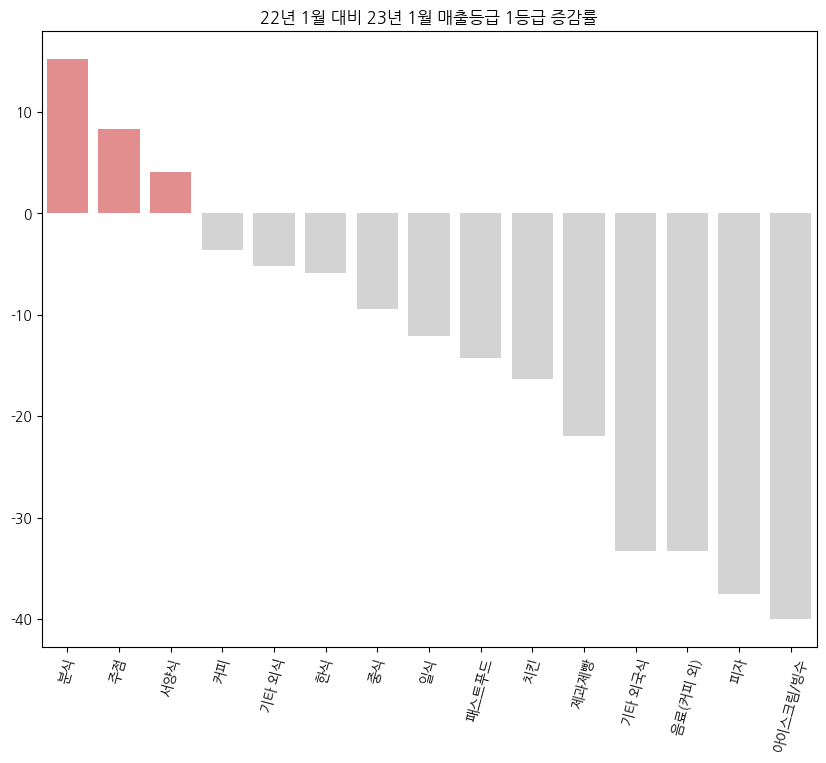

In [ ]:
tdf1.sort_values('22년 1월 대비 23년 1월', ascending=False,inplace=True)
values = np.array(tdf1['22년 1월 대비 23년 1월'])
idx = np.array(tdf1.index)
plt.figure(figsize=(10,8))
palette = ['lightcoral' if (x >0) else 'lightgrey' for x in values]
sns.barplot(x=idx, y=values, palette=palette)
plt.xticks(rotation=75)
plt.title('22년 1월 대비 23년 1월 매출등급 1등급 증감률')

Text(0.5, 1.0, '22년 2월 대비 23년 2월 매출등급 1등급 증감률')

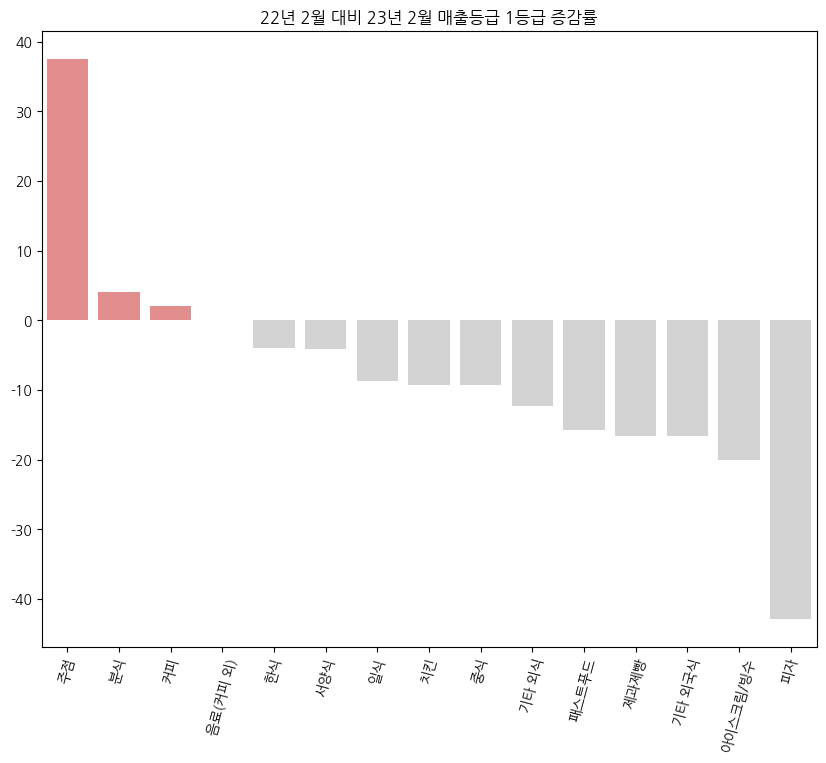

In [ ]:
tdf1.sort_values('22년 2월 대비 23년 2월', ascending=False,inplace=True)
values = np.array(tdf1['22년 2월 대비 23년 2월'])
idx = np.array(tdf1.index)
plt.figure(figsize=(10,8))
palette = ['lightcoral' if (x >0) else 'lightgrey' for x in values]
sns.barplot(x=idx, y=values, palette=palette)
plt.xticks(rotation=75)
plt.title('22년 2월 대비 23년 2월 매출등급 1등급 증감률')

In [ ]:
tdf2 = percen[percen['SLS_GRD_2201']==5].drop(['SLS_GRD_2201', 'LT_UNQ_NO', '합계'], axis=1)
tdf2 = tdf2.set_index('업종명', drop=True)
tdf2

,2201,2202,2203,2204,2205,2206,2207,2208,2209,2210,2211,2212,2301,2302
업종명,,,,,,,,,,,,,,
기타 외국식,4.878049,4.878049,9.756098,7.317073,4.878049,9.756098,4.878049,7.317073,7.317073,4.878049,7.317073,9.756098,4.878049,7.317073
기타 외식,6.628242,6.628242,5.907781,5.547550,5.295389,5.619597,5.223343,6.159942,6.376081,6.412104,6.051873,6.340058,4.178674,3.998559
분식,5.581395,6.511628,4.651163,4.883721,5.813953,4.883721,4.883721,5.348837,5.581395,6.744186,7.674419,5.813953,5.813953,6.046512
서양식,4.691358,6.172840,4.444444,4.197531,2.716049,3.950617,3.950617,3.950617,4.197531,4.691358,3.950617,4.197531,2.962963,3.456790
아이스크림/빙수,4.761905,9.523810,4.761905,7.142857,2.380952,2.380952,2.380952,2.380952,4.761905,4.761905,4.761905,4.761905,7.142857,7.142857
음료(커피 외),11.111111,8.333333,5.555556,8.333333,5.555556,5.555556,5.555556,8.333333,8.333333,11.111111,13.888889,16.666667,8.333333,8.333333
일식,5.679513,6.085193,5.070994,4.868154,5.273834,4.868154,5.679513,5.070994,5.882353,4.462475,4.665314,5.476673,3.651116,3.245436
제과제빵,5.341246,5.934718,5.934718,5.637982,5.341246,5.044510,5.934718,5.637982,4.154303,5.341246,5.044510,5.637982,4.451039,4.154303
주점,7.258065,8.870968,6.451613,3.225806,2.419355,4.032258,1.612903,4.838710,4.838710,2.419355,7.258065,5.645161,4.032258,4.032258


In [ ]:
tdf2['22년 1월 대비 23년 1월'] = ((tdf2['2301'] - tdf2['2201']) / tdf2['2201']) *100
tdf2['22년 2월 대비 23년 2월'] = ((tdf2['2302'] - tdf2['2202']) / tdf2['2202']) *100
tdf2['22년 12월 대비 23년 1월'] = ((tdf2['2301'] - tdf2['2212']) / tdf2['2212']) *100
tdf2['22년 12월 대비 23년 2월'] = ((tdf2['2302'] - tdf2['2212']) / tdf2['2212']) *100

Text(0.5, 1.0, '22년 1월 대비 23년 1월 매출등급 5등급 증감률')

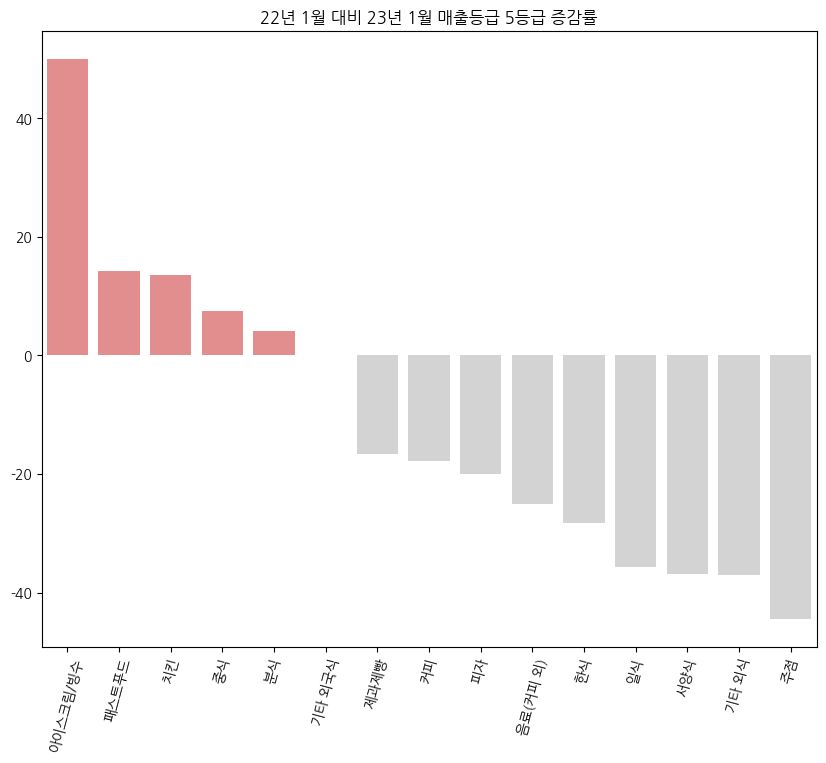

In [ ]:
tdf2.sort_values('22년 1월 대비 23년 1월', ascending=False,inplace=True)
values = np.array(tdf2['22년 1월 대비 23년 1월'])
idx = np.array(tdf2.index)
plt.figure(figsize=(10,8))
palette = ['lightcoral' if (x >0) else 'lightgrey' for x in values]
sns.barplot(x=idx, y=values, palette=palette)
plt.xticks(rotation=75)
plt.title('22년 1월 대비 23년 1월 매출등급 5등급 증감률')

Text(0.5, 1.0, '22년 2월 대비 23년 2월 매출등급 5등급 증감률')

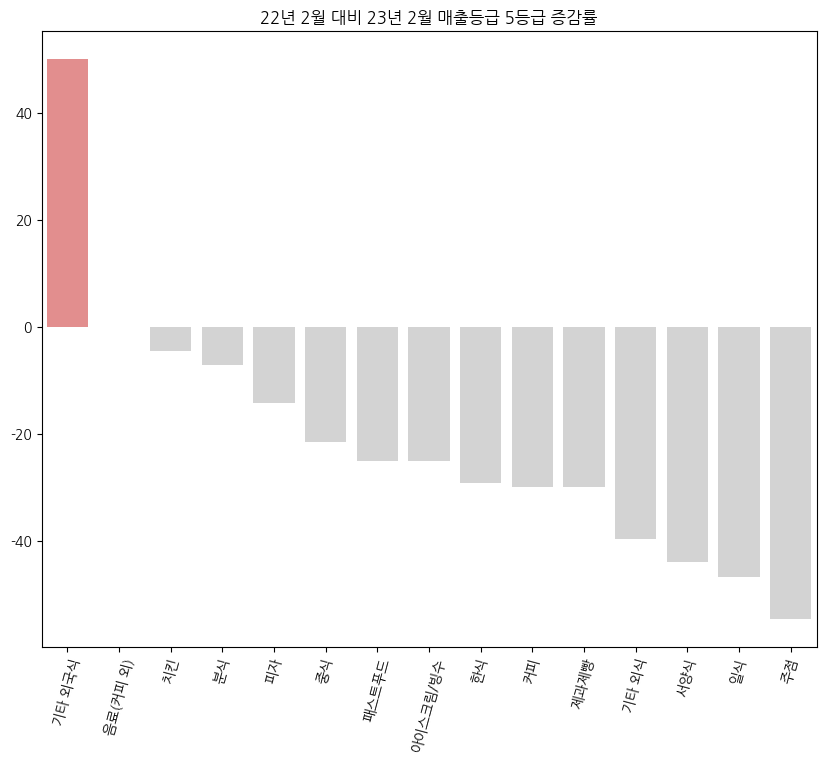

In [ ]:
tdf2.sort_values('22년 2월 대비 23년 2월', ascending=False,inplace=True)
values = np.array(tdf2['22년 2월 대비 23년 2월'])
idx = np.array(tdf2.index)
plt.figure(figsize=(10,8))
palette = ['lightcoral' if (x >0) else 'lightgrey' for x in values]
sns.barplot(x=idx, y=values, palette=palette)
plt.xticks(rotation=75)
plt.title('22년 2월 대비 23년 2월 매출등급 5등급 증감률')

## 지역별

In [ ]:
# train 데이터 불러오기
df = pd.read_csv("/content/gdrive/MyDrive/빅콘테스트/데이터/all_data(null)+구동.csv")

In [ ]:
# 2023 1월 예측 데이터
df1 = pd.read_csv("/content/gdrive/MyDrive/빅콘테스트/데이터/2023예측/1월예측결과.csv")

In [ ]:
# 2023 2월 예측 데이터
df2 = pd.read_csv("/content/gdrive/MyDrive/빅콘테스트/데이터/2023예측/2월예측결과.csv")

- 2023 데이터 구, 동 붙여주기

* 법정동 코드에서 구, 동 추출

In [ ]:
dong = pd.read_excel('/content/gdrive/MyDrive/빅콘테스트/데이터/2023빅콘테스트_빅데이터플랫폼활용분야_지정주제(부동산)_데이터셋/2023빅콘테스트_빅데이터플랫폼_지정주제(부동산)_데이터정의서.xlsx', sheet_name='서울시 법정동코드')
dong

,법정동코드,법정동명
0,11110101,서울특별시 종로구 청운동
1,11110102,서울특별시 종로구 신교동
2,11110103,서울특별시 종로구 궁정동
3,11110104,서울특별시 종로구 효자동
4,11110105,서울특별시 종로구 창성동
...,...,...
462,11740106,서울특별시 강동구 둔촌동
463,11740107,서울특별시 강동구 암사동
464,11740108,서울특별시 강동구 성내동
465,11740109,서울특별시 강동구 천호동


In [ ]:
dong.rename(columns = {'법정동코드':'STDG_EMD_CD'}, inplace=True)

In [ ]:
all_data_dong1 = pd.merge(df1, dong, how='left', on='STDG_EMD_CD')
all_data_dong2 = pd.merge(df2, dong, how='left', on='STDG_EMD_CD')

In [ ]:
# 구와 동 분리
all_data_dong1['구'] = all_data_dong1['법정동명'].str.split(' ').str[1]
all_data_dong1['동'] = all_data_dong1['법정동명'].str.split(' ').str[2]

all_data_dong2['구'] = all_data_dong2['법정동명'].str.split(' ').str[1]
all_data_dong2['동'] = all_data_dong2['법정동명'].str.split(' ').str[2]

In [ ]:
all_data_dong1.drop('법정동명', axis=1, inplace=True)
all_data_dong2.drop('법정동명', axis=1, inplace=True)

In [ ]:
df1 = all_data_dong1
df2 = all_data_dong2

- 구별

- 22년 1월, 23년 1월 비교하기

- 22년 1월

In [ ]:
df2201 = df[df['DATA_CRTR_YM']==202201]

In [ ]:
gm = df2201.groupby('구').mean()
gm = gm[['SLS_GRD', 'pul_party_sopsrt_dims', 'fpop_scor_property', 'fpop_scor',	'gtfc_scor',	'plot_dims', '총생활인구수',	'지하철역']]
gm = gm.reset_index()
gm

<ipython-input-8-eb8f44684599>:1: FutureWarning: The default value of numeric_only in DataFrameGroupBy.mean is deprecated. In a future version, numeric_only will default to False. Either specify numeric_only or select only columns which should be valid for the function.
  gm = df2201.groupby('구').mean()


,구,SLS_GRD,pul_party_sopsrt_dims,fpop_scor_property,fpop_scor,gtfc_scor,plot_dims,총생활인구수,지하철역
0,강남구,2.349535,1.954030,43.814861,48.206519,48.669109,1921.670910,37404.993244,2.559082
1,강동구,3.214576,0.735331,52.013602,62.032008,47.618359,2555.559142,29194.211175,1.739095
2,강북구,3.413529,1.263362,55.180331,55.747823,48.911793,971.280945,23090.230659,1.775453
3,강서구,3.083234,0.383823,50.696456,60.672155,47.727664,2107.761248,29513.808910,1.555767
4,관악구,3.226856,0.498419,54.289129,56.338626,47.658279,784.710361,18943.340247,1.785439
5,광진구,3.149596,0.881189,51.866112,59.122041,48.556033,1024.097617,23447.586517,1.745822
6,구로구,3.294331,1.301659,52.195962,63.826475,47.917086,2141.133763,25358.120845,1.211931
7,금천구,3.237835,0.299446,50.745655,61.108361,47.462130,1711.781764,25688.969681,0.382447
8,노원구,3.186376,3.944904,54.749915,62.104009,48.260846,4613.796048,29055.432843,1.602006
9,도봉구,3.341766,1.125015,57.943089,59.738316,48.107376,1641.100286,17412.549559,1.017019


In [ ]:
import os
import requests
import json
import seaborn as sns

# 서울 행정구역 json raw파일(githubcontent)
r = requests.get('https://raw.githubusercontent.com/southkorea/seoul-maps/master/kostat/2013/json/seoul_municipalities_geo_simple.json')
c = r.content
seoul_geo = json.loads(c)

In [ ]:
!pip install folium
import folium

m = folium.Map(
    location=[37.566535, 126.9779692],
    zoom_start=11.2,
    tiles='cartodbpositron'
)

folium.Choropleth(
    geo_data=seoul_geo, # 경계선 좌표값이 담긴 데이터
    data=gm, # Series or DataFrame 넣으면 된다
    columns=['구', 'SLS_GRD'], # DataFrame의 어떤 columns을 넣을지
    key_on='properties.name',
    fill_color='YlOrRd',
    fill_opacity=0.5, # 색 투명도
    line_opacity=0.2, # 선 투명도
    legend_name='SLS_GRD' # 범례
).add_to(m)

m

- 23년 1월

In [ ]:
gm1 = df1.groupby('구').mean()
gm1 = gm1[['SLS_GRD', 'pul_party_sopsrt_dims', 'fpop_scor_property', 'fpop_scor',	'gtfc_scor',	'plot_dims', '총생활인구수',	'지하철역']]
gm1 = gm1.reset_index()
gm1

<ipython-input-19-362e34efb832>:1: FutureWarning: The default value of numeric_only in DataFrameGroupBy.mean is deprecated. In a future version, numeric_only will default to False. Either specify numeric_only or select only columns which should be valid for the function.
  gm1 = df1.groupby('구').mean()


,구,SLS_GRD,pul_party_sopsrt_dims,fpop_scor_property,fpop_scor,gtfc_scor,plot_dims,총생활인구수,지하철역
0,강남구,2.140251,0.077500,-0.449198,-0.771132,0.179890,0.295783,0.587543,0.180154
1,강동구,3.036269,0.037807,0.563531,0.137506,0.000334,0.112887,0.081683,-0.338784
2,강북구,3.184848,0.157031,0.094434,-0.120993,0.085673,-0.150746,0.362646,-0.324633
3,강서구,2.962353,-0.050399,-0.043585,-0.084838,-0.050028,0.427225,-0.258086,-0.389321
4,관악구,3.035629,-0.168523,0.499933,-0.355005,0.053302,-0.143329,-0.326144,-0.335889
5,광진구,2.989822,0.008821,-0.016584,-0.068123,0.026201,0.025526,0.028607,-0.302818
6,구로구,3.135314,0.094100,0.893074,0.384767,-0.047206,0.114792,0.456481,-0.507652
7,금천구,3.295455,-0.082860,0.239611,0.125221,-0.160073,0.200584,0.039546,-0.892730
8,노원구,3.035587,0.213605,0.710777,0.278464,-0.045867,0.514646,0.788825,-0.376899
9,도봉구,3.257028,0.417310,0.761171,0.107941,-0.140175,0.064488,-0.176047,-0.707294


In [ ]:
import os
import requests
import json
import seaborn as sns

# 서울 행정구역 json raw파일(githubcontent)
r = requests.get('https://raw.githubusercontent.com/southkorea/seoul-maps/master/kostat/2013/json/seoul_municipalities_geo_simple.json')
c = r.content
seoul_geo = json.loads(c)

In [ ]:
!pip install folium
import folium

m = folium.Map(
    location=[37.566535, 126.9779692],
    zoom_start=11.2,
    tiles='cartodbpositron'
)

folium.Choropleth(
    geo_data=seoul_geo, # 경계선 좌표값이 담긴 데이터
    data=gm1, # Series or DataFrame 넣으면 된다
    columns=['구', 'SLS_GRD'], # DataFrame의 어떤 columns을 넣을지
    key_on='properties.name',
    fill_color='YlOrRd',
    fill_opacity=0.5, # 색 투명도
    line_opacity=0.2, # 선 투명도
    legend_name='SLS_GRD' # 범례
).add_to(m)

m

- 22년 2월, 23년 2월 비교하기

- 22년 2월

In [ ]:
df2202 = df[df['DATA_CRTR_YM']==202202]

In [ ]:
gm2202 = df2202.groupby('구').mean()
gm2202 = gm2202[['SLS_GRD', 'pul_party_sopsrt_dims', 'fpop_scor_property', 'fpop_scor',	'gtfc_scor',	'plot_dims', '총생활인구수',	'지하철역']]
gm2202 = gm2202.reset_index()
gm2202

<ipython-input-23-4276b599378d>:1: FutureWarning: The default value of numeric_only in DataFrameGroupBy.mean is deprecated. In a future version, numeric_only will default to False. Either specify numeric_only or select only columns which should be valid for the function.
  gm2202 = df2202.groupby('구').mean()


,구,SLS_GRD,pul_party_sopsrt_dims,fpop_scor_property,fpop_scor,gtfc_scor,plot_dims,총생활인구수,지하철역
0,강남구,2.351942,1.944402,43.801954,47.733367,48.879374,1915.032154,27489.888787,2.556763
1,강동구,3.211172,0.722929,52.015985,62.531926,48.039256,2532.235200,31643.978292,1.734605
2,강북구,3.403317,1.264635,55.153956,56.917011,49.331591,973.349240,26759.118244,1.782639
3,강서구,3.076628,0.382493,50.726910,60.925159,47.993467,2121.051230,23640.723190,1.556274
4,관악구,3.203803,0.498021,54.229699,56.567206,47.615725,753.541669,21391.942430,1.785958
5,광진구,3.137801,0.875577,51.895149,59.575911,49.003836,1017.192213,20794.785053,1.744934
6,구로구,3.299699,1.240809,52.097081,63.704179,48.219873,2170.601744,22428.564740,1.205145
7,금천구,3.281864,0.295440,50.801917,60.726232,47.433383,1665.526573,22750.091319,0.383280
8,노원구,3.178904,3.883547,54.749557,62.746563,48.544406,4632.467501,21389.899585,1.601172
9,도봉구,3.330869,1.118361,57.919438,60.574507,48.144783,1649.134511,20006.740195,1.013863


In [ ]:
import os
import requests
import json
import seaborn as sns

# 서울 행정구역 json raw파일(githubcontent)
r = requests.get('https://raw.githubusercontent.com/southkorea/seoul-maps/master/kostat/2013/json/seoul_municipalities_geo_simple.json')
c = r.content
seoul_geo = json.loads(c)

In [ ]:
!pip install folium
import folium

m = folium.Map(
    location=[37.566535, 126.9779692],
    zoom_start=11.2,
    tiles='cartodbpositron'
)

folium.Choropleth(
    geo_data=seoul_geo, # 경계선 좌표값이 담긴 데이터
    data=gm2202, # Series or DataFrame 넣으면 된다
    columns=['구', 'SLS_GRD'], # DataFrame의 어떤 columns을 넣을지
    key_on='properties.name',
    fill_color='YlOrRd',
    fill_opacity=0.5, # 색 투명도
    line_opacity=0.2, # 선 투명도
    legend_name='SLS_GRD' # 범례
).add_to(m)

m

- 23년 2월

In [ ]:
gm2 = df2.groupby('구').mean()
gm2 = gm2[['SLS_GRD', 'pul_party_sopsrt_dims', 'fpop_scor_property', 'fpop_scor',	'gtfc_scor',	'plot_dims', '총생활인구수',	'지하철역']]
gm2 = gm2.reset_index()
gm2

<ipython-input-26-2d91d5cb7cd4>:1: FutureWarning: The default value of numeric_only in DataFrameGroupBy.mean is deprecated. In a future version, numeric_only will default to False. Either specify numeric_only or select only columns which should be valid for the function.
  gm2 = df2.groupby('구').mean()


,구,SLS_GRD,pul_party_sopsrt_dims,fpop_scor_property,fpop_scor,gtfc_scor,plot_dims,총생활인구수,지하철역
0,강남구,2.164196,0.079331,-0.447045,-0.639941,0.184492,0.294268,0.670152,0.180154
1,강동구,3.054404,0.051332,0.565828,0.183272,-0.030164,0.114064,0.497460,-0.338784
2,강북구,3.178788,0.142204,0.085562,-0.093194,0.034161,-0.150746,-0.397703,-0.324633
3,강서구,2.988235,-0.037864,-0.036821,0.006931,-0.059855,0.432349,0.193277,-0.389321
4,관악구,3.019002,-0.171923,0.514687,-0.253055,0.028503,-0.143300,-0.478737,-0.335889
5,광진구,2.987277,0.001929,-0.009740,-0.029074,-0.042111,0.025756,-0.088168,-0.302818
6,구로구,3.161716,0.085990,0.888025,0.415762,-0.032900,0.134802,0.373551,-0.507652
7,금천구,3.281818,-0.071559,0.243788,0.165301,-0.146871,0.200402,0.378329,-0.892730
8,노원구,3.032028,0.221994,0.708770,0.319016,-0.068049,0.514372,0.844731,-0.376899
9,도봉구,3.253012,0.431542,0.760153,0.139404,-0.153994,0.068137,-0.682014,-0.707294


In [ ]:
import os
import requests
import json
import seaborn as sns

# 서울 행정구역 json raw파일(githubcontent)
r = requests.get('https://raw.githubusercontent.com/southkorea/seoul-maps/master/kostat/2013/json/seoul_municipalities_geo_simple.json')
c = r.content
seoul_geo = json.loads(c)

In [ ]:
!pip install folium
import folium

m = folium.Map(
    location=[37.566535, 126.9779692],
    zoom_start=11.2,
    tiles='cartodbpositron'
)

folium.Choropleth(
    geo_data=seoul_geo, # 경계선 좌표값이 담긴 데이터
    data=gm2, # Series or DataFrame 넣으면 된다
    columns=['구', 'SLS_GRD'], # DataFrame의 어떤 columns을 넣을지
    key_on='properties.name',
    fill_color='YlOrRd',
    fill_opacity=0.5, # 색 투명도
    line_opacity=0.2, # 선 투명도
    legend_name='SLS_GRD' # 범례
).add_to(m)

m